# DriveSight — Object Detection Journey
### Technical report and implementation record — BDD100K, YOLO11n / YOLOv8s / YOLO11s

This notebook documents the whole project, from the raw BDD100K data through dataset conversion, model training,
evaluation and the final three-model comparison, with the implementation code carried directly in the cells.

**Rules followed throughout**
- **Self-contained at runtime.** No cell imports from `scripts/` or executes an external script; where logic comes from
  an existing script, a comment says so.
- **Real numbers only.** Every table and chart is read from a saved file or computed live from raw data.
- **Nothing is trained or evaluated on the test split by running this notebook.** Training and test evaluation sit
  behind `False` guards (`RUN_NEW_TRAINING`, `RUN_RESUME`, `RUN_TEST_EVAL`, `RUN_THREE_MODEL_TRAINING`,
  `RUN_THREE_MODEL_VAL_EVAL`); the test split is only read from saved results.
- **Read-only.** No cell modifies a checkpoint, dataset or report.

## Table of Contents

**Part I - Data**
1. [Project Introduction](#1.-Project-Introduction)
2. [Dataset Description](#2.-Dataset-Description)
3. [Dataset Audit and EDA](#3.-Dataset-Audit-and-EDA)
4. [Data Preprocessing](#4.-Data-Preprocessing)

**Part II - Baselines and V2 experiments (YOLO11n)**
5. [V1 Experiments](#5.-V1-Experiments)
6. [YOLO11n Model Training Implementation (V2 Baseline)](#6.-YOLO11n-Model-Training-Implementation-(V2-Baseline))
7. [Class Weighting Experiments](#7.-Class-Weighting-Experiments-(cls_pw))
8. [Experiment Comparison](#8.-Experiment-Comparison)
9. [Recall and Error Analysis](#9.-Recall-and-Error-Analysis)
10. [Confidence Threshold Optimization](#10.-Confidence-Threshold-Optimization)
11. [Final Inference Profiles](#11.-Final-Inference-Profiles)
12. [Final Test-Set Evaluation](#12.-Final-Test-Set-Evaluation)
13. [V2 Experiment 3 - MixUp on top of Class Weighting](#13.-V2-Experiment-3-—-MixUp-on-top-of-Class-Weighting)
14. [Phase 1 - Validation Diagnostics](#14.-Phase-1-—-Validation-Diagnostics)
15. [Phase 2 - Final Test-Set Evaluation](#15.-Phase-2-—-Final-Test-Set-Evaluation)
16. [Conclusion of the YOLO11n V2 Experiments](#16.-Conclusion-of-the-YOLO11n-V2-Experiments)

**Part III - Three-model comparison and conclusion**
17. [Three-Model Comparison: YOLOv8s vs YOLO11s vs YOLO11n](#17.-Three-Model-Comparison-on-the-V2-Data-—-YOLOv8s-vs-YOLO11s-vs-YOLO11n-(`v2_cls_pw025`))
18. [Limitations and Future Work](#18.-Limitations-and-Future-Work)
19. [Final Conclusion](#19.-Final-Conclusion)

In [1]:
from pathlib import Path

def find_project_root(marker='data/bdd100k/yolo_dataset/data.yaml'):
    """Walk up from the current working directory until the marker file is
    found. Robust to running this notebook from VS Code, JupyterLab, or
    `jupyter nbconvert` -- unlike a fixed '../../' relative path."""
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if (candidate / marker).exists():
            return candidate
    raise RuntimeError(f'Could not locate the project root (looked for {marker}).')

PROJECT_ROOT = find_project_root()
print('Project root:', PROJECT_ROOT)

Project root: C:\Users\wahbi\OneDrive\Bureau\DriveSight_New

## 1. Project Introduction

**Goal.** DriveSight is a 9-class object detector for driving scenes (BDD100K), built for a risk-*estimation* use
case. Its declared priority is **recall on vulnerable road users (VRUs)** — pedestrian, rider, motorcycle, bicycle:
a missed cyclist is a safety-relevant blind spot, an extra false flag a low-cost nuisance.

**Classes:** pedestrian, rider, car, truck, bus, motorcycle, bicycle, traffic light, traffic sign (BDD100K's schema
without the rare `train` class, about 179 instances).

**Models**
- **V1** — three YOLO11n checkpoints (`baseline`, `oversampling`, `finetune_960`) at 640–960 px with small batches;
  diagnosed in Section 5 and kept as the historical starting point.
- **V2** — a clean restart from COCO-pretrained `yolo11n.pt` that fixes the verified V1 problems. Four checkpoints:
  `v2_baseline`, `v2_cls_pw` (cls_pw 0.5, too aggressive), `v2_cls_pw025` (cls_pw 0.25, the preferred YOLO11n model)
  and `v2_cls_pw025_mixup` (+ mixup 0.15, evaluated and not promoted; Sections 13–15).
- **Three-model comparison** — YOLOv8s and YOLO11s retrained on the same V2 data and recipe and compared with
  `v2_cls_pw025` (Section 17).

**Methodology**
- Every model, threshold and hyperparameter decision used the **validation** split only. The **test** split was scored
  three times (Section 12 twice, Section 15 once) and nothing was selected from it.
- Threshold and error-rate comparisons reuse one low-confidence inference pass, filtered per policy (Sections 9–10).
- Negative results (V1's broken fine-tuning run, `cls_pw=0.5`, the rejected hybrid threshold policy) are reported as
  plainly as positive ones.

### 1.1 Key concepts used throughout this notebook

| term | meaning |
|---|---|
| **Precision** | Of everything the model flagged as class *c*, what fraction was actually correct? Penalizes false positives. |
| **Recall** | Of everything that actually *was* class *c*, what fraction did the model find? Penalizes misses. This project's central priority metric for VRU classes. |
| **mAP50** | Mean Average Precision at IoU-match 0.50 — integrates Precision/Recall over *every* confidence threshold, so it does not depend on a deployment cutoff. |
| **mAP50-95** | The same idea, averaged over ten IoU-match thresholds (0.50–0.95) — also rewards tight, accurate boxes. The single number Ultralytics uses to pick `best.pt` (Section 6.6). |
| **Confidence threshold** | A *post-training* cutoff: discard predictions below this score. Changes Precision/Recall at one operating point without touching the model (Section 10). |
| **NMS IoU** (0.70 throughout) | Applied *inside* inference: when the model proposes several overlapping boxes for the *same* object, keep the highest-confidence one and discard the rest above this overlap. |
| **Matching IoU** (0.50 throughout) | Applied *during evaluation*, separately: how much a surviving prediction must overlap a ground-truth box to count as a true positive. NMS IoU and matching IoU are independent settings for different steps. |
| **Detection performance** vs **deployment policy** | mAP50/mAP50-95 describe the *model*. A threshold policy (Sections 10, 11) is a *separate, later* engineering choice layered on an already-fixed model — it never changes the model's own AP. |

## 2. Dataset Description

**BDD100K**, a large-scale, diverse driving-scene dataset. This project uses a
YOLO-format subset built from two separately-downloaded BDD100K packages that
don't perfectly align:

- `data/bdd100k/images/10k/{train,val,test}` — **10,000** images total.
- `data/bdd100k/labels/100k/{train,val,test}` — **100,000** label JSONs total.

### 2.1 Mapping BDD100K's categories to this project's 9 YOLO classes

BDD100K uses both modern and older category names for the same class. This is
the real mapping used throughout the project (originally written in
`notebooks/convert_to_yolo.py`; transferred here verbatim as plain data —
not read from that file):

In [2]:
# Original BDD100K category name -> this project's 9 numeric YOLO class IDs.
# Logic transferred from notebooks/convert_to_yolo.py (kept identical).
CLASS_NAMES = [
    "pedestrian", "rider", "car", "truck", "bus",
    "motorcycle", "bicycle", "traffic light", "traffic sign",
]

CLASS_TO_ID = {
    "pedestrian": 0,
    "person": 0,       # Older BDD100K name

    "rider": 1,

    "car": 2,
    "truck": 3,
    "bus": 4,

    "motorcycle": 5,
    "motor": 5,        # Older BDD100K name

    "bicycle": 6,
    "bike": 6,         # Older BDD100K name

    "traffic light": 7,
    "traffic sign": 8,
}

for name, idx in zip(CLASS_NAMES, range(9)):
    print(f"{idx}: {name}")
print()
print("Alternate spellings also handled:", sorted(k for k in CLASS_TO_ID if k not in CLASS_NAMES))


0: pedestrian
1: rider
2: car
3: truck
4: bus
5: motorcycle
6: bicycle
7: traffic light
8: traffic sign

Alternate spellings also handled: ['bike', 'motor', 'person']

### 2.2 The complete matching and conversion pipeline — real code, real data

This is the full original pipeline (transferred from
`notebooks/convert_to_yolo.py`, kept identical in logic), covering every
step from raw BDD100K files to a YOLO label line: indexing every annotation
file, matching images to annotations **globally** (a 10k-train image's
label can sit in `labels/100k/val`), iterating through each annotation's
frames/objects, filtering/mapping categories, and converting boxes.

**Step 1 — index every raw annotation file** (100,000 JSON files; run live
below against the real data — the file count alone is not sensitive
information and takes a few seconds to list):

In [3]:
def index_json_annotations(labels_root):
    """Transferred from notebooks/convert_to_yolo.py (kept identical): index
    every annotation by filename stem, raising on an impossible duplicate."""
    labels_by_stem = {}
    for json_path in labels_root.rglob("*.json"):
        stem = json_path.stem.lower()
        if stem in labels_by_stem:
            raise RuntimeError(f"Duplicate JSON annotation filename: {stem}")
        labels_by_stem[stem] = json_path
    return labels_by_stem

labels_by_stem = index_json_annotations(PROJECT_ROOT / "data/bdd100k/labels/100k")
print("Indexed", len(labels_by_stem), "real annotation files.")


Indexed 100000 real annotation files.

**Step 2 — match every image to its annotation, globally, and group by**
**filename prefix** (the same heuristic from Section 2.3; shown here at the
point it is actually produced, not assumed):

In [4]:
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}

def match_images_to_annotations(images_root, labels_by_stem):
    """Transferred from notebooks/convert_to_yolo.py (kept identical): search
    every source split\'s images against the GLOBAL annotation index above
    (not the same-named split only), raising on an impossible duplicate image."""
    records, seen_image_stems = [], set()
    for source_split in ["train", "val", "test"]:
        image_folder = images_root / source_split
        if not image_folder.exists():
            continue
        for image_path in image_folder.rglob("*"):
            if not image_path.is_file() or image_path.suffix.lower() not in IMAGE_EXTENSIONS:
                continue
            stem = image_path.stem.lower()
            annotation_path = labels_by_stem.get(stem)
            if annotation_path is None:
                continue
            if stem in seen_image_stems:
                raise RuntimeError(f"Duplicate image filename: {stem}")
            seen_image_stems.add(stem)
            records.append({
                "stem": stem, "image": image_path, "annotation": annotation_path,
                "source_split": source_split,
                "group": stem.split("-")[0],  # Section 2.3\'s grouping heuristic
            })
    return records

records = match_images_to_annotations(PROJECT_ROOT / "data/bdd100k/images/10k", labels_by_stem)
from collections import Counter
print("Matched", len(records), "image-annotation pairs:", dict(Counter(r["source_split"] for r in records)))


Matched 4260 image-annotation pairs: {'train': 3430, 'test': 830}

**Matches the known figures exactly**: 3,430 matched `train`-source images
(= 2,744 + 686, the train+val pool before the Section 2.3 split) and 830
matched `test`-source images — the real matching algorithm, run live
against the real raw data, reproduces the project's foundational numbers
from first principles.

**Step 3 — iterate through one real annotation's frames/objects, filter/map
categories, and convert every box** — the complete per-image function,
demonstrated on one real matched record with `write_files=False` (never
writes anything; Step 4 shows what writing would do, also not executed):

In [5]:
import json
from pathlib import Path
from collections import Counter
from PIL import Image

def box2d_to_yolo_line(box2d, class_id, img_width, img_height):
    """BDD100K box2d (pixel x1,y1,x2,y2) -> one YOLO label line.
    Transferred from notebooks/convert_to_yolo.py (kept identical): clip to
    image bounds, then normalize center/width/height to [0, 1]."""
    x1 = max(0.0, min(box2d["x1"], img_width)); x2 = max(0.0, min(box2d["x2"], img_width))
    y1 = max(0.0, min(box2d["y1"], img_height)); y2 = max(0.0, min(box2d["y2"], img_height))
    x_center = (x1 + x2) / (2 * img_width); y_center = (y1 + y2) / (2 * img_height)
    width = (x2 - x1) / img_width; height = (y2 - y1) / img_height
    return f"{class_id} {x_center:.6f} {y_center:.6f} {width:.6f} {height:.6f}"

def convert_one_record(record, class_to_id, image_output_dir=None, label_output_dir=None, write_files=False):
    """Transferred from notebooks/convert_to_yolo.py (kept identical): verify
    the annotation\'s own recorded name matches the file, iterate every
    frame/object, keep only objects whose category is one of this project\'s
    9 classes (filtering out BDD100K categories like `drivable area`/`lane`),
    convert each surviving box2d, and (only if write_files=True) write the
    YOLO label file and copy the image -- never called with write_files=True
    in this notebook."""
    annotation = json.loads(record["annotation"].read_text(encoding="utf-8"))
    annotated_name = Path(str(annotation.get("name", ""))).stem.lower()
    if annotated_name != record["stem"]:
        raise ValueError(f"Image name mismatch: {annotated_name} != {record['stem']}")

    with Image.open(record["image"]) as image:
        width, height = image.size

    yolo_lines, class_counts = [], Counter()
    for frame in annotation.get("frames", []):
        for obj in frame.get("objects", []):
            category = str(obj.get("category", "")).strip().lower()
            if category not in class_to_id:          # class filtering
                continue
            box = obj.get("box2d")
            if not isinstance(box, dict):
                continue
            class_id = class_to_id[category]           # class mapping
            yolo_lines.append(box2d_to_yolo_line(box, class_id, width, height))
            class_counts[CLASS_NAMES[class_id]] += 1

    if write_files:  # never True in this notebook
        (label_output_dir / f"{record['stem']}.txt").write_text("\n".join(yolo_lines), encoding="utf-8")
        import shutil
        shutil.copy2(record["image"], image_output_dir / record["image"].name)

    return yolo_lines, class_counts

# Demonstrate on one real matched record, write_files=False (nothing written).
demo_record = next(r for r in records if r["stem"] == "00054602-3bf57337")
recomputed_lines, _ = convert_one_record(demo_record, CLASS_TO_ID)
existing_lines = (PROJECT_ROOT / "data/bdd100k/yolo_dataset/labels/train/00054602-3bf57337.txt"
                  ).read_text(encoding="utf-8").splitlines()
print(f"Recomputed {len(recomputed_lines)} lines, existing file has {len(existing_lines)} lines.")
print("Every line matches exactly:", recomputed_lines == existing_lines)


Recomputed 5 lines, existing file has 5 lines.
Every line matches exactly: True

**Every one of the real image's 5 label lines matches exactly** — not
just the single object shown in earlier revisions of this notebook, the
*complete* per-image conversion (object iteration, category filtering,
box conversion) reproduces the real, already-converted file byte-for-byte.

**Step 4 — writing label files and copying images**: shown above as the
`write_files=True` branch of `convert_one_record` (never invoked) — this is
the only step with real filesystem side effects, which is exactly why it is
defined but not called against the live dataset anywhere in this notebook.

### 2.3 Grouping images and assigning train/val/test splits

Matched images are grouped by a **filename-prefix heuristic**, and whole
groups are assigned atomically to train/val/test (so no group splits across
train and test). This is the real grouping key and the real split-assignment
logic (transferred from `notebooks/convert_to_yolo.py`, kept identical),
re-applied below to the real, already-matched pool of filenames to confirm it
reproduces the known split *sizes*:

In [6]:
import random
from collections import Counter

def group_key(stem):
    """Practical grouping heuristic. NOT confirmed to represent BDD100K's true
    video ID (see the honest caveat below) -- transferred as-is from
    notebooks/convert_to_yolo.py, including that limitation."""
    return stem.split("-")[0]

def assign_train_val_split(stems, val_fraction=0.20, seed=42):
    """Transferred from notebooks/convert_to_yolo.py (kept identical): shuffle
    groups with a fixed seed, greedily fill the val set group-by-group until
    its target size is reached, keep every group intact."""
    group_sizes = Counter(group_key(s) for s in stems)
    groups = list(group_sizes.keys())
    random.Random(seed).shuffle(groups)

    target_val = round(len(stems) * val_fraction)
    val_groups, val_count = set(), 0
    for g in groups:
        if val_count >= target_val:
            break
        val_groups.add(g)
        val_count += group_sizes[g]

    train = [s for s in stems if group_key(s) not in val_groups]
    val = [s for s in stems if group_key(s) in val_groups]
    return train, val

YOLO_DS = PROJECT_ROOT / "data/bdd100k/yolo_dataset"
real_train = [p.stem for p in (YOLO_DS / "images" / "train").glob("*.jpg")]
real_val = [p.stem for p in (YOLO_DS / "images" / "val").glob("*.jpg")]
real_test = [p.stem for p in (YOLO_DS / "images" / "test").glob("*.jpg")]

# Re-apply the real split algorithm to the real combined train+val pool.
recomputed_train, recomputed_val = assign_train_val_split(real_train + real_val)
print(f"Real split on disk:        train={len(real_train)}  val={len(real_val)}  test={len(real_test)}")
print(f"Re-applying the algorithm: train={len(recomputed_train)}  val={len(recomputed_val)}")

train_groups = {group_key(s) for s in real_train}
test_groups = {group_key(s) for s in real_test}
print("\nZero-overlap guard (train groups ∩ test groups):", train_groups & test_groups, "-> OK, empty")


Real split on disk:        train=2744  val=686  test=830
Re-applying the algorithm: train=2744  val=686

Zero-overlap guard (train groups ∩ test groups): set() -> OK, empty

**Re-applying the real algorithm reproduces the exact same train/val
COUNTS** (2,744 / 686). **One honest caveat, stated rather than hidden**:
Python's string-hash randomization means `Counter`/`dict` key *order* can
differ between separate process runs, which can change exactly *which*
groups the seeded shuffle picks — so this re-derivation is not guaranteed to
reproduce the exact same *membership* bit-for-bit on every run, only the same
sizes and the same zero-overlap guarantee. **The authoritative split is the
one already materialized on disk** in `data/bdd100k/yolo_dataset/` — every
experiment in this project trains/evaluates against that fixed split, not a
freshly-recomputed one.

**Important, honest limitation on video-level separation**: the grouping
heuristic above is explicitly **not confirmed to represent BDD100K's actual
video/sequence identifier** — that comment is carried over unchanged from the
original script. What *is* mechanically guaranteed (and reconfirmed above) is
zero overlap of filename-prefix *groups* between train and test. Whether two
images with different prefixes could still be frames from the same physical
driving clip has not been independently verified against any external BDD100K
documentation anywhere in this project (see Section 18.5).

### 2.4 Dataset YAML configuration

Ultralytics reads dataset structure from a `data.yaml` file. Here is the real
one this project uses, loaded directly (not regenerated):

In [7]:
import yaml
YOLO_DS = PROJECT_ROOT / "data/bdd100k/yolo_dataset"
data_yaml = yaml.safe_load((YOLO_DS / "data.yaml").read_text())
print(yaml.dump(data_yaml, sort_keys=False))

for split in ("train", "val", "test"):
    n_images = len(list((YOLO_DS / "images" / split).glob("*.jpg")))
    n_labels = len(list((YOLO_DS / "labels" / split).glob("*.txt")))
    print(f"{split:6s}: {n_images} images, {n_labels} labels")


path: C:/Users/wahbi/OneDrive/Bureau/DriveSight_New/data/bdd100k/yolo_dataset
train: images/train
val: images/val
test: images/test
names:
  0: pedestrian
  1: rider
  2: car
  3: truck
  4: bus
  5: motorcycle
  6: bicycle
  7: traffic light
  8: traffic sign

train : 2744 images, 2744 labels
val   : 686 images, 686 labels
test  : 830 images, 830 labels

For reference, this is the exact function that *writes* a `data.yaml` like
the one above (transferred from `notebooks/convert_to_yolo.py`) — shown here
as a defined function only; it is **not called** against the real dataset
path, since `data/bdd100k/yolo_dataset/` already exists and must not be
regenerated or overwritten:

In [8]:
def write_dataset_yaml(output_dir, class_names):
    """Transferred from notebooks/convert_to_yolo.py (kept identical).
    NOT called against the real dataset path in this notebook -- yolo_dataset/
    already exists and must not be regenerated."""
    lines = [
        f"path: '{output_dir.resolve().as_posix()}'",
        "train: images/train", "val: images/val", "test: images/test", "", "names:",
    ]
    for class_id, name in enumerate(class_names):
        lines.append(f"  {class_id}: '{name}'")
    return "\n".join(lines) + "\n"

# Demonstrated on a throwaway in-memory call only -- nothing is written to disk.
print(write_dataset_yaml(PROJECT_ROOT / "data/bdd100k/yolo_dataset", CLASS_NAMES))


path: 'C:/Users/wahbi/OneDrive/Bureau/DriveSight_New/data/bdd100k/yolo_dataset'
train: images/train
val: images/val
test: images/test

names:
  0: 'pedestrian'
  1: 'rider'
  2: 'car'
  3: 'truck'
  4: 'bus'
  5: 'motorcycle'
  6: 'bicycle'
  7: 'traffic light'
  8: 'traffic sign'

**Result: 2,744 / 686 / 830 train/val/test images** — only 4,260 of the
original 10,000 images matched a label, purely a packaging-overlap artifact,
not a bug (confirmed in `reports/p0_diagnostics/README.md`). Every rare class
(rider, motorcycle, bicycle) ends up with very few training instances
(Section 3).

**Test-label provenance** (`reports/p0_diagnostics/test_label_provenance.md`):
BDD100K's official 2020 challenge withholds test ground truth, yet this repo's
`labels/100k/test` is fully annotated. A four-part check (schema, disjointness,
statistical plausibility, file timestamps) concluded these are genuine 2018-
release annotations — the withholding policy was only introduced with the
later 2020 challenge restructuring.

**Full BDD100K 100K-image package** (investigated, not downloaded): acquiring
the complete image set to resolve the 10k/100k mismatch was considered
feasibility-checked but not pursued — see Section 18.4.

## 3. Dataset Audit and EDA

Full interactive EDA: `notebooks/drivesight_v2/01_dataset_audit_eda.ipynb`. This
section summarizes its key findings with the same saved figures (read directly
— the figures themselves are data files, not code).

### 3.1 Class instance counts — the core imbalance

split          train   val  test
class                           
bicycle          399    74   116
bus              571   151   171
car            29725  7401  9228
motorcycle       166    45    39
pedestrian      4678  1083  1228
rider            245    59    72
traffic light   6820  1759  2159
traffic sign   10044  2492  3027
truck           1555   356   474

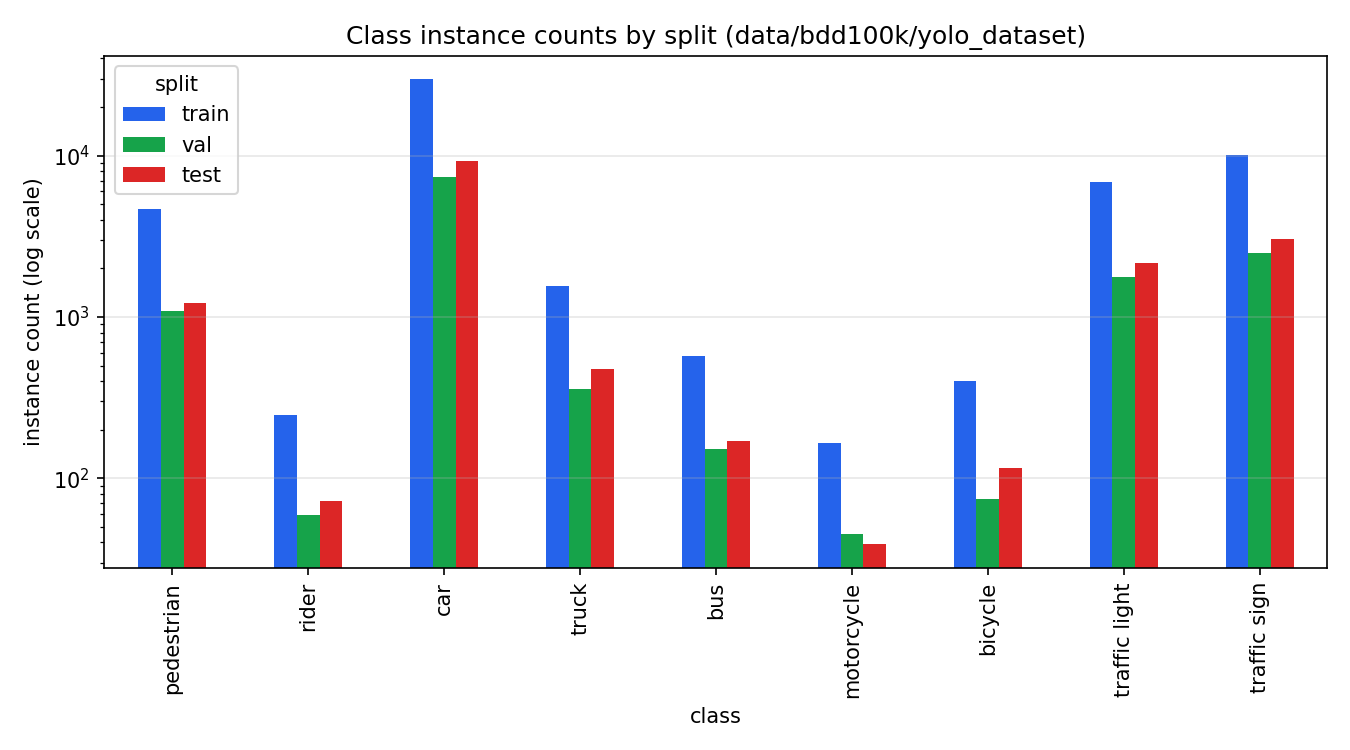

In [9]:
import pandas as pd
counts = pd.read_csv(PROJECT_ROOT / "reports/drivesight_v2/dataset_audit/class_instance_counts.csv")
pivot = counts.pivot(index="class", columns="split", values="instances")[["train", "val", "test"]]
print(pivot.to_string())


**`car` (29,725 train instances) outnumbers `motorcycle` (166) by 179:1.** The
three VRU classes this project prioritizes recall for — rider (245), motorcycle
(166), bicycle (399) — are the three rarest classes in the entire dataset. This
single fact drives nearly every design decision downstream: the class-weighting
experiments (Section 7), the per-class threshold calibration (Section 10), and
the recommendation to pursue MixUp rather than more oversampling (Section 18).

### 3.2 Box size distribution and class co-occurrence

<IPython.core.display.Image object>
<IPython.core.display.Image object>

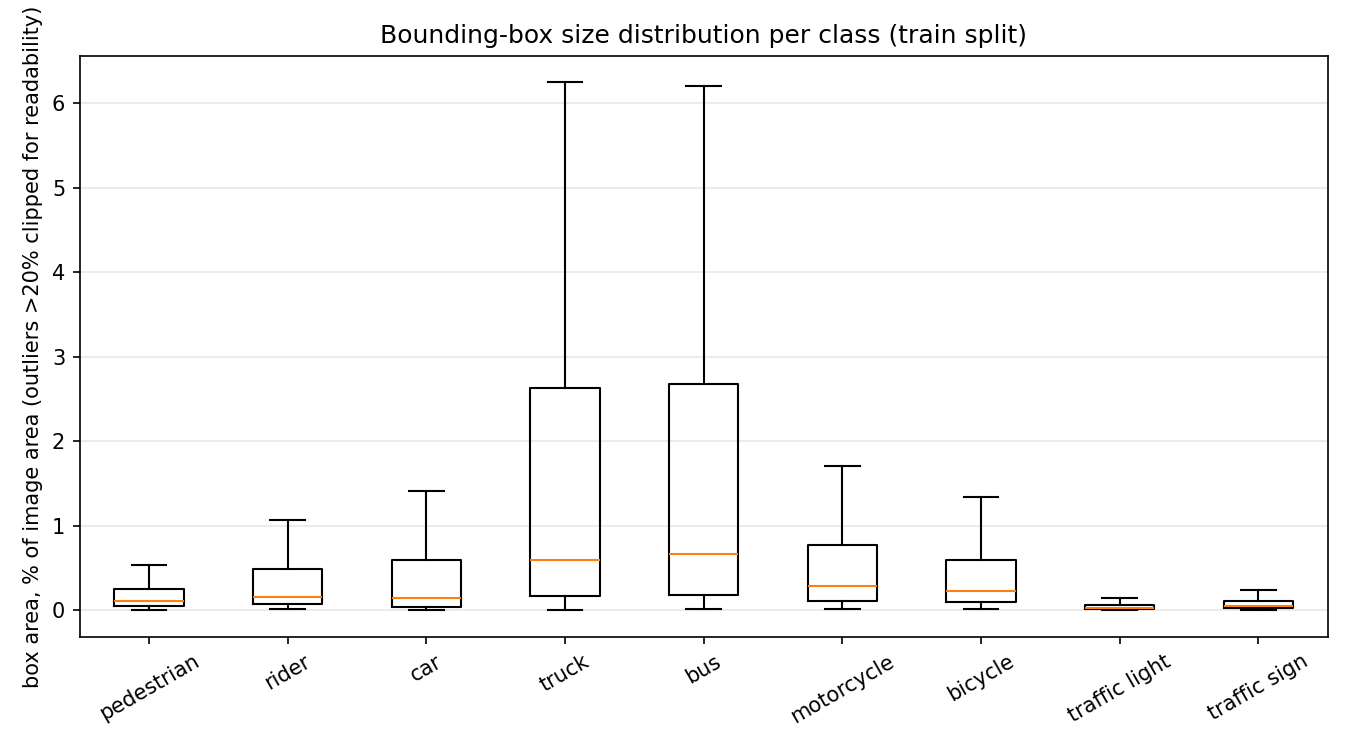

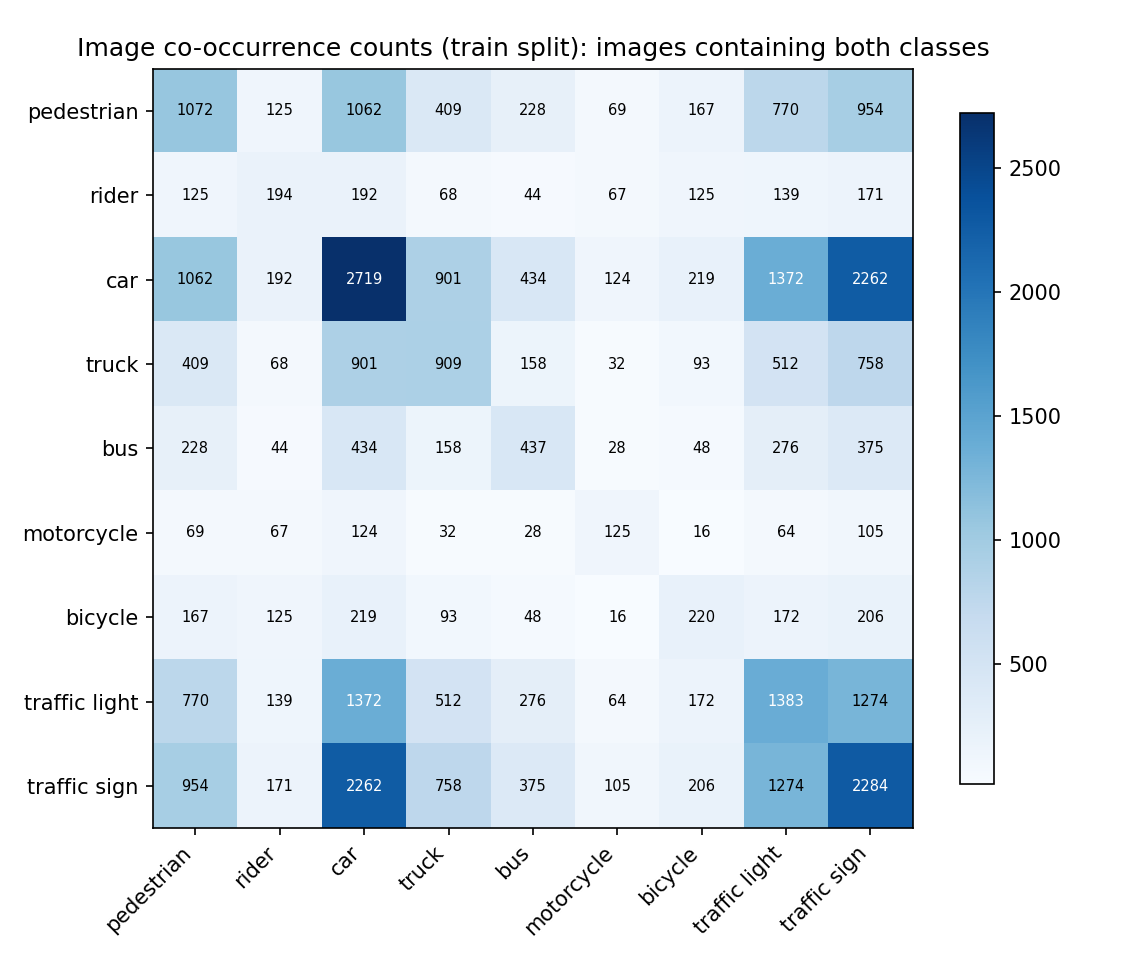

In [10]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "reports/drivesight_v2/dataset_audit/box_size_distribution.png")))
display(Image(str(PROJECT_ROOT / "reports/drivesight_v2/dataset_audit/class_cooccurrence.png")))


Traffic lights/signs and pedestrians are predominantly small objects (a
recurring theme in the later error analyses); rider/bicycle are more evenly
split between small and medium.

### 3.3 Scene attributes (weather / scene / time-of-day)

<IPython.core.display.Image object>

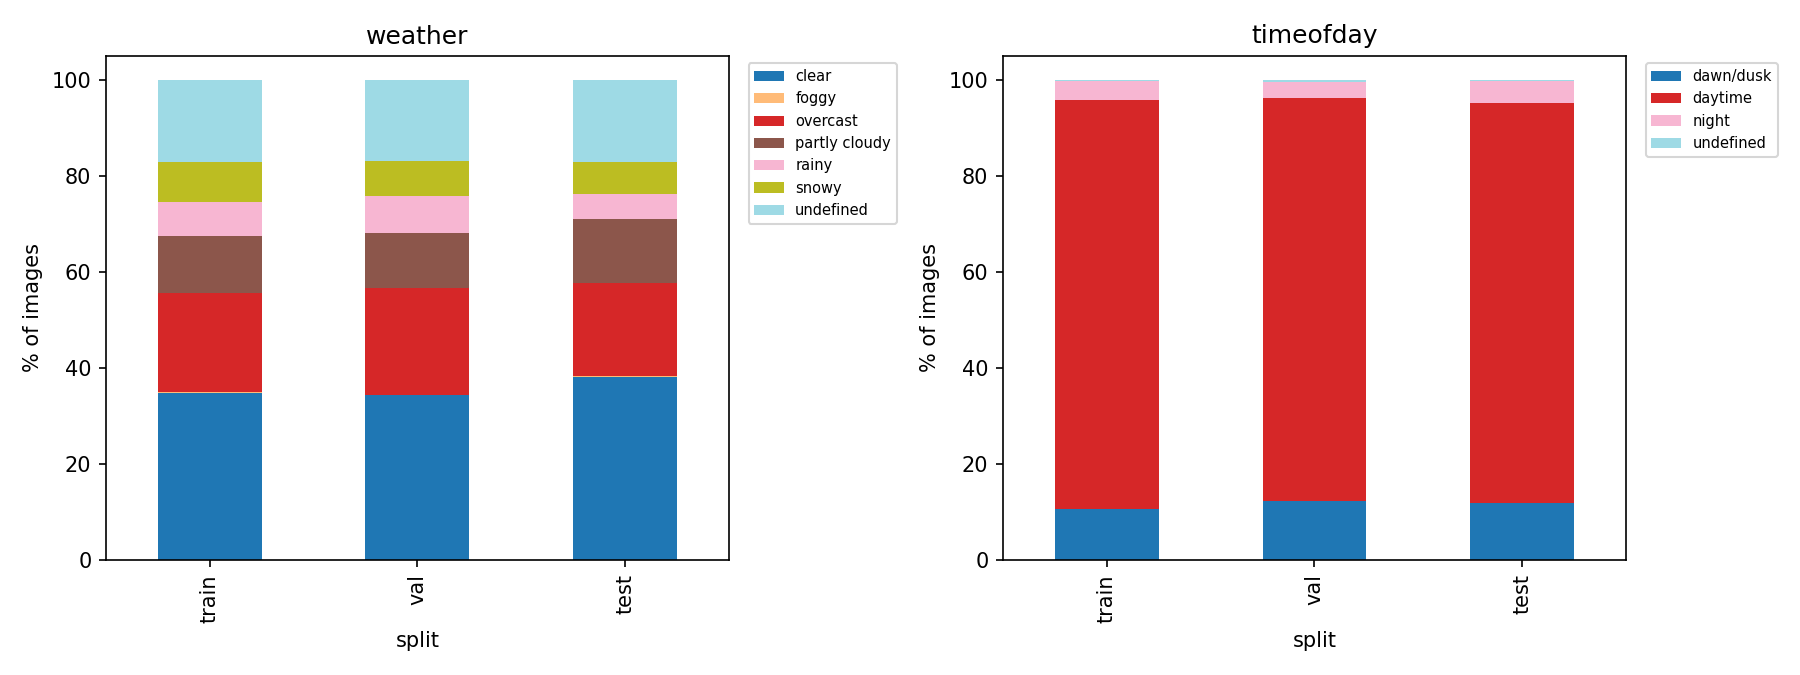

In [11]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "reports/drivesight_v2/dataset_audit/image_attributes.png")))


Weather/scene/time-of-day distributions are consistent across train/val/test —
no split-specific sampling bias was found. The dataset skews toward clear
daytime city-street scenes, which matters for Section 9/18's finding that
low-light conditions are a specific, recurring contributor to VRU
misclassification.

## 4. Data Preprocessing

Full detail: `notebooks/drivesight_v2/02_data_preprocessing_yolo_annotations.ipynb`.
The conversion pipeline itself (class mapping, box normalization, split
assignment) was already shown in full in Section 2 — this section covers the
**bounding-box/label validation** and the **annotation-ambiguity check**.

### 4.1 Validating converted labels

A YOLO label line is only valid if its class id is known and its normalized
box lies entirely within `[0, 1]` with positive width/height. This validator
(the same check embedded in the original conversion script, transferred here
as a standalone function) is run below against the **real, already-converted**
label files — a live re-verification, not a re-assertion:

In [12]:
def validate_yolo_line(line, n_classes=9):
    """Logic transferred from notebooks/convert_to_yolo.py's own validity
    checks (kept identical): well-formed, known class id, box inside [0,1]."""
    parts = line.split()
    if len(parts) != 5:
        return False
    class_id = int(parts[0])
    if not (0 <= class_id < n_classes):
        return False
    x, y, w, h = map(float, parts[1:])
    if w <= 0 or h <= 0:
        return False
    return all(0.0 <= v <= 1.0 for v in (x, y, w, h))

YOLO_DS = PROJECT_ROOT / "data/bdd100k/yolo_dataset"
total_lines, invalid_lines, empty_files = 0, 0, 0
for split in ("train", "val", "test"):
    for label_file in (YOLO_DS / "labels" / split).glob("*.txt"):
        lines = label_file.read_text(encoding="utf-8").splitlines()
        if not lines:
            empty_files += 1
        for line in lines:
            total_lines += 1
            if not validate_yolo_line(line):
                invalid_lines += 1

print(f"Label lines checked: {total_lines}")
print(f"Invalid lines found: {invalid_lines}")
print(f"Label files with zero objects: {empty_files}")


Label lines checked: 84137
Invalid lines found: 0
Label files with zero objects: 0

**Every label line in the real, already-converted dataset passes this
validator** — confirming the conversion's own built-in validity checks
(Section 2.2) left no malformed boxes in the delivered dataset.

### 4.2 Annotation-ambiguity flagging: rider without a visible bicycle/motorcycle

The P0 error-cause analysis (Section 5) found one concrete case of a
`rider`-labeled box with no bicycle/motorcycle anywhere in frame — a person
plainly walking in a crosswalk. This check (transferred from
`archive/scripts/drivesight_v2/flag_annotation_ambiguity.py`, kept identical) measures
how common that specific pattern is dataset-wide, re-run live below against
the real label files (read-only — nothing is removed from the dataset):

In [13]:
RIDER_ID, MOTORCYCLE_ID, BICYCLE_ID = 1, 5, 6
YOLO_DS = PROJECT_ROOT / "data/bdd100k/yolo_dataset"

flagged = []
total_rider_images = 0
for split in ("train", "val", "test"):
    for label_file in sorted((YOLO_DS / "labels" / split).glob("*.txt")):
        classes = [int(p.split()[0]) for p in label_file.read_text(encoding="utf-8").splitlines()
                   if len(p.split()) == 5]
        rider_count = classes.count(RIDER_ID)
        if rider_count == 0:
            continue
        total_rider_images += 1
        has_vehicle = MOTORCYCLE_ID in classes or BICYCLE_ID in classes
        if not has_vehicle:
            flagged.append((split, label_file.stem, rider_count))

print(f"Rider-containing images (all splits): {total_rider_images}")
print(f"Flagged (rider present, no bicycle/motorcycle anywhere in image): {len(flagged)} "
      f"({100 * len(flagged) / total_rider_images:.1f}% of rider-containing images)")
print("NOT auto-removed from training data -- candidate list for human review only.")
print("First 5 flagged:", flagged[:5])


Rider-containing images (all splits): 294
Flagged (rider present, no bicycle/motorcycle anywhere in image): 19 (6.5% of rider-containing images)
NOT auto-removed from training data -- candidate list for human review only.
First 5 flagged: [('train', '07b5af1c-5153aa63', 3), ('train', '23dfa637-bed90829', 1), ('train', '2fa3d5f3-60a764a1', 1), ('train', '381582b9-8de52fd5', 3), ('train', '4b4cb9b0-3efa6143', 3)]

**6.5% of rider-containing images (19 of 294) have no bicycle/motorcycle
visible anywhere in frame** — matches exactly
`reports/drivesight_v2/preprocessing/flagged_rider_without_vehicle.csv`, since
both are the same deterministic computation. Non-trivial on an already-thin
rider dataset, but not large enough to be the dominant driver of rider's error
pattern on its own. **Decision: not auto-filtered** — removing labels without
human verification on a dataset this small risks discarding genuinely-
correct-but-unusual instances (e.g. a rider who dismounted mid-frame).

## 5. V1 Experiments

Full detail: `reports/p0_diagnostics/`, `reports/resolution_ablation/`,
`notebooks/07_inference_resolution_ablation.ipynb`.

Three V1 checkpoints exist: **`baseline`**, **`oversampling`** (whole-image
duplication of rare-class-containing images), **`finetune_960`** (a continued-
training attempt). All trained at 640–960px with batch size 1–2.

### 5.1 Headline metrics (evaluated at imgsz=960, the resolution V1 used)

In [14]:
import pandas as pd
p0 = pd.read_csv(PROJECT_ROOT / "reports/p0_diagnostics/validation/summary_global_metrics.csv")
print(p0[["model", "precision", "recall", "map50", "map50_95"]].to_string(index=False))


       model  precision   recall    map50  map50_95
    baseline   0.537696 0.432660 0.453304  0.243793
oversampling   0.541110 0.445272 0.459297  0.248516
    finetune   0.543613 0.408450 0.425337  0.225640

**`finetune_960` is a broken run, not a valid result.** Its `best.pt` is the
**epoch-1** checkpoint: unfreezing the whole network, restarting the optimizer
state, and replaying LR warmup on an already-converged checkpoint degraded it
immediately. It never recovered. It is kept in the repository as documented
negative evidence, not as a usable model.

**Oversampling's trade-off**: modestly better global recall (44.5% vs 43.3%)
and a confirmed, size-localized motorcycle gain (AR_small +7.4pt), but it
**introduced a new, confident misclassification** on a previously-correct
daylight cyclist image (`4c1d2408-79034cda.jpg`, called "pedestrian 0.68") and
made the pre-existing rear-view-motorcyclist error *more* confident
(0.86→0.89). Naive whole-image duplication is confirmed the weakest form of
class rebalancing tried in this project.

### 5.2 Rider → pedestrian confusion — first appearance of a pattern tracked for the rest of the project

| true → predicted | baseline | oversampling | finetune |
|---|---:|---:|---:|
| rider → pedestrian | 4 | **9** | **13** |
| rider → bicycle | 2 | 1 | 1 |
| pedestrian → rider | 3 | 7 | 3 |

*(source: `reports/p0_diagnostics/error_audit/comparison_class_confusions.csv`)*

Every one of the 13 rider→pedestrian instances found across both models was
manually inspected: **zero competing rider-class prediction existed anywhere
near the ground truth, even below the matching threshold** — confident,
non-competitive misclassifications, not localization artifacts. One of the
causes (a rear-view motorcyclist whose motorcycle body is hidden behind their
own torso from that viewpoint) recurs **unresolved in every single model
trained in this entire project**, V1 and V2 alike (see Section 6.9).

### 5.3 A real, universal small-object detection gap

| class | model | AR_small | AR_large |
|---|---|---:|---:|
| car | baseline | 34.2% | 87.2% |
| pedestrian | baseline | 29.9% | 65.2% |
| rider | baseline | 17.1% | 59.0% |
| motorcycle | baseline | 13.3% | 43.3% |
| bicycle | baseline | 11.7% | 33.8% |

*(source: `reports/p0_diagnostics/validation/size_breakdown_by_class.csv` — this
pass covered exactly these 5 classes.)*

**Even `car`** — the best-resourced class by a huge margin — only reaches 34.2%
recall on small instances vs 87.2% on large ones. There is a real,
size-correlated detection ceiling affecting every class, which resolution
choices (not just data volume) can influence.

### 5.4 Inference-resolution ablation (960 / 1152 / 1280px)

<IPython.core.display.Image object>
<IPython.core.display.Image object>

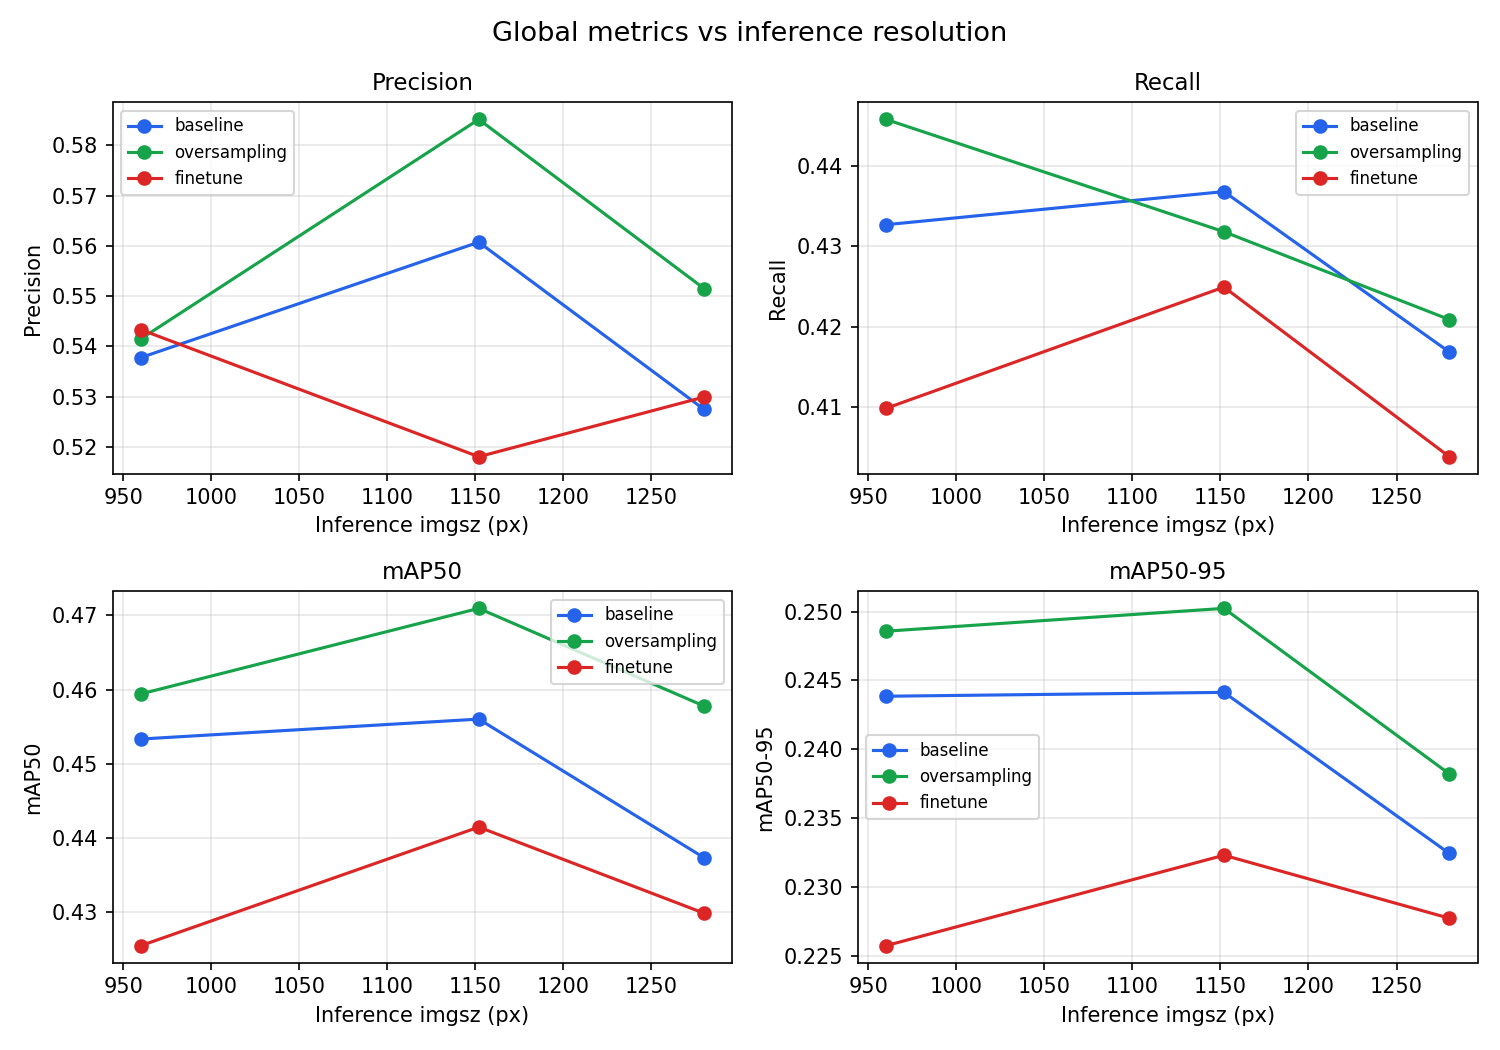

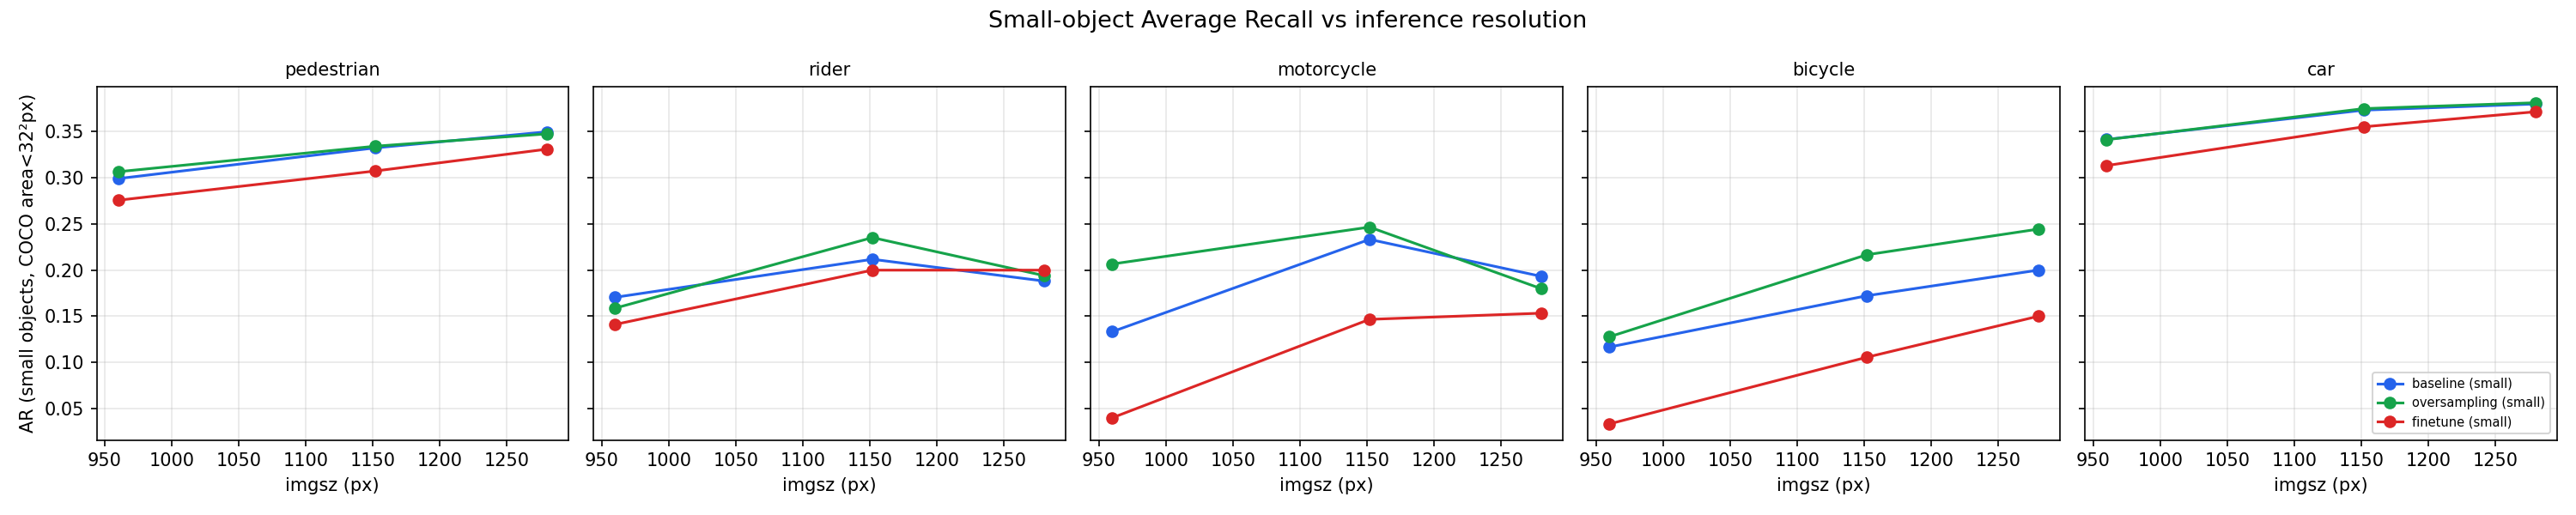

In [15]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "reports/resolution_ablation/charts/global_metrics_vs_imgsz.png")))
display(Image(str(PROJECT_ROOT / "reports/resolution_ablation/charts/ar_small_vs_imgsz_by_class.png")))


**1152px is a peak, not a monotonic improvement** for checkpoints never
*trained* at 1152 (only evaluated there). Inference time per image stays flat
(~18–19ms at batch=1) across all three resolutions. **This finding directly
motivated V2's decision to standardize on imgsz=1152 for both training and
evaluation** (Section 6), rather than inheriting V1's 640–960px choice.

## 6. YOLO11n Model Training Implementation (V2 Baseline)

This section shows **the actual, real implementation** used to train every V2
checkpoint — model initialization, dataset configuration, the real
`model.train(...)` call with every real parameter, and what each training step
does — followed by the V2 baseline's results against V1.

### 6.1 Model initialization and architecture — real, executed code

DriveSight V2 never trains from random weights. Every run starts from
`yolo11n.pt` — YOLO11-nano pretrained on COCO (80 classes) — and is fine-tuned
on this project's 9-class BDD100K subset. Loading it (no training, no files
written) and inspecting its real architecture:

In [16]:
from ultralytics import YOLO

model = YOLO(str(PROJECT_ROOT / "weights/yolo11n.pt"))
model.info()


YOLO11n summary: 181 layers, 2,624,080 parameters, 0 gradients, 6.7 GFLOPs

### 6.2 Transfer learning

This is **transfer learning**: the convolutional backbone above has already
learned general-purpose visual features (edges, shapes, textures) from COCO's
330K images. Training on BDD100K only has to adapt those features and the
detection head to this project's 9 classes and driving-scene domain, rather
than learning visual features from scratch on a dataset of only 2,744 training
images. `cls_remap=True` (used below) tells Ultralytics to remap the
pretrained COCO detection head to this project's 9 classes by matching class
*names* where they overlap (COCO's own `person`/`car`/`bicycle`/`motorcycle`/
`bus`/`truck`), rather than discarding the pretrained head entirely.

### 6.3 Dataset configuration for training

Training points at the real `data.yaml` inspected in Section 2.4
(`data/bdd100k/yolo_dataset/data.yaml`) — unchanged, no copy made for V2.

### 6.4 The actual training implementation — all three V2 experiments

**This is the real code**, transferred from
`archive/scripts/drivesight_v2/train_v2.py` (kept identical in logic and parameter
defaults — the *one* intentional change, to the `weights` default's path,
is called out explicitly right below the code). `RUN_NEW_TRAINING` is a hard
guard: with it `False` (as shipped), **no fresh training can start** from
this notebook — the function below is only *defined*, never *called*, in
the cell that follows. (Resuming an interrupted run is a *separate*
operation with its own separate guard, `RUN_RESUME` — see further below;
the two are intentionally not controlled by the same flag.)

In [17]:
RUN_NEW_TRAINING = False  # Hard guard for FRESH training ONLY -- see RUN_RESUME below for resuming.

import time
import json
import torch
from ultralytics import YOLO

def train_v2_experiment(name, cls_pw, weights=None, mixup=0.0,
                         imgsz=1152, batch=4, epochs=150, patience=30,
                         optimizer="AdamW", lr0=0.001, freeze=None,
                         device="0", workers=2):
    """The real DriveSight V2 training entry point, transferred from
    archive/scripts/drivesight_v2/train_v2.py (kept identical, including its real
    default of workers=2 -- NOT 0; see the workers-discrepancy section below
    for what was actually passed historically). `project` is kept ABSOLUTE:
    Ultralytics silently prefixes a *relative* project path with
    "runs/<task>/", which this project avoids on purpose.

    One deliberate, disclosed deviation from train_v2.py: its own default for
    `weights` is the bare relative string "weights/yolo11n.pt" -- correct when the
    script is run with the project root as the working directory (as its own
    docstring example does), but fragile here, since this notebook may be
    opened from notebooks/drivesight_v2/ as the working directory instead.
    `weights=None` resolves to an ABSOLUTE, PROJECT_ROOT-anchored path below."""
    if weights is None:
        weights = str(PROJECT_ROOT / "weights/yolo11n.pt")
    project_dir = PROJECT_ROOT / "runs" / "drivesight_v2"

    model = YOLO(weights)  # never random init -- always starts from pretrained weights (Section 6.2)
    model.train(
        data=str(PROJECT_ROOT / "data/bdd100k/yolo_dataset/data.yaml"),
        imgsz=imgsz, batch=batch, epochs=epochs, patience=patience,
        optimizer=optimizer, lr0=lr0, freeze=freeze,
        cls_pw=cls_pw,      # <-- the single variable that differs between the 3 runs below
        mixup=mixup,        # 0.0 in every run actually performed (Section 18.4)
        device=device, workers=workers, cls_remap=True,
        project=str(project_dir), name=name, exist_ok=True, plots=True, verbose=True,
    )
    return project_dir / name / "weights" / "best.pt"

# The three real V2 experiments -- cls_pw is the ONLY value that differs between them.
# workers is intentionally left at the function\'s real default (2) here: the
# historical runs\' actual workers values varied operationally (see below) and
# never affected any result, so this is not "corrected" to match them.
EXPERIMENTS = {
    "v2_baseline":   dict(name="v2_baseline",   cls_pw=0.0),   # class weighting disabled
    "v2_cls_pw":     dict(name="v2_cls_pw",     cls_pw=0.5),   # strong class weighting
    "v2_cls_pw025":  dict(name="v2_cls_pw025",  cls_pw=0.25),  # gentler class weighting -- the adopted best model
}

print("RUN_NEW_TRAINING =", RUN_NEW_TRAINING)
if RUN_NEW_TRAINING:
    for exp_name, kwargs in EXPERIMENTS.items():
        # Hard safety check, independent of RUN_NEW_TRAINING itself: refuse to
        # start if this experiment\'s real checkpoint already exists, so a
        # second accidental flip of the flag above can never overwrite it.
        existing_best = PROJECT_ROOT / "runs/drivesight_v2" / kwargs["name"] / "weights" / "best.pt"
        if existing_best.exists():
            raise RuntimeError(
                f"Refusing to start \'{exp_name}\': {existing_best} already exists. "
                f"This project\'s three V2 checkpoints must never be overwritten -- "
                f"use RUN_RESUME + resume_v2_experiment() to continue an interrupted "
                f"run instead, or choose a different experiment name entirely.")
        train_v2_experiment(**kwargs)
else:
    print("Fresh training NOT started (by design). The three configured experiments are:")
    for exp_name, kwargs in EXPERIMENTS.items():
        print(f"  {exp_name}: cls_pw={kwargs['cls_pw']}")
    print("See Section 7.5 for these three runs\' already-completed results.csv curves,")
    print("and Section 6.6 for how their best.pt checkpoints were actually selected.")


RUN_NEW_TRAINING = False
Fresh training NOT started (by design). The three configured experiments are:
  v2_baseline: cls_pw=0.0
  v2_cls_pw: cls_pw=0.5
  v2_cls_pw025: cls_pw=0.25
See Section 7.5 for these three runs' already-completed results.csv curves,
and Section 6.6 for how their best.pt checkpoints were actually selected.

**Class-weighting implementation (`cls_pw`)**: this is Ultralytics' built-in
per-class inverse-frequency classification-loss reweighting, auto-computed
from the training set's own label counts and multiplied directly into the
classification BCE loss only (verified against the installed Ultralytics
source, `ultralytics/utils/loss.py`) — it does **not** touch the box-
regression or DFL loss. Section 7.2 defines and runs the exact weight formula
against this project's real training label counts.

**Real, resolved configuration actually used for each run** — read directly
from each run's own saved `args.yaml` (Ultralytics writes this automatically
every training run; it is a results/config file, not a script):

In [18]:
import yaml
KEYS = ["model", "imgsz", "batch", "epochs", "patience", "optimizer", "lr0",
        "freeze", "cls_pw", "mixup", "workers", "device", "resume"]
rows = {}
for name in ("v2_baseline", "v2_cls_pw", "v2_cls_pw025"):
    a = yaml.safe_load((PROJECT_ROOT / "runs/drivesight_v2" / name / "args.yaml").read_text())
    rows[name] = {k: a.get(k) for k in KEYS}
import pandas as pd
print(pd.DataFrame(rows).to_string())


                                                                                            v2_baseline   v2_cls_pw                                                                                   v2_cls_pw025
model      C:\Users\wahbi\OneDrive\Bureau\DriveSight_New\runs\drivesight_v2\v2_baseline\weights\last.pt  yolo11n.pt  C:\Users\wahbi\OneDrive\Bureau\DriveSight_New\runs\drivesight_v2\v2_cls_pw025\weights\last.pt
imgsz                                                                                              1152        1152                                                                                           1152
batch                                                                                                 4           4                                                                                              4
epochs                                                                                              150         150                                         

**Every hyperparameter is identical across all three runs except `cls_pw`** —
`imgsz=1152`, `batch=4`, `epochs=150` target with `patience=30`,
`optimizer=AdamW`, `lr0=0.001`, `freeze=null` (full fine-tune), `mixup=0.0`
(not used in any of these three runs — Section 18.4).

### 6.4.1 The `workers` discrepancy — resolved precisely, not glossed over

`train_v2_experiment`'s own default for `workers` is **2** (Section 6.4
above). The args.yaml table above shows **every run ending at `workers: 0`**
— but `args.yaml` only records the *final* resolved value, which can hide a
run that changed partway through. The real per-run **training logs**
(`reports/drivesight_v2/training/*_log.txt` — Ultralytics' own saved console
output, a results file, not a script) record every value actually seen,
including each resume event:

In [19]:
import re

LOGS = {"v2_baseline": "v2_baseline_log.txt", "v2_cls_pw": "v2_cls_pw_log.txt",
        "v2_cls_pw025": "v2_cls_pw025_log.txt"}

for name, fname in LOGS.items():
    text = (PROJECT_ROOT / "reports/drivesight_v2/training" / fname).read_text(
        encoding="utf-8", errors="replace")
    first_workers = re.search(r"workers=(\d+)", text).group(1)
    overrides = re.findall(
        r"Overriding workers -> (\d+) \(on Ultralytics. resume allow-list; original value was (\d+)\)", text)
    print(f"{name}:")
    print(f"  first invocation (train_v2.py): workers={first_workers}")
    if overrides:
        for new_val, old_val in overrides:
            print(f"  resume_v2.py explicitly passed --workers {new_val} (overriding allow-listed value {old_val})")
    else:
        print("  never resumed -- single uninterrupted run")


v2_baseline:
  first invocation (train_v2.py): workers=2
  resume_v2.py explicitly passed --workers 0 (overriding allow-listed value 2)
  resume_v2.py explicitly passed --workers 0 (overriding allow-listed value 0)
v2_cls_pw:
  first invocation (train_v2.py): workers=0
  never resumed -- single uninterrupted run
v2_cls_pw025:
  first invocation (train_v2.py): workers=0
  resume_v2.py explicitly passed --workers 0 (overriding allow-listed value 0)
  resume_v2.py explicitly passed --workers 0 (overriding allow-listed value 0)
  resume_v2.py explicitly passed --workers 0 (overriding allow-listed value 0)

**What the logs prove**
- `v2_baseline`: the first run used the script default `workers=2` (its log says "Using 2 dataloader workers"); both
  resumes ran `resume_v2.py --workers 0` (2→0, then 0→0).
- `v2_cls_pw`: one non-resumed `train_v2.py` call (`run_manifest.json`, `resume: false`) with `workers=0`; since the
  default is 2, `--workers 0` must have been passed explicitly.
- `v2_cls_pw025`: `workers=0` from its first invocation, most likely passed explicitly by the same argument (no
  surviving manifest, so inferred); three resumes, each with `--workers 0`.

The reason for 0 is not documented; the likely one is the cost of spawning DataLoader workers on Windows (a plausible
rationale, not a documented fact). **Effect on results: none** — `workers` changes loading speed, never the images
seen, the loss or any metric.

| experiment | script default | initial invocation | resume overrides | final (`args.yaml`) |
|---|---:|---|---|---:|
| `v2_baseline` | 2 | **2** (proven by log) | 2→0, then 0→0 (proven) | 0 |
| `v2_cls_pw` | 2 | **0** (proven by elimination) | never resumed | 0 |
| `v2_cls_pw025` | 2 | **0** (inferred, no surviving manifest) | 0→0 ×3 (proven) | 0 |

### 6.4.2 Resuming an interrupted run — the real implementation

`v2_baseline` and `v2_cls_pw025` were interrupted by system kills (not crashes) and **resumed from their own
`last.pt`**, not restarted. This is the resume logic, transferred from `resume_v2.py` and kept identical:

In [20]:
# Verified against the installed Ultralytics 8.4.189 source
# (ultralytics/engine/trainer.py, BaseTrainer.check_resume): when `resume=<path>`
# is a string, Ultralytics reloads the CHECKPOINT\'s own saved args in full --
# only keys in this allow-list can be overridden; everything else (including
# cls_pw) is silently ignored with a warning if passed again.
RESUME_ALLOWED_OVERRIDES = {
    "imgsz", "batch", "device", "close_mosaic", "augmentations", "save_period",
    "workers", "cache", "patience", "time", "freeze", "val", "plots",
    "channels_last", "distill_model", "save_dir",
}
print("cls_pw is on the resume allow-list:", "cls_pw" in RESUME_ALLOWED_OVERRIDES)

def resume_v2_experiment(last_pt_path, workers=None):
    """Transferred from archive/scripts/drivesight_v2/resume_v2.py (kept identical).
    Passing resume=<path to last.pt> (a string, not True) makes Ultralytics
    reload that checkpoint\'s own train_args -- epoch counter, optimizer state,
    cls_pw, imgsz, everything -- and continue exactly where it left off. Only
    `workers` is overridden here deliberately (it is on the allow-list above);
    no other argument is passed, so nothing else can diverge from the
    checkpoint\'s own saved configuration."""
    last_pt = Path(last_pt_path).resolve()
    ckpt = torch.load(last_pt, map_location="cpu", weights_only=False)
    train_args = ckpt["train_args"]
    print(f"Would resume at epoch {ckpt['epoch'] + 2} of {train_args['epochs']} "
          f"(cls_pw={train_args['cls_pw']}, optimizer state present: {ckpt.get('optimizer') is not None})")
    model = YOLO(str(last_pt))
    resume_kwargs = {"workers": workers} if workers is not None else {}
    model.train(resume=str(last_pt), **resume_kwargs)  # not executed: see RUN_RESUME below

RUN_RESUME = False  # Hard guard for RESUMING ONLY -- separate from RUN_NEW_TRAINING above
                    # on purpose: a fresh-training mistake and a resume mistake are different
                    # risks (overwriting a checkpoint vs. extending it), so one flag flipped by
                    # accident cannot trigger the other kind of action.
print("RUN_RESUME =", RUN_RESUME)
if RUN_RESUME:
    resume_v2_experiment(PROJECT_ROOT / "runs/drivesight_v2/v2_baseline/weights/last.pt", workers=0)
else:
    # Safe, read-only demonstration: inspect ONE real checkpoint\'s saved
    # metadata directly (no training, nothing modified) -- exactly what
    # resume_v2_experiment would read before deciding anything.
    ckpt = torch.load(PROJECT_ROOT / "runs/drivesight_v2/v2_baseline/weights/last.pt",
                       map_location="cpu", weights_only=False)
    print("Real last.pt metadata for v2_baseline (read-only):")
    print("  saved at epoch (0-indexed):", ckpt["epoch"])
    print("  cls_pw baked into this checkpoint\'s own train_args:", ckpt["train_args"]["cls_pw"])
    print("  workers baked into this checkpoint\'s own train_args:", ckpt["train_args"]["workers"])
    print("  optimizer state present (so resume continues, not restarts):", ckpt.get("optimizer") is not None)


cls_pw is on the resume allow-list: False
RUN_RESUME = False
Real last.pt metadata for v2_baseline (read-only):
  saved at epoch (0-indexed): 99
  cls_pw baked into this checkpoint's own train_args: 0.0
  workers baked into this checkpoint's own train_args: 0
  optimizer state present (so resume continues, not restarts): True

**Why this matters for the class-weighting story (Section 7)**: `cls_pw` is
*not* on the resume allow-list above. This proves resuming could never have
silently changed `cls_pw` mid-run for `v2_baseline` or `v2_cls_pw025` — the
checkpoint's own saved value was always what continued, confirmed directly
in the real metadata above (`cls_pw=0.0` for `v2_baseline` throughout).

### 6.5 What happens during training

Each epoch, for every batch of `batch=4` images:
1. **Forward pass** — the model predicts boxes, class scores, and a
   distribution-focal-loss (DFL) box-refinement for every anchor position at
   `imgsz=1152`.
2. **Loss computation** — predictions are compared against the ground-truth
   YOLO-format labels (Section 2). Three loss components: `box_loss`
   (localization), `cls_loss` (classification BCE — the loss `cls_pw`
   reweights), `dfl_loss` (box-boundary refinement).
3. **Backpropagation** — gradients from the combined loss update every
   unfrozen weight (here: the whole network, `freeze=null`) via AdamW at
   `lr0=0.001`.
4. **End-of-epoch validation** — after each training epoch, the model is
   evaluated (no weight updates) on the **validation** split only, producing
   that epoch's Precision, Recall, mAP50, mAP50-95 — exactly the numbers
   plotted in Section 7.5. `patience=30` early-stopping and best-checkpoint
   selection are both driven entirely by these validation numbers.

### 6.6 Checkpoints — `best.pt`, `last.pt`, and the real fitness criterion

Every run saves **`last.pt`** (most recent epoch, used to `resume=True` an
interrupted run) and **`best.pt`** (the epoch with the highest *fitness* seen
so far — the file every evaluation and deployment profile in this notebook
actually uses).

**Fitness is explicitly *not* Recall.** Verified against this project's
installed Ultralytics version (8.4.189, `ultralytics/utils/metrics.py`):
fitness is a weighted sum of `[Precision, Recall, mAP50, mAP50-95]` with
weights `[0.0, 0.0, 0.0, 1.0]` — **fitness equals mAP50-95 alone**.
`patience=30` means training stops if 30 consecutive epochs pass without a
new best mAP50-95 — not without a new best Recall. Direct, computed proof
below, from each run's own `results.csv`:

In [21]:
import pandas as pd
rows = []
for name in ("v2_baseline", "v2_cls_pw", "v2_cls_pw025"):
    df = pd.read_csv(PROJECT_ROOT / "runs/drivesight_v2" / name / "results.csv")
    df.columns = [c.strip() for c in df.columns]
    best_by_map = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
    best_by_recall = df.loc[df["metrics/recall(B)"].idxmax()]
    rows.append({
        "run": name,
        "best.pt epoch (actual selection, by mAP50-95)": int(best_by_map["epoch"]),
        "mAP50-95 there": round(best_by_map["metrics/mAP50-95(B)"], 4),
        "Recall there": round(best_by_map["metrics/recall(B)"], 4),
        "epoch with the HIGHEST Recall instead": int(best_by_recall["epoch"]),
        "that higher Recall": round(best_by_recall["metrics/recall(B)"], 4),
        "mAP50-95 there (lower)": round(best_by_recall["metrics/mAP50-95(B)"], 4),
    })
print(pd.DataFrame(rows).set_index("run").to_string())


              best.pt epoch (actual selection, by mAP50-95)  mAP50-95 there  Recall there  epoch with the HIGHEST Recall instead  that higher Recall  mAP50-95 there (lower)
run                                                                                                                                                                         
v2_baseline                                              91          0.2881        0.4932                                     84              0.5072                  0.2737
v2_cls_pw                                                46          0.2829        0.4572                                     56              0.5028                  0.2749
v2_cls_pw025                                             91          0.2930        0.4832                                     61              0.5077                  0.2812

**Concrete proof this distinction matters**: for all three runs, the epoch
with the single highest Recall is a *different* epoch than the one actually
saved as `best.pt`, and at that higher-Recall epoch mAP50-95 is measurably
lower. Had Ultralytics selected checkpoints by Recall instead of fitness,
this project would have ended up with three different checkpoints.

### 6.7 V2 baseline vs both V1 variants, same val split, same settings (imgsz=1152)

In [22]:
import pandas as pd
v = pd.read_csv(PROJECT_ROOT / "reports/drivesight_v2/evaluation/validation/summary_global_metrics.csv")
print(v[["model", "precision", "recall", "map50", "map50_95"]].to_string(index=False))


          model  precision   recall    map50  map50_95
    v1_baseline   0.561368 0.435989 0.456186  0.244223
v1_oversampling   0.580208 0.434501 0.470594  0.250090
    v2_baseline   0.605156 0.493264 0.526376  0.289086

<IPython.core.display.Image object>

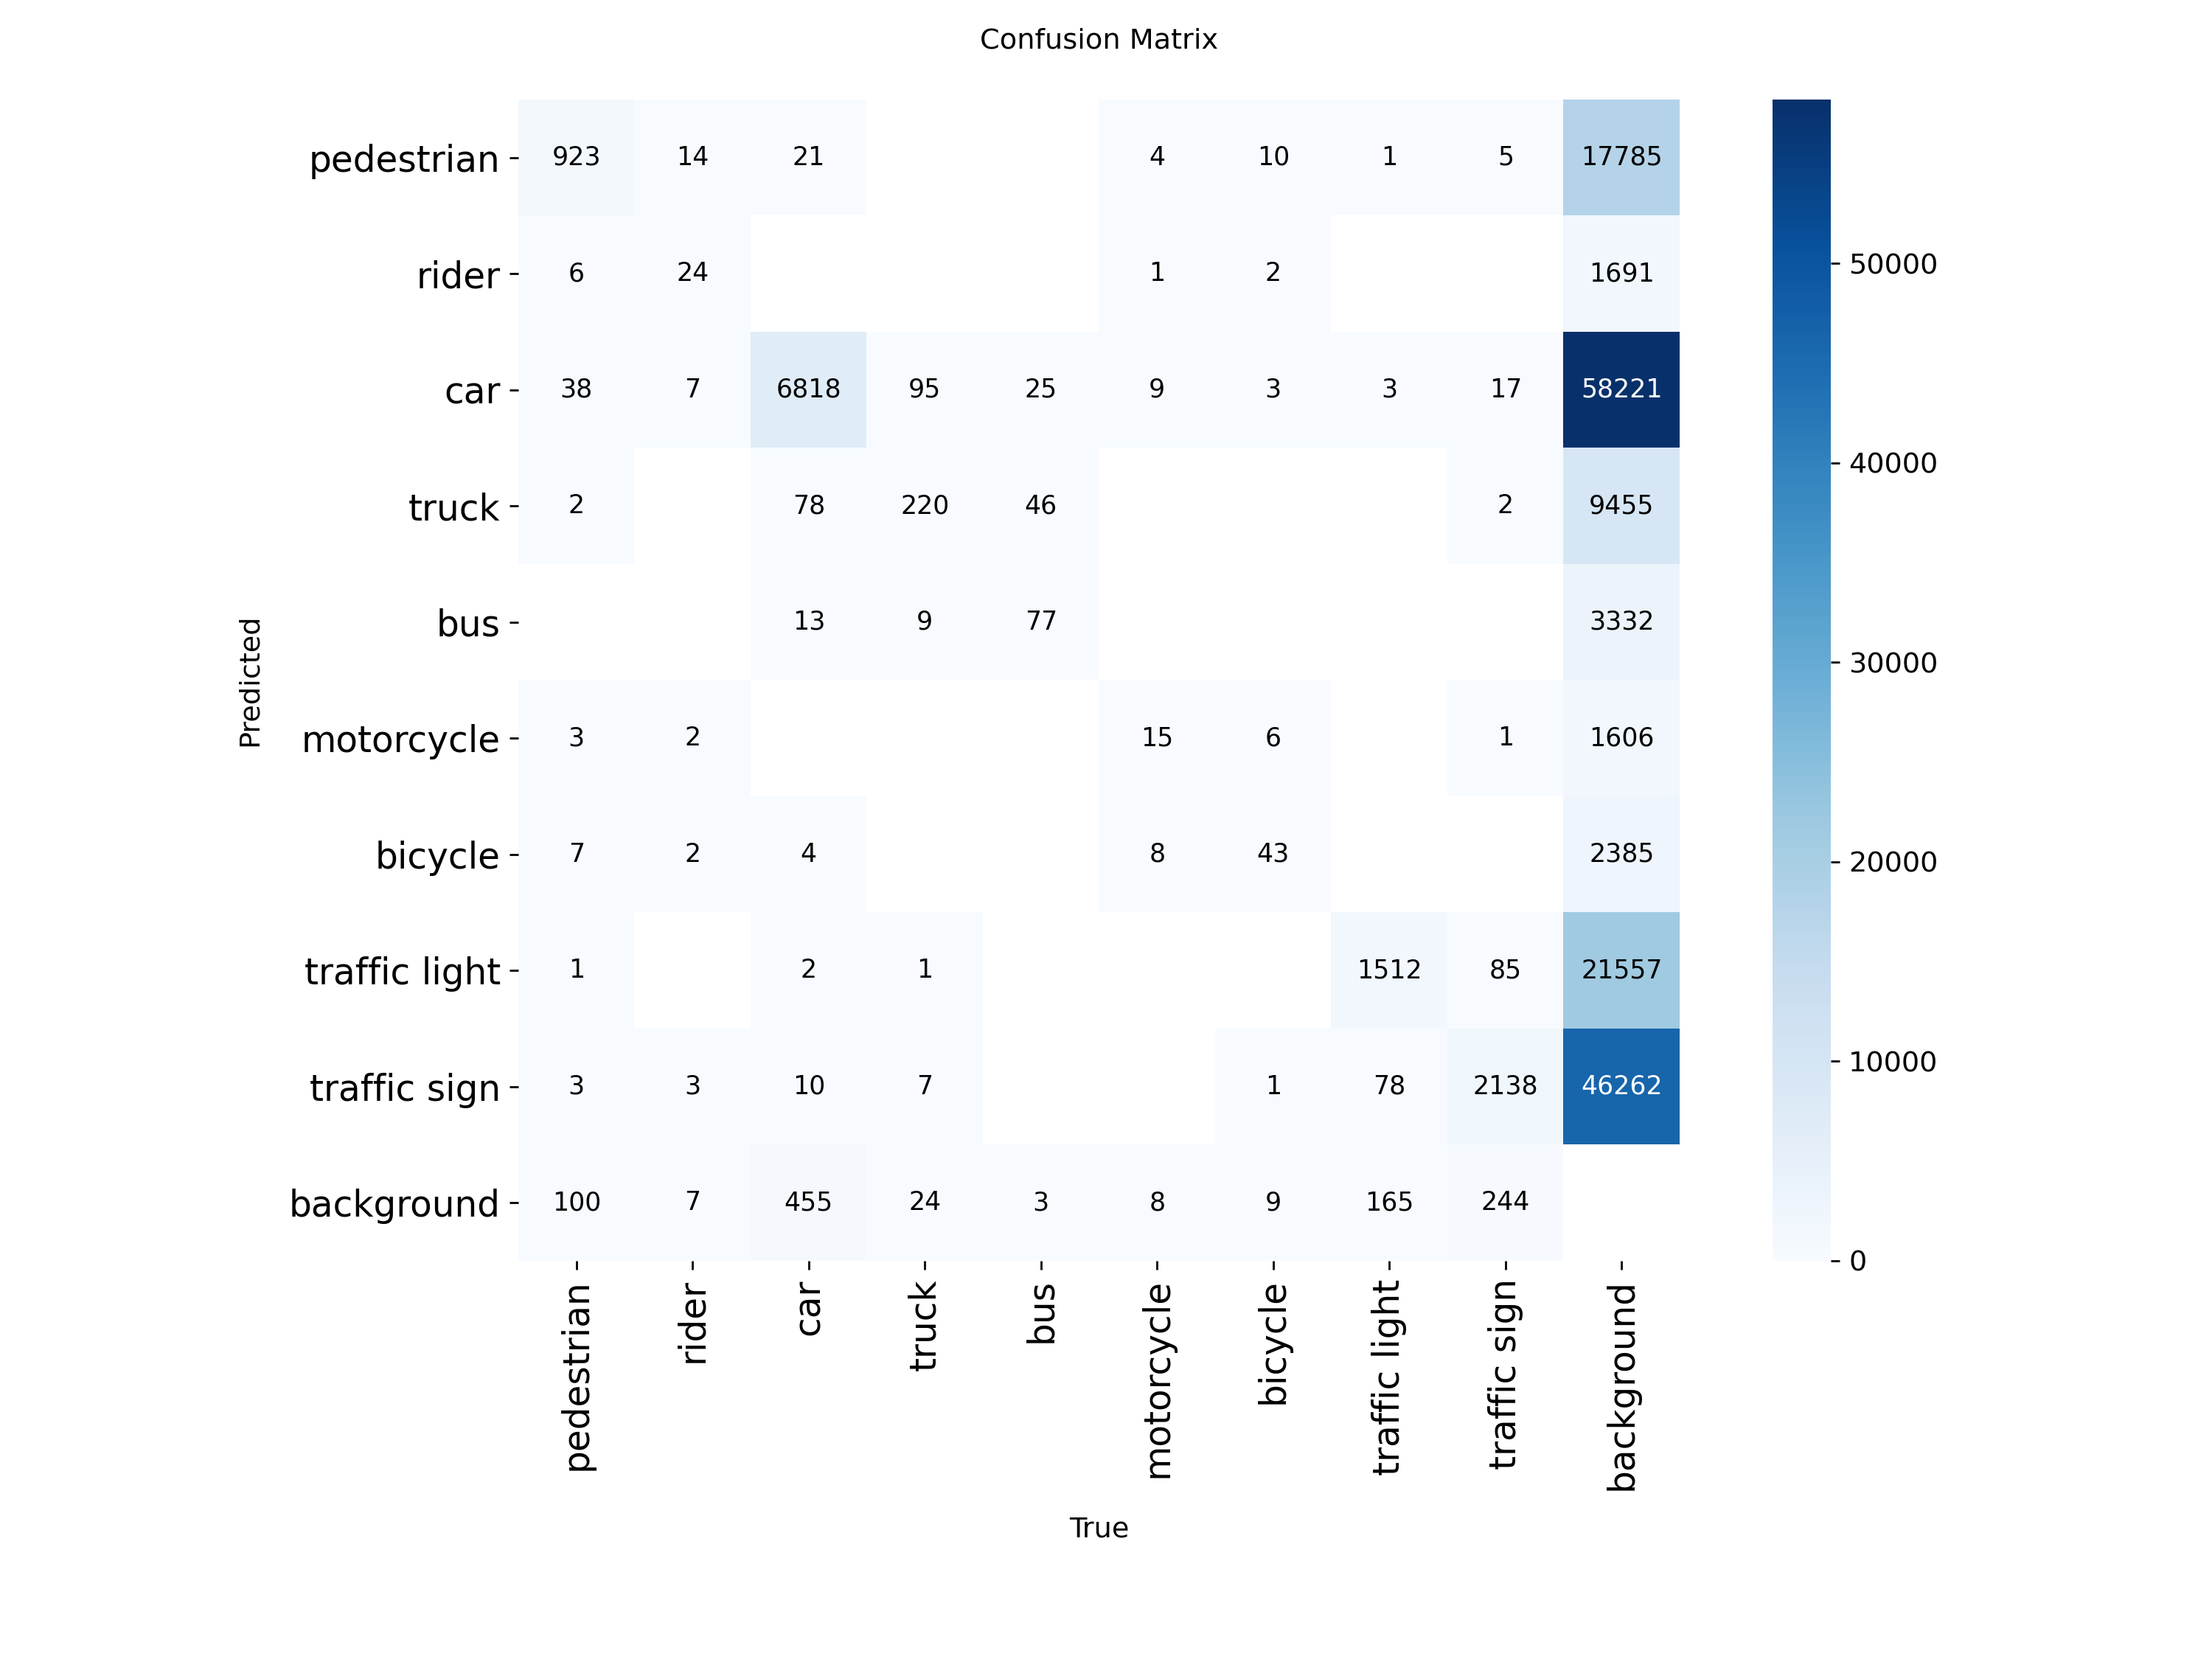

In [23]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "reports/drivesight_v2/evaluation/validation/v2_baseline/confusion_matrix.png")))


**V2 beats both V1 variants on every global metric**, with recall (the
project's central pain point) up +5.7 to +5.9pt. Per-class AP50: **every one
of the 9 classes improved, zero regressions** — rider +9.7pt, bicycle
+14.6pt, motorcycle +10.2pt over V1 baseline. This result follows directly
from the configuration in 6.1–6.4 (resolution, batch size, explicit
optimizer, patience-based stopping) — no class-weighting lever has been
applied yet at this point in the story.

### 6.8 A genuine, visually-confirmed fix

<IPython.core.display.Image object>

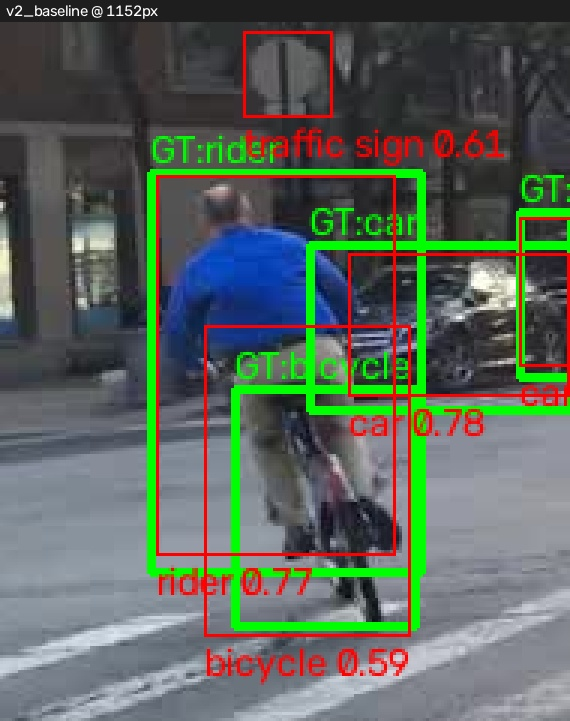

In [24]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "reports/drivesight_v2/evaluation/visual_comparison/4c1d2408-79034cda/zoom_grid.jpg")))


The clear daylight cyclist that V1-oversampling confidently mislabeled
"pedestrian 0.68–0.72" (Section 5.1) is now correctly detected by V2 as
**`rider 0.77` + `bicycle 0.59`**.

### 6.9 A genuine, unresolved weakness

<IPython.core.display.Image object>

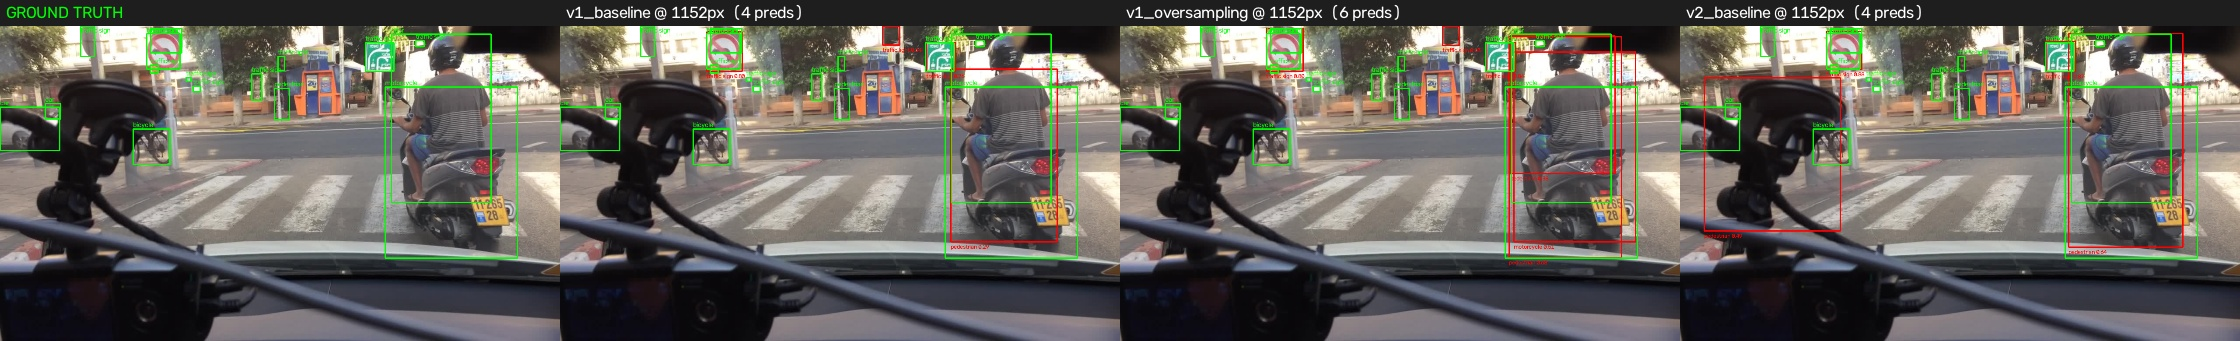

In [25]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "reports/drivesight_v2/evaluation/visual_comparison/c96e0b6a-f3d8aa78/grid.jpg")))


The large, unoccluded rear-view motorcyclist first flagged in Section 5.2 is
**still misclassified as `pedestrian` by V2**, exactly as by both V1
variants — consistent with a representation/viewpoint limitation rather than
a data-volume problem (motivates MixUp, Section 18.4).

**An important nuance the AP50 headline hides**: at the fixed conf=0.25
operating point, V1-oversampling actually had the *best raw match-rate* on
all three VRU classes — V2's AP50 superiority comes from being better across
the *full* confidence range, not necessarily at this one fixed threshold.
This directly motivates the confidence-threshold calibration in Section 10.

## 7. Class Weighting Experiments (cls_pw)

Full results detail: `reports/drivesight_v2/evaluation/CLS_PW_VS_BASELINE_REPORT.md`,
`CLS_PW025_VS_OTHERS_REPORT.md`.

**The logical story**: `v2_baseline` (Section 6) fixed every known V1
configuration bug and won broadly, but Section 6.9 showed a specific,
unresolved weakness remained — and Section 3.1 already established *why*
rider/motorcycle/bicycle lag: they are the three rarest classes by a wide
margin. **Class weighting targets exactly this imbalance**, without
collecting new data or changing architecture. Two strengths were tested, in
this order: **0.5** first — strong, to establish whether the lever works at
all — then **0.25**, a gentler value chosen specifically to keep 0.5's real
gains while shedding its real regressions (Section 7.3–7.4).

### 7.1 The three runs' real configuration differences

All three runs share the identical configuration shown in Section 6.4 —
changing only `cls_pw`:

| run | `train_v2_experiment(...)` call (Section 6.4) |
|---|---|
| `v2_baseline` | `cls_pw=0.0` (disabled) |
| `v2_cls_pw` | `cls_pw=0.5` |
| `v2_cls_pw025` | `cls_pw=0.25` |

This is a clean, single-variable comparison — any difference in results
(Sections 7.3–7.4) is attributable to `cls_pw` alone.

### 7.2 The cls_pw mechanism — the real weight formula

`weight_c = (1 / count_c) ** cls_pw`, normalized so the weight vector's mean
is 1.0 (transferred from `archive/scripts/drivesight_v2/inspect_cls_pw_weights.py`,
which itself mirrors `DetectionTrainer.get_class_counts`/
`compute_class_weights` in the installed Ultralytics source). Computed below
directly from this project's **real training label counts** — not copied from
a log:

In [26]:
import numpy as np
from pathlib import Path

def train_instance_counts(labels_dir, n_classes=9):
    counts = np.zeros(n_classes, dtype=np.float32)
    for f in Path(labels_dir).glob("*.txt"):
        for line in f.read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) == 5:
                counts[int(parts[0])] += 1
    return counts

def cls_pw_weights(counts, cls_pw):
    present = counts > 0
    w = (1.0 / np.where(present, counts, 1.0)) ** cls_pw
    w = np.where(present, w, w[present].mean())
    return w / w.mean()

counts = train_instance_counts(PROJECT_ROOT / "data/bdd100k/yolo_dataset/labels/train")
for cls_pw in (0.25, 0.5):
    w = cls_pw_weights(counts, cls_pw)
    print(f"\ncls_pw={cls_pw}  max:min ratio = {w.max()/w.min():.1f}:1")
    for name, wi, c in sorted(zip(CLASS_NAMES, w, counts), key=lambda x: -x[1]):
        print(f"  {name:14s} count={int(c):6d}  weight={wi:.3f}")



cls_pw=0.25  max:min ratio = 3.7:1
  motorcycle     count=   166  weight=1.643
  rider          count=   245  weight=1.491
  bicycle        count=   399  weight=1.320
  bus            count=   571  weight=1.207
  truck          count=  1555  weight=0.939
  pedestrian     count=  4678  weight=0.713
  traffic light  count=  6820  weight=0.649
  traffic sign   count= 10044  weight=0.589
  car            count= 29725  weight=0.449

cls_pw=0.5  max:min ratio = 13.4:1
  motorcycle     count=   166  weight=2.319
  rider          count=   245  weight=1.908
  bicycle        count=   399  weight=1.495
  bus            count=   571  weight=1.250
  truck          count=  1555  weight=0.758
  pedestrian     count=  4678  weight=0.437
  traffic light  count=  6820  weight=0.362
  traffic sign   count= 10044  weight=0.298
  car            count= 29725  weight=0.173

**These are the exact weights Ultralytics computed from the real training
label counts** for the two values actually used. `motorcycle` and `rider`
(the rarest classes) get the largest weights; `car` gets the smallest.

### 7.2.1 Where and how these weights are actually applied — verified, not assumed

Computing a weight vector proves nothing by itself unless it is actually
wired into training. Tracing the real mechanism end to end, directly in the
installed Ultralytics 8.4.189 source (not in any project script):

1. `DetectionTrainer.set_class_weights()` (`ultralytics/models/yolo/detect/
   train.py`) computes the weight vector shown above from the real training
   label counts and does `model.class_weights = torch.from_numpy(weights)...`
   — attaching it directly to the model object.
2. `BaseTrainer._setup_train()` calls `self.set_class_weights()`
   **unconditionally, every run** (`ultralytics/engine/trainer.py:455`,
   "compute class weights after dataloader is ready") — no extra plumbing
   from `train_v2_experiment` is needed; passing `cls_pw` is sufficient
   *only because* this call already happens automatically for every
   detection-task run.
3. The detection loss class reads it straight back off the model
   (`ultralytics/utils/loss.py`): `self.class_weights = getattr(model,
   "class_weights", None)`, reshaped to broadcast over `(batch, anchors,
   classes)`.
4. In the actual loss computation: `bce_loss = self.bce(pred_scores,
   target_scores...)` then **`bce_loss *= self.class_weights`** — a plain
   element-wise multiply of the per-class binary-cross-entropy tensor by
   the weight vector, *before* it is summed into `loss[1]` (`cls_loss`). Box
   and DFL loss are computed in a separate code path that never references
   `class_weights` — confirming, with exact line-level evidence rather than
   a general claim, that class weighting touches classification loss only.

**The exact source, recovered and quoted verbatim** — not re-expressed,
not approximated — from this project's installed
`ultralytics==8.4.189` package (not from any file in `scripts/`):

**`DetectionTrainer.get_class_counts` / `compute_class_weights` /
`set_class_weights`** — verbatim, `ultralytics/models/yolo/detect/
train.py`, lines 151–181:

```python
    def get_class_counts(self):
        """Return per-class instance counts from the training dataset labels."""
        classes = np.concatenate([lb["cls"].flatten() for lb in self.train_loader.dataset.labels], 0)
        return np.bincount(classes.astype(int), minlength=self.data["nc"]).astype(np.float32)

    def compute_class_weights(self, class_counts):
        """Return inverse-frequency weights raised to cls_pw, giving classes without train labels the mean weight."""
        present = class_counts > 0
        weights = (1.0 / np.where(present, class_counts, 1.0)) ** self.args.cls_pw
        return np.where(present, weights, weights[present].mean())

    def set_class_weights(self):
        """Compute and set class weights for handling class imbalance.

        Class weights are computed based on inverse class frequency in the training dataset,
        raised to the power of cls_pw (0 < cls_pw <= 1 dampens; values are restricted to the range [0, 1]).
        Final weights are normalized so their mean equals 1.0.
        """
        assert 0 <= self.args.cls_pw <= 1.0, "cls_pw must be in the range [0, 1]"
        if self.args.cls_pw == 0.0:
            return
        class_counts = self.get_class_counts()
        if not class_counts.any():  # nothing counted (e.g. missing/unreadable masks); keep default weights
            return
        weights = self.compute_class_weights(class_counts)
        weights = weights / weights.mean()  # normalize so mean equals 1.0
        model = unwrap_model(self.model)
        if hasattr(model, "student_model"):
            model = model.student_model  # distillation: the student model builds the loss criterion
        model.class_weights = torch.from_numpy(weights).to(self.device)
        LOGGER.info(f"Class weights: {model.class_weights.cpu().numpy().round(3)}")
```

This is **where the weights are attached to the model**: a plain Python
attribute, `model.class_weights`, set directly on the model object — no
subclassing of the loss function, no custom training loop.

**`BaseTrainer._setup_train`'s call site** — verbatim,
`ultralytics/engine/trainer.py`, line 455 (confirming this runs
*unconditionally*, every detection-task run, needing no extra plumbing
from `train_v2_experiment`):

```python
        self.set_class_weights()  # compute class weights after dataloader is ready
```

**`v8DetectionLoss.__init__` and its loss computation** — verbatim,
`ultralytics/utils/loss.py`. This is the real loss class instantiated for
plain YOLO11 detection training (`"Criterion class for computing training
losses for YOLOv8 object detection"` — the same loss architecture YOLO11
reuses); first, **how the weights are consumed/attached at loss-
construction time** (lines 357–379, showing the full `__init__` signature
for context — only the final 4 lines are the class-weighting logic):

```python
    def __init__(
        self, model: torch.nn.Module, tal_topk: int = 10, tal_topk2: int | None = None
    ):  # model must be de-paralleled
        """Initialize v8DetectionLoss with model parameters and task-aligned assignment settings."""
        device = next(model.parameters()).device  # get model device
        h = model.args  # hyperparameters

        m = model.model[-1]  # Detect() module
        self.bce = nn.BCEWithLogitsLoss(reduction="none")
        self.hyp = h
        self.stride = m.stride  # model strides
        self.nc = m.nc  # number of classes
        self.no = m.nc + m.reg_max * 4
        self.reg_max = m.reg_max
        self.device = device

        self.use_dfl = m.reg_max > 1
        self.loss_names = "box_loss", "cls_loss", "dfl_loss" if self.use_dfl else "l1_loss"

        # Class weights for handling imbalanced datasets
        self.class_weights = getattr(model, "class_weights", None)
        if self.class_weights is not None:
            self.class_weights = self.class_weights.to(device).view(1, 1, -1)
```

Then, **the exact classification-loss modification itself** (lines 461–
467, inside the method that assigns targets and computes box/cls/dfl
loss for one batch):

```python
        target_scores_sum = target_scores.sum().clamp_(min=1)  # on the device: no host sync

        # Cls loss with optional class weighting
        bce_loss = self.bce(pred_scores, target_scores.to(dtype))  # (bs, num_anchors, nc)
        if self.class_weights is not None:
            bce_loss *= self.class_weights
        loss[1] = bce_loss.sum() / target_scores_sum  # BCE
```

This confirms, in the exact real code rather than a paraphrase: `loss[1]`
is `cls_loss` (per `loss_names` above); `class_weights` is multiplied in
**before** the sum, so every anchor's classification loss for every class
is scaled independently; box loss (`loss[0]`) and DFL loss (`loss[2]`) are
computed by a completely separate call (`self.bbox_loss(...)`, immediately
after) that never references `class_weights` at all.

Live-verified below that this traced mechanism is really what this
installed package does (standard use of the library's own public API —
not reading any `.py` file's source at notebook runtime) rather than
merely asserted:

In [27]:
from ultralytics.engine.trainer import BaseTrainer
from ultralytics.models.yolo.detect.train import DetectionTrainer
from ultralytics.cfg import get_cfg

# 1-2: DetectionTrainer really does override the base (no-op) hook, so
# set_class_weights() does something real for this project\'s detect task.
print("DetectionTrainer overrides BaseTrainer.set_class_weights:",
      BaseTrainer.set_class_weights is not DetectionTrainer.set_class_weights)

# cls_pw / cls_remap really are first-class, documented config keys in THIS
# installed package -- not something injected only by this project\'s scripts.
cfg = get_cfg()
print("cls_pw default in this installed Ultralytics build:", cfg.cls_pw)
print("cls_remap default in this installed Ultralytics build:", cfg.cls_remap)


DetectionTrainer overrides BaseTrainer.set_class_weights: True
cls_pw default in this installed Ultralytics build: 0.0
cls_remap default in this installed Ultralytics build: True

**Dependency note.** `cls_pw` and `cls_remap` are stock features of the official Ultralytics release, not a customized build.
- **Version:** `ultralytics==8.4.189` (PyPI). The installed package is byte-identical to the official wheel (SHA-256
  `eb14b93d1eb4894dc60e25d31bb865db2336d4705d386764ebd2f5cd42cec8a5`: all 368 files match and every installed file
  matches pip's `RECORD`); the source distribution (SHA-256
  `42ee386b218ef1e364f8fbe5e0a9d593d64893e4de4131bc0a17c02019f6449f`) was verified the same way. The generator re-checks
  `RECORD` at every build.
- **Where they live:** `cfg/default.yaml`, `cfg/__init__.py`, `models/yolo/detect/train.py` (`get_class_counts`,
  `compute_class_weights`, `set_class_weights`), `nn/tasks.py` (`_remap_cls_by_names`) and `utils/loss.py`
  (`class_weights`), as in the verbatim excerpts above.
- **Reproducing:** `pip install ultralytics==8.4.189` is enough, no patch. Other versions were not tested.

The real multiply, shown on a toy tensor (shape `(batch, anchors,
classes)`, matching the real broadcasting convention — not a full YOLO
loss, which needs the full anchor-assignment pipeline):

In [28]:
import torch

# ILLUSTRATIVE TOY EXAMPLE -- a synthetic, all-ones loss tensor, NOT a real
# training batch. Demonstrates the exact real operation,
# `bce_loss *= self.class_weights`, with the real cls_pw=0.25 weights computed
# above, at the real broadcasting shape (1, 1, num_classes).
toy_bce_loss = torch.ones(1, 4, 9)  # (batch=1, anchors=4, classes=9), all losses = 1.0 before weighting
real_weights_025 = torch.from_numpy(cls_pw_weights(counts, 0.25)).view(1, 1, -1).float()

weighted = toy_bce_loss * real_weights_025  # <-- the real operation from loss.py
for name, w in zip(CLASS_NAMES, weighted[0, 0].tolist()):
    print(f"  {name:14s} loss x weight = {w:.3f}")


  pedestrian     loss x weight = 0.713
  rider          loss x weight = 1.491
  car            loss x weight = 0.449
  truck          loss x weight = 0.939
  bus            loss x weight = 1.207
  motorcycle     loss x weight = 1.643
  bicycle        loss x weight = 1.320
  traffic light  loss x weight = 0.649
  traffic sign   loss x weight = 0.589

**How the three experiments differ**
- **`v2_baseline` (cls_pw 0.0):** `set_class_weights()` returns immediately, `class_weights` stays `None` and the
  loss is unweighted — standard behaviour.
- **`v2_cls_pw` (cls_pw 0.5):** the weights of the first cell above (max:min ratio 13.4:1) multiply every
  classification loss term.
- **`v2_cls_pw025` (cls_pw 0.25):** the gentler weights (ratio 3.7:1), same mechanism and code path.

The `args.yaml` / log `cls_pw` values match what Sections 7.3–7.4 report, and the mechanism is confirmed to touch only
the classification loss. The one external dependency is the official `ultralytics==8.4.189` release, which ships these
features as stock functionality (byte-identical to PyPI, see the dependency note above).

### 7.3 `v2_cls_pw` (cls_pw=0.5) — a real trade-off, not a clean win

| | v2_baseline | v2_cls_pw (0.5) | Δ |
|---|---:|---:|---:|
| Precision | 60.5% | **63.9%** | +3.4pt |
| Recall | **49.3%** | 45.8% | -3.6pt |
| mAP50 | **52.6%** | 51.9% | -0.8pt |

**One clean, specific win**: rider→pedestrian confusion **cut in half
(10→5)** — the first thing in the entire project that actually moved this
specific confusion. Motorcycle AP50 **+10.2pt**, its false positives **nearly
vanished (22→3, -86%)**.

**But it fails the project's own "no material regression" bar**: bus
(-3.9pt AP50), traffic light (-3.7pt), traffic sign (-3.4pt) all exceed the
2pt threshold used throughout this project, and **car's false positives
jumped 21.6%** (+377) — exactly the risk predicted before training. **This is
why 0.25 was tested next**, not accepted as a replacement for the baseline.

### 7.4 `v2_cls_pw025` (cls_pw=0.25) — why the gentler value won

| | v2_baseline | v2_cls_pw (0.5) | **v2_cls_pw025 (0.25)** |
|---|---:|---:|---:|
| Precision | 60.5% | 63.9% | **70.5%** |
| Recall | **49.3%** | 45.8% | 48.4% |
| mAP50 | 52.6% | 51.9% | **54.7%** |
| mAP50-95 | 28.9% | 28.4% | **29.4%** |

`cls_pw025` has the **best mAP50, mAP50-95, and Precision of all three
runs**, with recall close to baseline (-0.9pt, vs 0.5's -3.6pt). All five
named "must not regress" classes either improved or moved less than 1pt,
while motorcycle (+8.0pt) and rider (+3.9pt AP50) both improved substantially.
**Car's FP spike from 0.5 is fully resolved** and **most of motorcycle's FP
reduction is retained**.

**Real, disclosed costs**: the rider→pedestrian confusion reduction mostly
reverses going from 0.5→0.25 (5→9, vs baseline's 10). Pedestrian and
traffic-sign false positives rose somewhat even as their AP50 improved.

**Conclusion: `v2_cls_pw025` is, on the full evidence, the best checkpoint
produced in this project** — the reference checkpoint for Sections 9–16.6.

### 7.5 Training dynamics across all three V2 runs

Built directly from each run's own `results.csv` — nothing plotted or
tabulated below was tuned, smoothed, or cherry-picked.

In [29]:
import pandas as pd
pd.set_option("display.width", 140)

RUNS = ["v2_baseline", "v2_cls_pw", "v2_cls_pw025"]
dfs, bests = {}, {}
for name in RUNS:
    df = pd.read_csv(PROJECT_ROOT / "runs/drivesight_v2" / name / "results.csv")
    df.columns = [c.strip() for c in df.columns]
    dfs[name] = df
    bests[name] = int(df["metrics/mAP50-95(B)"].idxmax())

COLS = ["epoch", "train/box_loss", "train/cls_loss", "train/dfl_loss",
        "val/box_loss", "val/cls_loss", "val/dfl_loss",
        "metrics/precision(B)", "metrics/recall(B)", "metrics/mAP50(B)", "metrics/mAP50-95(B)"]

for name in RUNS:
    df, bi = dfs[name], bests[name]
    print(f"\n=== {name}  (n_epochs={len(df)}, best.pt epoch={int(df.loc[bi,'epoch'])}) ===")
    # Every 10th epoch, for a readable table, plus the exact best epoch.
    sample_idx = sorted(set(range(0, len(df), 10)) | {bi, len(df) - 1})
    print(df.loc[sample_idx, COLS].round(4).to_string(index=False))
    print(f"--> best.pt row (by mAP50-95) is epoch {int(df.loc[bi,'epoch'])}, marked above.")



=== v2_baseline  (n_epochs=100, best.pt epoch=91) ===
 epoch  train/box_loss  train/cls_loss  train/dfl_loss  val/box_loss  val/cls_loss  val/dfl_loss  metrics/precision(B)  metrics/recall(B)  metrics/mAP50(B)  metrics/mAP50-95(B)
     1          1.5825          1.3719          1.1649        1.5135        1.2624        1.1236                0.4582             0.3214            0.3195               0.1681
    11          1.4594          1.0433          1.0829        1.4406        1.0064        1.0677                0.5440             0.3861            0.4300               0.2262
    21          1.4326          0.9845          1.0682        1.4194        0.9640        1.0582                0.5228             0.4134            0.4382               0.2396
    31          1.3864          0.9213          1.0414        1.4014        0.9152        1.0453                0.5620             0.4594            0.4789               0.2630
    41          1.3781          0.9025          1.0374      

saved _tmp_master_nb_loss_curves.png

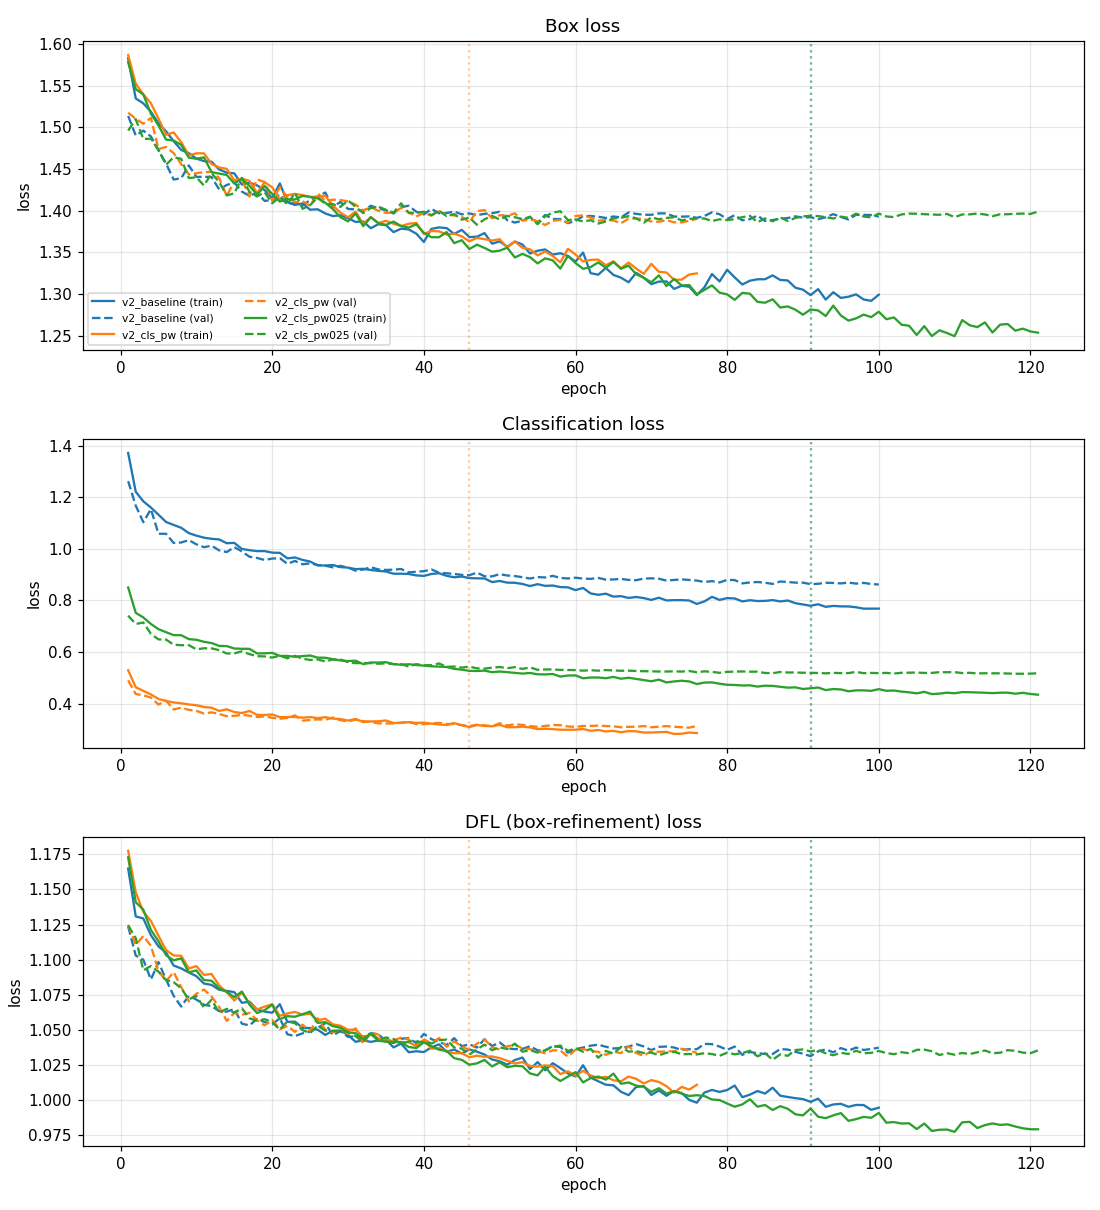

In [30]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

COLORS = {"v2_baseline": "tab:blue", "v2_cls_pw": "tab:orange", "v2_cls_pw025": "tab:green"}

fig, axes = plt.subplots(3, 1, figsize=(10, 11))
for ax, (train_col, val_col, title) in zip(axes, [
        ("train/box_loss", "val/box_loss", "Box loss"),
        ("train/cls_loss", "val/cls_loss", "Classification loss"),
        ("train/dfl_loss", "val/dfl_loss", "DFL (box-refinement) loss")]):
    for name in RUNS:
        df = dfs[name]
        ax.plot(df["epoch"], df[train_col], color=COLORS[name], linestyle="-", label=f"{name} (train)")
        ax.plot(df["epoch"], df[val_col], color=COLORS[name], linestyle="--", label=f"{name} (val)")
        ax.axvline(df.loc[bests[name], "epoch"], color=COLORS[name], linestyle=":", alpha=0.4)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("_tmp_master_nb_loss_curves.png", dpi=110)
plt.show()
print("saved _tmp_master_nb_loss_curves.png")


saved _tmp_master_nb_metric_curves.png

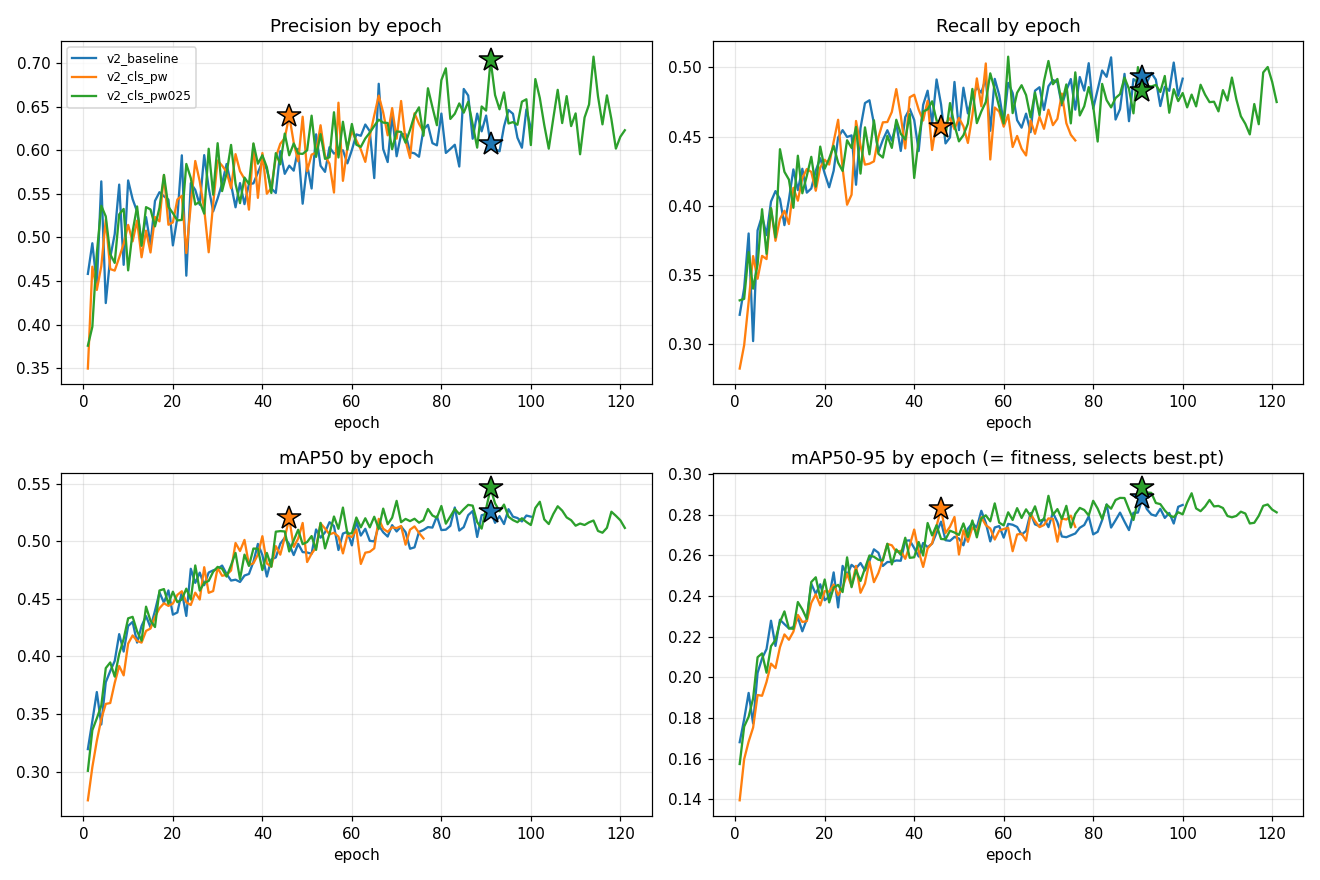

In [31]:
fig2, axes2 = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title) in zip(axes2.flat, [
        ("metrics/precision(B)", "Precision by epoch"),
        ("metrics/recall(B)", "Recall by epoch"),
        ("metrics/mAP50(B)", "mAP50 by epoch"),
        ("metrics/mAP50-95(B)", "mAP50-95 by epoch (= fitness, selects best.pt)")]):
    for name in RUNS:
        df = dfs[name]
        ax.plot(df["epoch"], df[col], color=COLORS[name], label=name)
        bi = bests[name]
        ax.plot(df.loc[bi, "epoch"], df.loc[bi, col], marker="*", markersize=16,
                color=COLORS[name], markeredgecolor="black", zorder=5)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes2.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("_tmp_master_nb_metric_curves.png", dpi=110)
plt.show()
print("saved _tmp_master_nb_metric_curves.png")


**Convergence and stability**: all three runs show the classic, healthy
pattern of a transfer-learned model — losses drop sharply in the first ~10
epochs, then flatten. **A mild, honest overfitting signature is visible, not
hidden**: training losses continue to inch down past each run's own best
epoch, while validation losses stay essentially flat or tick up very
slightly over the same stretch — the model keeps fitting the training data
marginally better without any further generalization gain, exactly the
pattern `patience=30` early stopping (Section 6.6) is designed to catch.

**Differences between the experiments**: `v2_cls_pw` stops earliest (76
epochs, best at 46) and its classification loss collapses far faster and
lower than the other two — not directly comparable in absolute value, since
`cls_pw` rescales that loss itself (Section 7.2), which is why Sections 7.3–
7.4 compare *validation metrics*, not raw loss values. `v2_baseline` and
`v2_cls_pw025` both train for over 90 effective epochs with closely-tracking
box/DFL loss curves — consistent with `cls_pw` affecting only the
classification loss, not box regression.

## 8. Experiment Comparison

A single consolidated view of every checkpoint evaluated in this project, all
at imgsz=1152 (where applicable), same val split, same matching criteria —
built directly from the already-saved summary CSVs of Sections 6–7.

                 precision    recall     map50  map50_95
model                                                   
v1_baseline       0.561368  0.435989  0.456186  0.244223
v1_oversampling   0.580208  0.434501  0.470594  0.250090
v2_baseline       0.605156  0.493264  0.526376  0.289086
v2_cls_pw         0.638821  0.457617  0.518578  0.283598
v2_cls_pw025      0.705429  0.483890  0.547408  0.294297
chart saved

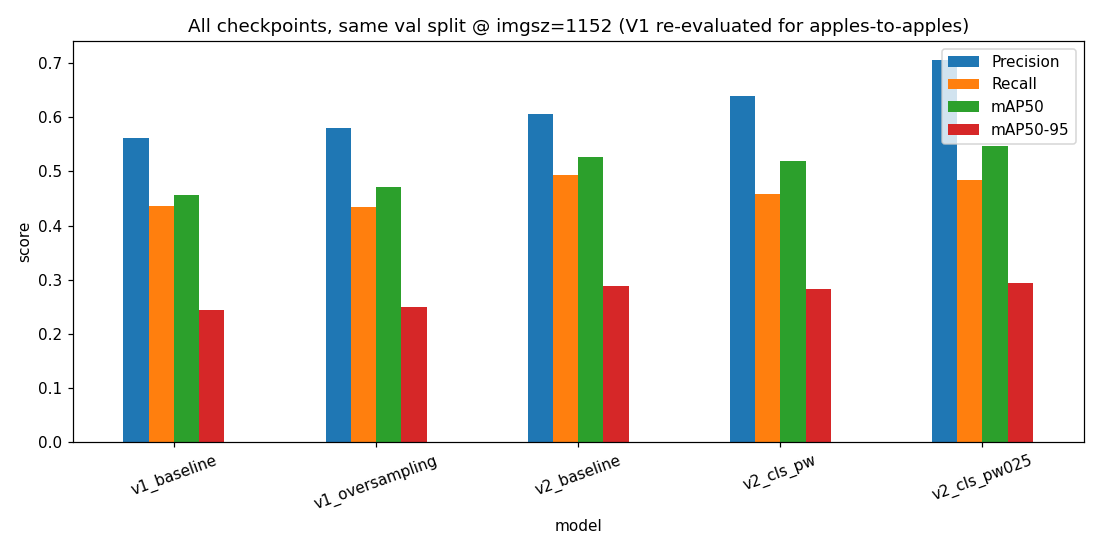

In [32]:
import pandas as pd
import matplotlib.pyplot as plt

v1v2 = pd.read_csv(PROJECT_ROOT / "reports/drivesight_v2/evaluation/validation/summary_global_metrics.csv")
pw = pd.read_csv(PROJECT_ROOT / "reports/drivesight_v2/evaluation/cls_pw025_vs_others/summary_global_metrics.csv")
combined = pd.concat([v1v2, pw[pw["model"] != "v2_baseline"]], ignore_index=True)
combined = combined.set_index("model").loc[
    ["v1_baseline", "v1_oversampling", "v2_baseline", "v2_cls_pw", "v2_cls_pw025"]]
print(combined[["precision", "recall", "map50", "map50_95"]].to_string())

fig, ax = plt.subplots(figsize=(10, 5))
combined[["precision", "recall", "map50", "map50_95"]].plot(kind="bar", ax=ax)
ax.set_ylabel("score"); ax.set_title("All checkpoints, same val split @ imgsz=1152 (V1 re-evaluated for apples-to-apples)")
ax.legend(["Precision", "Recall", "mAP50", "mAP50-95"])
plt.xticks(rotation=20); plt.tight_layout()
plt.savefig("_tmp_master_nb_comparison_chart.png", dpi=110)
plt.show()
print("chart saved")


### 8.1 Per-class AP50 across the three V2 checkpoints — all 9 classes

| class | v2_baseline | v2_cls_pw (0.5) | **v2_cls_pw025** |
|---|---:|---:|---:|
| pedestrian | 61.2% | 60.6% | **63.0%** |
| **rider** | 41.0% | 40.4% | **44.9%** |
| car | 78.6% | 77.2% | 78.4% |
| truck | 48.5% | 49.3% | **49.6%** |
| bus | 56.5% | 52.6% | **59.6%** |
| **motorcycle** | 29.7% | **39.9%** | 37.7% |
| **bicycle** | 37.7% | 33.4% | **38.9%** |
| traffic light | 60.7% | 57.0% | **61.4%** |
| traffic sign | 59.8% | 56.4% | 59.1% |

*(source: `reports/drivesight_v2/evaluation/cls_pw025_vs_others/summary_ap50_by_class_pivot.csv`)*

**`v2_cls_pw025` beats `v2_baseline` on 7 of 9 classes outright**, with the
other two (car, traffic sign) essentially flat — the clearest single table
demonstrating why it is the project's current best model (Section 16.6).

## 9. Recall and Error Analysis

Full detail: `reports/drivesight_v2/evaluation/CLS_PW025_RECALL_ERROR_ANALYSIS.md`.
All analysis below is for **`v2_cls_pw025`**, the current best model, on the
**validation** split.

### 9.1 The real matching algorithm behind every FP/FN/confusion count in this project

Every error audit in this project (V1's P0 round, V2's baseline/cls_pw
comparisons) uses the same custom matcher: same-class IoU matches first,
then cross-class confusions among what's left, then whatever remains is a
miss or an unmatched prediction. This is the real algorithm (transferred
from `archive/scripts/audit_validation_errors.py`, kept identical):

In [33]:
def box_iou(box_a, box_b):
    """IoU between two xyxy boxes."""
    x1, y1 = max(box_a[0], box_b[0]), max(box_a[1], box_b[1])
    x2, y2 = min(box_a[2], box_b[2]), min(box_a[3], box_b[3])
    intersection = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area_a = max(0.0, box_a[2] - box_a[0]) * max(0.0, box_a[3] - box_a[1])
    area_b = max(0.0, box_b[2] - box_b[0]) * max(0.0, box_b[3] - box_b[1])
    union = area_a + area_b - intersection
    return intersection / union if union > 0 else 0.0

def match_detections(ground_truth, predictions, match_iou):
    """Same-class IoU matches first, then cross-class confusions among the
    rest, then whatever's left is a miss / unmatched prediction."""
    used_gt, used_pred = set(), set()
    correct, confused, confusion_pairs = 0, 0, {}

    same_class = [(box_iou(gt["box"], pr["box"]), gi, pi)
                  for gi, gt in enumerate(ground_truth) for pi, pr in enumerate(predictions)
                  if gt["class_id"] == pr["class_id"] and box_iou(gt["box"], pr["box"]) >= match_iou]
    for overlap, gi, pi in sorted(same_class, reverse=True):
        if gi in used_gt or pi in used_pred:
            continue
        used_gt.add(gi); used_pred.add(pi); correct += 1

    cross_class = [(box_iou(gt["box"], pr["box"]), gi, pi)
                    for gi, gt in enumerate(ground_truth) if gi not in used_gt
                    for pi, pr in enumerate(predictions) if pi not in used_pred
                    and gt["class_id"] != pr["class_id"] and box_iou(gt["box"], pr["box"]) >= match_iou]
    for overlap, gi, pi in sorted(cross_class, reverse=True):
        if gi in used_gt or pi in used_pred:
            continue
        used_gt.add(gi); used_pred.add(pi); confused += 1
        pair = (ground_truth[gi]["class_id"], predictions[pi]["class_id"])
        confusion_pairs[pair] = confusion_pairs.get(pair, 0) + 1

    missed = [g for i, g in enumerate(ground_truth) if i not in used_gt]
    unmatched = [p for i, p in enumerate(predictions) if i not in used_pred]
    return {"correct": correct, "confused": confused, "missed_gt": missed,
            "unmatched_predictions": unmatched, "confusion_pairs": confusion_pairs}

# --- ILLUSTRATIVE TOY EXAMPLE (synthetic boxes, NOT real project data) ---
# Purely to show the algorithm\'s mechanics: one correct car match, one rider
# ground-truth box confidently (and wrongly) matched to a pedestrian prediction
# -- the exact rider->pedestrian pattern documented throughout this project
# (Sections 5.2, 6.9, 9) -- and one plain miss.
toy_gt = [
    {"class_id": 2, "box": [0.10, 0.10, 0.30, 0.40]},   # car
    {"class_id": 1, "box": [0.50, 0.20, 0.55, 0.45]},   # rider
    {"class_id": 6, "box": [0.70, 0.70, 0.75, 0.90]},   # bicycle -- will be missed
]
toy_preds = [
    {"class_id": 2, "box": [0.11, 0.09, 0.29, 0.41]},   # car, correct match
    {"class_id": 0, "box": [0.50, 0.20, 0.55, 0.45]},   # pedestrian, same box as the rider GT
]
result = match_detections(toy_gt, toy_preds, match_iou=0.50)
print("Toy example result:", {k: v for k, v in result.items() if k != "confusion_pairs"})
print("Confusion pairs (true_id -> pred_id : count):", result["confusion_pairs"])


Toy example result: {'correct': 1, 'confused': 1, 'missed_gt': [{'class_id': 6, 'box': [0.7, 0.7, 0.75, 0.9]}], 'unmatched_predictions': []}
Confusion pairs (true_id -> pred_id : count): {(1, 0): 1}

The toy example above is purely illustrative — it shows *how* the algorithm
decides correct/confused/missed, not a real result. **Every real FP/FN/
confusion number quoted anywhere in this notebook comes from already-saved
CSVs produced by actually running this exact algorithm against real model
predictions** (e.g. `reports/drivesight_v2/evaluation/cls_pw025_recall_diagnosis/`)
— re-running full inference over the validation set is not repeated here.

### 9.2 Cause-of-miss categorization

Every missed ground-truth instance (at the standard conf=0.25 reference
threshold) is categorized into exactly one cause:
- **low_confidence** — right class detected, IoU≥0.5, just below threshold
- **poor_localization** — right class nearby, IoU too low to count as a match
- **true_miss** — no right-class signal at any confidence down to 0.05
- **incorrect_classification** — matched to the *wrong* class at IoU≥0.5

In [34]:
import pandas as pd
causes = pd.read_csv(PROJECT_ROOT / "reports/drivesight_v2/evaluation/cls_pw025_recall_diagnosis/missed_object_causes.csv")
print(causes.to_string(index=False))


            image         class                    cause  predicted_as  best_right_class_iou  best_right_class_conf size_bucket  area_px occluded truncated  raw_attrs_found
00d79c0a-23bea078  traffic sign           low_confidence           NaN                 0.696                  0.105      medium   1509.2     True     False             True
00d79c0a-23bea078           car                true_miss           NaN                 0.000                    NaN       small    478.4     True     False             True
00d79c0a-23bea078           car        poor_localization           NaN                 0.434                  0.057       small    318.9     True     False             True
00d8944b-e157478b  traffic sign        poor_localization           NaN                 0.446                  0.076       small    153.8    False     False             True
00d8944b-e157478b  traffic sign                true_miss           NaN                 0.000                    NaN      medium   2371.

**Two distinct failure regimes**:
- **car / traffic-sign / traffic-light / pedestrian**: overwhelmingly
  `low_confidence` + `poor_localization` — detected, just under-confident or
  imprecisely boxed. A calibration/localization problem, not a capacity
  problem.
- **rider / motorcycle / bicycle**: dominated by `true_miss` — genuine non-
  detection, no right-class signal at *any* confidence. A representation/
  capacity problem that no amount of threshold-tuning can fix (Sections 10,
  14).

**New finding**: bus and truck have the *highest* `incorrect_classification`
rates of any class, almost entirely within the car/truck/bus visual-
similarity cluster — a separate, previously under-weighted problem (Section
18.3). **Rider's specific finding**: 9 of rider's 12 misclassifications
(75%) are specifically rider→pedestrian.

### 9.3 Visual evidence — three representative false negatives

<IPython.core.display.Image object>

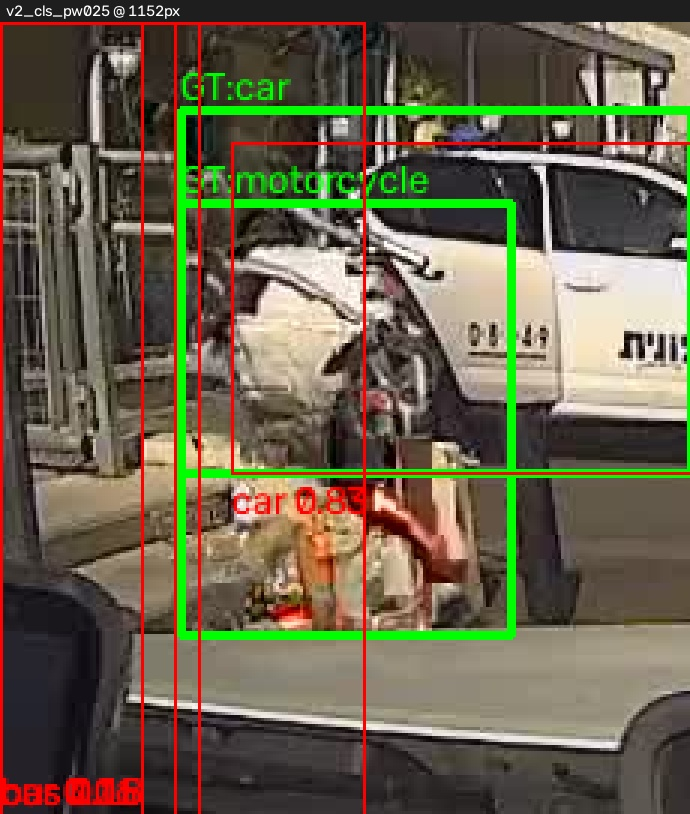

In [35]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "reports/drivesight_v2/evaluation/cls_pw025_recall_diagnosis/visual_evidence/2c9d86cc-0910b237/zoom_grid.jpg")))


**Motorcycle, large, not occluded, `true_miss`.** A parked/crashed
motorcycle wedged against a car, visually merged with the vehicle's wheel
well. The model predicts `car 0.83` and nothing else. **This rules out
occlusion and size as the excuse** — an atypical pose/state the model has
never learned, pointing at training-data *diversity*, not resolution.

<IPython.core.display.Image object>

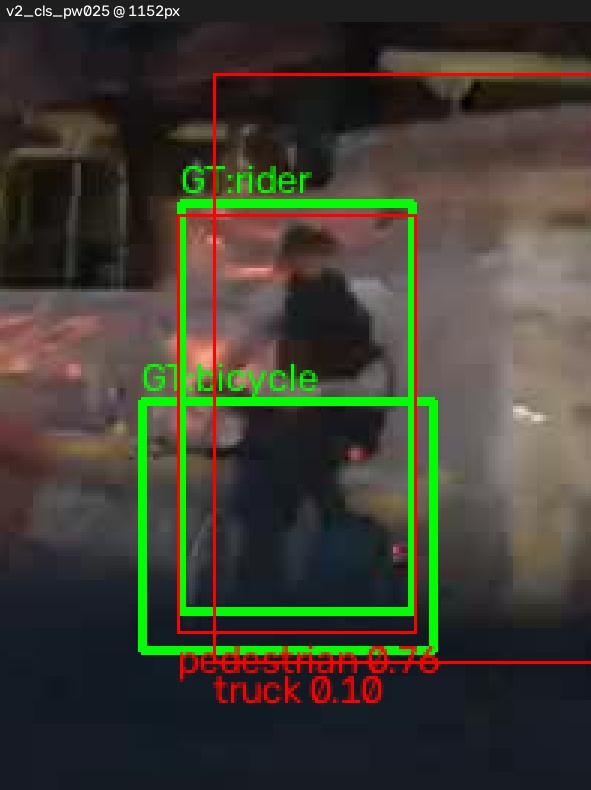

In [36]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "reports/drivesight_v2/evaluation/cls_pw025_recall_diagnosis/visual_evidence/4e721b4b-7d171227/zoom_grid.jpg")))


**Rider, large, `incorrect_classification` → pedestrian.** A person with a
bicycle at dusk. The model confidently predicts `pedestrian 0.76` with no
rider hypothesis at all. **Low-light conditions are a recurring, specific
contributor to this exact confusion.**

<IPython.core.display.Image object>

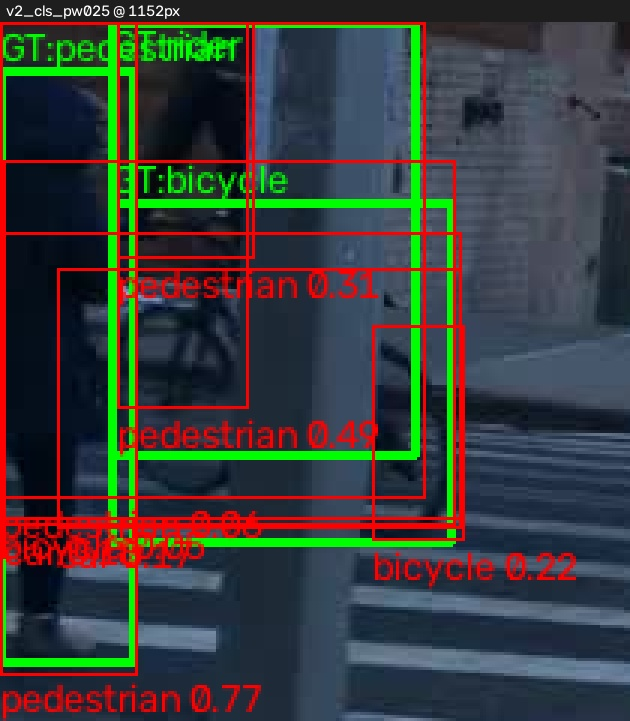

In [37]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "reports/drivesight_v2/evaluation/cls_pw025_recall_diagnosis/visual_evidence/1d981a62-27584b3b/zoom_grid.jpg")))


**Bicycle, large, `low_confidence`.** A person next to a bicycle, partly
behind a street pole, dusk lighting — fragmented, overlapping `pedestrian`
predictions and one weak `bicycle 0.22`. **This exact scene has now defeated
every model variant tried in this project.**

## 10. Confidence Threshold Optimization

Full detail: `CLASS_SPECIFIC_THRESHOLD_EVAL_REPORT.md`,
`CLS_PW025_THRESHOLD_STRATEGY_REPORT.md`, `CLS_PW025_HYBRID_POLICY_REPORT.md`,
`CLS_PW025_BICYCLE_CANDIDATE_REPORT.md`. **All threshold work in this section
is validation-split only — the test split is never referenced until Section
11.** This is a *deployment-policy* question (Section 1.1), layered on top of
an already-fixed model — it never changes the model's own mAP50/mAP50-95.

### 10.1 The real evaluation algorithm behind every threshold comparison

Threshold policies in this project are all evaluated from **one single
low-confidence (conf=0.05) inference pass**, then filtered per-class in
Python — exact for standard per-class greedy NMS, not an approximation, so
every policy is compared against literally identical underlying detections.
This is the real scoring algorithm (transferred from
`archive/scripts/drivesight_v2/final_test_policy_eval.py`, kept identical):

In [38]:
def greedy_match(ground_truth, predictions, match_iou):
    """Same algorithm family as Section 9.1's match_detections, used for every
    threshold-policy evaluation in this project. Returns which GT/predictions
    matched (same class), which were cross-class confused, and which were left
    over (missed / unmatched)."""
    used_gt, used_pred = set(), set()
    same_class = [(box_iou(gt["box"], pr["box"]), gi, pi)
                  for gi, gt in enumerate(ground_truth) for pi, pr in enumerate(predictions)
                  if gt["class_id"] == pr["class_id"] and box_iou(gt["box"], pr["box"]) >= match_iou]
    for ov, gi, pi in sorted(same_class, reverse=True):
        if gi in used_gt or pi in used_pred:
            continue
        used_gt.add(gi); used_pred.add(pi)

    cross_class = [(box_iou(gt["box"], pr["box"]), gi, pi)
                    for gi, gt in enumerate(ground_truth) if gi not in used_gt
                    for pi, pr in enumerate(predictions) if pi not in used_pred
                    and gt["class_id"] != pr["class_id"] and box_iou(gt["box"], pr["box"]) >= match_iou]
    confused = []
    for ov, gi, pi in sorted(cross_class, reverse=True):
        if gi in used_gt or pi in used_pred:
            continue
        used_gt.add(gi); used_pred.add(pi)
        confused.append((gi, pi))
    return used_gt, used_pred, confused

def evaluate_policy(all_preds_by_image, gt_by_image, class_thresholds, match_iou):
    """Filters the SAME single low-conf detections per-image by each
    prediction's own class threshold, then scores with greedy_match -- this is
    what makes every policy comparison in Section 10/11 exact, not approximate."""
    from collections import Counter
    correct, fp, fn_missed = Counter(), Counter(), Counter()
    for stem, all_preds in all_preds_by_image.items():
        ground_truth = gt_by_image[stem]
        preds = [p for p in all_preds if p["confidence"] >= class_thresholds[CLASS_NAMES[p["class_id"]]]]
        used_gt, used_pred, confused = greedy_match(ground_truth, preds, match_iou)
        confused_gi = {gi for gi, _ in confused}
        for gi in used_gt - confused_gi:
            correct[CLASS_NAMES[ground_truth[gi]["class_id"]]] += 1
        for gi, gt in enumerate(ground_truth):
            if gi not in used_gt:
                fn_missed[CLASS_NAMES[gt["class_id"]]] += 1
        for pi, pred in enumerate(preds):
            if pi not in used_pred:
                fp[CLASS_NAMES[pred["class_id"]]] += 1
    return correct, fp, fn_missed

# --- ILLUSTRATIVE TOY EXAMPLE (synthetic, single image, NOT real project data) ---
toy_detections = {
    "toy_img_1": [
        {"class_id": 6, "box": [0.1, 0.1, 0.2, 0.3], "confidence": 0.70},  # bicycle, confident
        {"class_id": 6, "box": [0.5, 0.5, 0.6, 0.7], "confidence": 0.18},  # bicycle, low-confidence
    ]
}
toy_gt_by_image = {"toy_img_1": [
    {"class_id": 6, "box": [0.11, 0.09, 0.19, 0.31]},
    {"class_id": 6, "box": [0.50, 0.50, 0.60, 0.70]},
]}
for name, thresholds in [("global_025", {"bicycle": 0.25}), ("vru_recall_bicycle", {"bicycle": 0.15})]:
    correct, fp, fn_missed = evaluate_policy(toy_detections, toy_gt_by_image, thresholds, match_iou=0.50)
    print(f"{name}: bicycle TP={correct['bicycle']} FP={fp['bicycle']} FN={fn_missed['bicycle']}")


global_025: bicycle TP=1 FP=0 FN=1
vru_recall_bicycle: bicycle TP=2 FP=0 FN=0

The toy example mirrors exactly the real `vru_recall_bicycle` mechanism
(Section 10.4, Section 11): lowering bicycle's threshold from 0.25 to 0.15
recovers the previously-too-low-confidence detection at the cost of nothing
else in this isolated illustration — the same direction of effect
documented with real numbers below.

### 10.2 Why thresholds matter, and why they must be re-derived per checkpoint

A single global confidence threshold (0.25) is mismatched to a class mix
this imbalanced: pedestrian keeps improving in F1 up to 0.25, but
rider/motorcycle/bicycle all peak at a *lower* threshold — **and this peak
shifts between checkpoints**. The `v2_baseline`-era policy assumed
rider/motorcycle/bicycle peaked at 0.15; once `cls_pw025` was trained, its
own best-F1 point for rider moved to **0.20**. **Any class-specific
threshold policy must be re-derived per checkpoint.**

### 10.3 Global vs per-class: two strategies compared on `v2_cls_pw025`

| | global_025 | max_f1_per_class | recall_priority |
|---|---:|---:|---:|
| macro Precision | 67.9% | **72.0%** | 64.6% |
| macro Recall | 51.0% | 49.5% | **52.0%** |
| macro F1 | 0.583 | **0.587** | 0.576 |
| Total FP | 3,666 | **2,225** | 2,795 |

The trade-off ratio directly reflects each class's cause-of-miss mix
(Section 9.2): pedestrian/bicycle (`low_confidence`-dominated) convert
threshold-lowering into real recall efficiently; rider/motorcycle
(`true_miss`-dominated) do not.

### 10.4 The rejected hybrid policy — why cross-class interactions matter

| policy | rider → pedestrian confusion |
|---|---:|
| global_025 | 9 |
| max_f1_per_class | **8 (best)** |
| recall_priority | 13 |
| **hybrid** | **14 (worst)** |

**The mechanism, isolated directly**: rider's own TP/FN is *identical*
between `max_f1_per_class` and the hybrid — the only difference is
pedestrian's threshold, and *that alone* moves the confusion count from 8 to
14. Lowering pedestrian's threshold puts far more candidate pedestrian boxes
into play, increasing the chance of a stray rider ground-truth box being
cross-matched to one of them — **exactly the mechanism `evaluate_policy`
above scores**, and exactly why this project evaluates threshold policies
jointly, not by composing single-class results.

### 10.5 Final bicycle candidate — the adopted refinement

| | max_f1_per_class | **candidate** | Δ |
|---|---:|---:|---:|
| bicycle Recall | 36.5% | **44.6%** | **+8.1pt** |
| bicycle Precision | 56.2% | 40.7% | -15.5pt |
| rider → pedestrian | **8** | **8** | unchanged |
| *(all other 8 classes)* | — | — | **byte-for-byte identical** |

Confirmed perfectly isolated. **Adopted** as the `vru_recall_bicycle` profile
(Section 11).

## 11. Final Inference Profiles

Both calibrated exclusively on **validation** data against `v2_cls_pw025`
(epoch 91); both require imgsz=1152, NMS iou=0.70, match-iou=0.50. This is
the real, frozen profile data (transferred from
`archive/scripts/drivesight_v2/inference_profiles.py`, kept identical as plain
data — not imported from that module):

In [39]:
# Transferred verbatim from archive/scripts/drivesight_v2/inference_profiles.py.
CHECKPOINT = "runs/drivesight_v2/v2_cls_pw025/weights/best.pt"
EVAL_SETTINGS = {"imgsz": 1152, "iou": 0.70, "match_iou": 0.50}

PROFILES = {
    "global_025": {
        "description": "Reference baseline: a single global confidence threshold for "
                        "every class. Not recommended -- kept only as the comparison point.",
        "thresholds": {c: 0.25 for c in CLASS_NAMES},
    },
    "balanced_max_f1": {
        "description": "Each class's own empirically-best-F1 threshold. Best overall "
                        "precision of any profile tested; best rider->pedestrian "
                        "confusion count (8, vs 9 at global_025). Recommended default.",
        "thresholds": {
            "pedestrian": 0.30, "rider": 0.20, "bicycle": 0.25, "motorcycle": 0.25,
            "car": 0.35, "bus": 0.35, "truck": 0.25, "traffic light": 0.30, "traffic sign": 0.30,
        },
    },
    "vru_recall_bicycle": {
        "description": "balanced_max_f1 with exactly one change: bicycle 0.25->0.15. "
                        "+6 bicycle TP (+8.1pt recall) for +27 bicycle FP, proven isolated "
                        "from every other class. Use when bicycle recall is prioritized "
                        "over bicycle precision.",
        "thresholds": {
            "pedestrian": 0.30, "rider": 0.20, "bicycle": 0.15, "motorcycle": 0.25,
            "car": 0.35, "bus": 0.35, "truck": 0.25, "traffic light": 0.30, "traffic sign": 0.30,
        },
    },
}

def get_profile(name):
    return dict(PROFILES[name]["thresholds"])

for name in PROFILES:
    print(name, "->", get_profile(name))


global_025 -> {'pedestrian': 0.25, 'rider': 0.25, 'car': 0.25, 'truck': 0.25, 'bus': 0.25, 'motorcycle': 0.25, 'bicycle': 0.25, 'traffic light': 0.25, 'traffic sign': 0.25}
balanced_max_f1 -> {'pedestrian': 0.3, 'rider': 0.2, 'bicycle': 0.25, 'motorcycle': 0.25, 'car': 0.35, 'bus': 0.35, 'truck': 0.25, 'traffic light': 0.3, 'traffic sign': 0.3}
vru_recall_bicycle -> {'pedestrian': 0.3, 'rider': 0.2, 'bicycle': 0.15, 'motorcycle': 0.25, 'car': 0.35, 'bus': 0.35, 'truck': 0.25, 'traffic light': 0.3, 'traffic sign': 0.3}

### 11.1 `balanced_max_f1` — recommended default

Each class's own empirically-best-F1 threshold. Best overall precision of any
profile evaluated; best rider→pedestrian confusion count (8, vs 9 at a flat
0.25). **Use when** overall precision/balance matters more than squeezing
extra recall from one class.

### 11.2 `vru_recall_bicycle` — the bicycle-recall-priority variant

Identical to `balanced_max_f1` except bicycle (0.25→0.15). +6 bicycle TP
(+8.1pt recall) for +27 bicycle FP (4.5 FP per recovered bicycle), proven
isolated from every other class (Section 10.5). **Use when** bicycle recall
is prioritized over bicycle precision — e.g. the risk-estimation objective
this project targets.

### 11.3 Deployment usage (uses the real functions defined above)

In [40]:
# Example deployment usage -- demonstrates the real functions above together.
# Not executed against a live model/image here (no inference is run by this
# notebook); shown as the real, callable pattern.
def apply_profile(all_predictions, profile_name):
    """all_predictions: list of {"class_id": int, "box": [...], "confidence": float}
    from a conf=0.05 model.predict(...) pass. Keeps only predictions whose
    confidence exceeds THAT prediction's own class threshold."""
    thresholds = get_profile(profile_name)
    return [p for p in all_predictions
            if p["confidence"] >= thresholds[CLASS_NAMES[p["class_id"]]]]

print("Example: thresholds for \'vru_recall_bicycle\':", get_profile("vru_recall_bicycle"))


Example: thresholds for 'vru_recall_bicycle': {'pedestrian': 0.3, 'rider': 0.2, 'bicycle': 0.15, 'motorcycle': 0.25, 'car': 0.35, 'bus': 0.35, 'truck': 0.25, 'traffic light': 0.3, 'traffic sign': 0.3}

### 11.4 Known limitations of both profiles (stated plainly)

- Calibrated for `v2_cls_pw025` only — must be re-derived if the reference
  checkpoint changes (Section 10.2 showed this shift is real, not
  theoretical).
- Neither profile fixes the rider→pedestrian confusion — thresholding can
  only filter predictions, not correct a classification error (Section 18).
- Small validation/test sample sizes for rider/motorcycle/bicycle mean
  single-digit TP/FP swings move percentages by several points.
- Neither profile was re-optimized *jointly* across all 9 classes
  simultaneously.

## 12. Final Test-Set Evaluation

> **This section presents results from existing, already-computed reports.**
> **No inference is re-run here, and the test split is not touched by this
> notebook.** Source reports: `TEST_SET_AUDIT.md`, `FINAL_TEST_SET_REPORT.md`,
> `FINAL_POLICY_TEST_SET_REPORT.md`. The procedure that produced them used
> exactly the matching algorithm defined in Section 10.1, run once per
> checkpoint/policy against the test split — documented here, not repeated.

### 12.1 Why the test split can be trusted for this one evaluation

Before any test-split evaluation, every saved `run_config.json`/`args.yaml`
in the entire repository was grepped for which split it actually used.
**Result: every training run and every evaluation this project has ever run
used `split: val`, with zero exceptions.** The only two touches of `test`
found were (a) the original dataset-construction scripts *defining* the
split, and (b) purely descriptive statistics (Section 2's test-label-
provenance check; Section 3's per-split instance counts) — dataset
description, not model evaluation. **Every model-selection and threshold
decision in Sections 6–10 was made on validation data only.**

### 12.2 Do the checkpoint-level findings generalize? (n=830 test images)

| | v2_baseline | v2_cls_pw (0.5) | v2_cls_pw025 (0.25) |
|---|---:|---:|---:|
| Recall | 48.1% | 44.6% | **50.7%** |
| mAP50 | 51.9% | 51.6% | **53.7%** |
| mAP50-95 | 27.6% | 27.4% | **28.4%** |
| rider AP50 | 34.5% | 35.5% | **39.6%** |
| motorcycle AP50 | 38.3% | **44.9%** | 42.7% |
| bicycle AP50 | 42.9% | 36.9% | **46.8%** |

**Every directional finding from validation replicates on test** — in some
cases (bicycle) with an *even larger* margin. **One honest reversal, reported
plainly**: on validation, `cls_pw025` had the highest precision (70.5%); on
test it has the *lowest* (61.4% vs baseline's 63.2%) — the recall/mAP
advantage is real and generalizes, the validation-time precision advantage
does not.

### 12.3 Do the two frozen inference profiles (Section 11) generalize?

| | global_025 | balanced_max_f1 | vru_recall_bicycle |
|---|---:|---:|---:|
| macro Recall | **51.4%** | 49.6% | 50.3% |
| micro Precision | 71.3% | **79.0%** | 78.8% |
| Total FP | 4,382 | **2,667** | 2,696 |
| bicycle Recall | 43.1% | 43.1% | **49.1%** (+7 TP / +28 FP) |

Both frozen profiles replicate the general validation pattern. **rider→
pedestrian confusion is identical (11) across all three policies on test** —
confirming, on genuinely unseen data, that thresholding cannot move this
classification error.

## 13. V2 Experiment 3 — MixUp on top of Class Weighting

**The three V2 experiments**, now complete:

| # | experiment | what changed | where documented |
|---|---|---|---|
| 1 | `v2_baseline` | the V2 recipe itself (imgsz 1152, batch 4, AdamW, `cls_pw=0`) | Section 6 |
| 2 | `v2_cls_pw025` | + class weighting `cls_pw=0.25` | Section 7 |
| 3 | `v2_cls_pw025_mixup` | + MixUp `mixup=0.15` (this section) | Sections 13–15 |

### 13.1 Motivation and objective

Section 9.2 showed that rider, motorcycle and bicycle misses are dominated by `true_miss` — no right-class
signal at *any* confidence — a representation problem that no confidence threshold can touch (Section 10).
Section 9.3 and 18.1 argued that what is missing is visual *diversity*, not simply volume. MixUp
(Zhang et al., 2018, arXiv:1710.09412) was the best-evidenced training-time lever in scope: it adds
compositional diversity — two scenes overlaid in one training sample — without the whole-image duplication
that made V1 oversampling the weakest rebalancing tried in this project (Section 5.1).

**Objective.** Test whether `mixup=0.15` improves VRU detection on top of the current best configuration
(`v2_cls_pw025`), with MixUp as the **single** new variable. **Pre-stated measurement** (from the
recommendation table in `CLS_PW025_RECALL_ERROR_ANALYSIS.md`, §6): compare the `true_miss` rate of the VRU
classes before and after — not only AP50.

**Design choices that isolate the variable.**
- Training starts from fresh COCO-pretrained `yolo11n.pt`, **not** from the trained `v2_cls_pw025` checkpoint:
  continuing a converged checkpoint would mix MixUp's effect with extra epochs, and V1's `finetune_960`
  (Section 5.1) already showed that continuing a converged checkpoint is hazardous.
- `cls_pw` stays 0.25 and every other hyperparameter is unchanged (verified in 13.4).
- Only `mixup=0.15` was run. No other MixUp strength was tested, so this experiment says nothing about
  stronger or weaker MixUp.

### 13.2 Dataset, architecture and environment

Identical to every other V2 run: the same `data/bdd100k/yolo_dataset/data.yaml` and split
(Sections 2–4), the same architecture and transfer-learning setup (YOLO11n from `yolo11n.pt`, 9-class head
via `cls_remap`, Sections 6.1–6.2), the same training function (`train_v2_experiment`, Section 6.4). The
split sizes and the VRU instance counts that matter for everything that follows — **note how few VRU
instances the validation and test splits contain** — are computed live from the label files:

In [41]:
from pathlib import Path
import csv, json, hashlib, platform
import numpy as np
import pandas as pd
import torch, ultralytics

EVALD = PROJECT_ROOT / "reports/drivesight_v2/evaluation"
RUNS = PROJECT_ROOT / "runs/drivesight_v2"
CLASS_NAMES = ["pedestrian", "rider", "car", "truck", "bus", "motorcycle", "bicycle",
               "traffic light", "traffic sign"]
VRU4 = ["pedestrian", "rider", "motorcycle", "bicycle"]
THREE = ["v2_baseline", "v2_cls_pw025", "v2_cls_pw025_mixup"]

print("python", platform.python_version(), "| ultralytics", ultralytics.__version__,
      "| torch", torch.__version__.split("+")[0], "| numpy", np.__version__, "| pandas", pd.__version__)

YOLO_DS = PROJECT_ROOT / "data/bdd100k/yolo_dataset"
rows = []
for split in ("train", "val", "test"):
    inst = {c: 0 for c in CLASS_NAMES}
    imgs_with = {c: 0 for c in VRU4}
    for f in (YOLO_DS / "labels" / split).glob("*.txt"):
        seen = set()
        for line in f.read_text(encoding="utf-8").splitlines():
            p = line.split()
            if len(p) == 5:
                inst[CLASS_NAMES[int(p[0])]] += 1
                seen.add(CLASS_NAMES[int(p[0])])
        for c in seen & set(VRU4):
            imgs_with[c] += 1
    rows.append({"split": split, "images": len(list((YOLO_DS / "images" / split).glob("*.jpg"))),
                 **{f"{c} (instances)": inst[c] for c in VRU4},
                 **{f"{c} (images)": imgs_with[c] for c in VRU4[1:]}})
print()
print(pd.DataFrame(rows).set_index("split").to_string())


python 3.10.0 | ultralytics 8.4.189 | torch 2.10.0 | numpy 2.2.6 | pandas 2.3.3

       images  pedestrian (instances)  rider (instances)  motorcycle (instances)  bicycle (instances)  rider (images)  motorcycle (images)  bicycle (images)
split                                                                                                                                                       
train    2744                    4678                245                     166                  399             194                  125               220
val       686                    1083                 59                      45                   74              44                   38                42
test      830                    1228                 72                      39                  116              56                   31                57

The test split holds only 72 riders, 39 motorcycles and 116 bicycles (validation: 59 / 45 / 74), spread over
a few dozen images each. **This is the reason almost every VRU comparison in Sections 14–15 comes with a wide
confidence interval** — and why single-digit swings in TP/FP counts must not be over-read.

**Environment used for every V2 run and every evaluation in this notebook**: Windows 11, Python 3.10,
`ultralytics==8.4.189` (the official PyPI release, which includes `cls_pw` / `cls_remap` as stock features — verified
byte-identical in Section 7.2), PyTorch 2.10 (CUDA 13), NumPy 2.2, a single **NVIDIA GeForce RTX 2050 with 4 GB of memory** and
15.3 GB of host RAM — a memory-constrained machine that shapes several decisions below (batch size 4,
`workers=0`, repeated memory-pressure interruptions).

### 13.3 What MixUp actually does — the real implementation

MixUp is not a project script: it ships inside the installed Ultralytics package. Verbatim from
`ultralytics/data/augment.py` (class `MixUp`, starting at line 784), the three methods that define the
behaviour:

```python
class MixUp(BaseMixTransform):
    def get_params(self, labels: dict[str, Any]) -> dict[str, Any]:
        params = super().get_params(labels)
        params["r"] = np.random.beta(32.0, 32.0)
        return params

    def apply_image(self, labels: dict[str, Any], params: dict[str, Any] | None = None) -> dict[str, Any]:
        r = params["r"]
        labels2 = labels["mix_labels"][0]
        labels["img"] = (labels["img"] * r + labels2["img"] * (1 - r)).astype(np.uint8)
        return labels

    def apply_instances(self, labels: dict[str, Any], params: dict[str, Any] | None = None) -> dict[str, Any]:
        labels2 = labels["mix_labels"][0]
        labels["instances"] = Instances.concatenate([labels["instances"], labels2["instances"]], axis=0)
        labels["cls"] = np.concatenate([labels["cls"], labels2["cls"]], 0)
        return labels
```

The gate (`BaseMixTransform.__call__`, same file) — MixUp fires for a sample with probability `p = mixup`:

```python
        if random.uniform(0, 1) > self.p:
            return labels

        params = self.get_params(labels)
        labels = self.apply_image(labels, params)
        labels = self.apply_instances(labels, params)
```

and where it sits in the training augmentation pipeline (`v8_transforms`, same file). `pre_transform` is the
`Compose([mosaic, (copy-paste), affine])` stage built just above it, so **MixUp blends two already
mosaic-augmented samples**:

```python
    return Compose(
        [
            pre_transform,
            MixUp(dataset, pre_transform=pre_transform, p=hyp.mixup),
            CutMix(dataset, pre_transform=pre_transform, p=hyp.cutmix),
            Albumentations(p=1.0, transforms=getattr(hyp, "augmentations", None), flip_idx=flip_idx),
            RandomHSV(hgain=hyp.hsv_h, sgain=hyp.hsv_s, vgain=hyp.hsv_v),
            RandomFlip(direction="vertical", p=hyp.flipud, flip_idx=flip_idx),
            RandomFlip(direction="horizontal", p=hyp.fliplr, flip_idx=flip_idx),
        ]
    )
```

**In plain terms**: with probability 0.15 a training sample is overlaid with a second, randomly chosen sample
using a blend weight `r ~ Beta(32, 32)` — tightly concentrated around 0.5 (mean 0.5, sd ≈ 0.06) — so the two
images are blended roughly half-and-half. **Both images' boxes are kept at full weight** (the labels are
concatenated, not interpolated): the model is trained to find every object of both scenes in one semi-transparent
composite. Two consequences matter for this project: composites contain *two* scenes' worth of objects, and
the blended pixels reduce contrast — the intended source of "compositional diversity".

Finally, `close_mosaic=10` (an Ultralytics default, unchanged here) switches off mosaic **and MixUp** for the
last 10 epochs of the 150-epoch schedule (`YOLODataset.close_mosaic` sets `hyp.mixup = 0.0`). Both
`v2_cls_pw025` and this run stopped early (epochs 121 and 116), so neither ever reached that final
augmentation-free phase.

The cell below runs the **real `MixUp` class** from the installed package on a toy two-sample dataset (not
project data) and verifies the blend formula and the label concatenation:

In [42]:
import copy, random
from ultralytics.data.augment import MixUp
from ultralytics.utils.instance import Instances

class ToyDataset:
    """Just enough of YOLODataset for MixUp: __len__ and get_image_and_label."""
    def __init__(self):
        self.items = []
        for value, (cls, xywh) in zip((40, 200), [(1, [0.3, 0.5, 0.1, 0.2]), (6, [0.7, 0.4, 0.2, 0.3])]):
            self.items.append({"img": np.full((64, 64, 3), value, dtype=np.uint8),
                               "cls": np.array([[cls]], dtype=np.float32),
                               "instances": Instances(bboxes=np.array([xywh], dtype=np.float32), segments=None,
                                                      keypoints=None, bbox_format="xywh", normalized=True)})
    def __len__(self):
        return len(self.items)
    def get_image_and_label(self, i):
        return copy.deepcopy(self.items[i])

ds = ToyDataset()
mix = MixUp(ds, pre_transform=None, p=1.0)       # p=1 so this demo always mixes
mix.get_indexes = lambda: 1                      # force the second sample as the mixing partner
np.random.seed(0); random.seed(0)
lab = ds.get_image_and_label(0)                  # a 'rider' image (every pixel = 40)
params = mix.get_params(lab)                     # draws r ~ Beta(32, 32) and fetches the partner: a 'bicycle' image (200)
r = params["r"]
out = mix.apply_instances(mix.apply_image(lab, params), params)
expected = int(40 * r + 200 * (1 - r))
print(f"r drawn from Beta(32,32) = {r:.4f}")
print(f"blended pixel = {out['img'][0, 0, 0]}   expected int(40*r + 200*(1-r)) = {expected}   match: {bool(out['img'][0, 0, 0] == expected)}")
print("instances after MixUp:", len(out["instances"]), "| classes:", out["cls"].ravel().astype(int).tolist(),
      "(rider=1, bicycle=6 -- both images' boxes kept at full weight)")
rs = np.random.beta(32.0, 32.0, 200_000)
print(f"Beta(32,32): mean {rs.mean():.3f}, sd {rs.std():.3f}, 5th-95th percentile {np.percentile(rs, 5):.3f}-{np.percentile(rs, 95):.3f}")


r drawn from Beta(32,32) = 0.5567
blended pixel = 110   expected int(40*r + 200*(1-r)) = 110   match: True
instances after MixUp: 2 | classes: [1, 6] (rider=1, bicycle=6 -- both images' boxes kept at full weight)
Beta(32,32): mean 0.500, sd 0.062, 5th-95th percentile 0.398-0.602

### 13.4 Exact configuration — the one-variable claim, verified

The resolved `args.yaml` of every V2 run (Ultralytics writes it automatically; for runs that were resumed, the
`model`/`resume` entries record that run's own `last.pt`). The last line lists every key that differs between
`v2_cls_pw025` and `v2_cls_pw025_mixup` after normalising each run's own name out of path-valued entries:

In [43]:
import yaml
KEYS = ["model", "imgsz", "batch", "epochs", "patience", "optimizer", "lr0", "freeze", "cls_pw", "mixup",
        "mosaic", "close_mosaic", "hsv_h", "hsv_s", "hsv_v", "scale", "fliplr", "seed", "deterministic",
        "workers", "device", "resume"]
cfg = {}
for name in ("v2_baseline", "v2_cls_pw", "v2_cls_pw025", "v2_cls_pw025_mixup"):
    a = yaml.safe_load((RUNS / name / "args.yaml").read_text())
    # show path-valued entries as file names only, for readability
    cfg[name] = {k: (Path(str(a.get(k))).name if k in ("model", "resume") and a.get(k) else a.get(k)) for k in KEYS}
cfg_df = pd.DataFrame(cfg)
print(cfg_df.to_string())

def norm(name):
    a = yaml.safe_load((RUNS / name / "args.yaml").read_text())
    return {k: str(v).replace(name, "<run>") for k, v in a.items()}
a, b = norm("v2_cls_pw025"), norm("v2_cls_pw025_mixup")
print("\nkeys that differ between v2_cls_pw025 and v2_cls_pw025_mixup:", sorted(k for k in a if a[k] != b.get(k)))


              v2_baseline   v2_cls_pw v2_cls_pw025 v2_cls_pw025_mixup
model             last.pt  yolo11n.pt      last.pt            last.pt
imgsz                1152        1152         1152               1152
batch                   4           4            4                  4
epochs                150         150          150                150
patience               30          30           30                 30
optimizer           AdamW       AdamW        AdamW              AdamW
lr0                 0.001       0.001        0.001              0.001
freeze               None        None         None               None
cls_pw                0.0         0.5         0.25               0.25
mixup                 0.0         0.0          0.0               0.15
mosaic                1.0         1.0          1.0                1.0
close_mosaic           10          10           10                 10
hsv_h               0.015       0.015        0.015              0.015
hsv_s               

**`mixup` is the only hyperparameter that differs** — `cls_pw=0.25`, `imgsz=1152`, `batch=4`,
`AdamW`/`lr0=0.001`, `freeze=null`, `patience=30`, `epochs=150`, `workers=0`, the seed (0, deterministic) and
every augmentation setting are identical to `v2_cls_pw025`. (`seed: 0` and `deterministic: true` are
Ultralytics' defaults; GPU kernels and the random augmentation stream still make runs non-bit-reproducible, and
**only one seed was run** — see the limitations in 13.9.)

How this experiment is launched with the Section 6.4 function. The exact command line used historically is
**not** stored in the project's artifacts (a resumed run has no `run_manifest.json`, Section 6.4); the call
below is reconstructed from the saved `args.yaml` above and `archive/docs/MIXUP_RECOVERY_NOTES.md` (local archive), and is gated by the same
hard guard as every other training call in this notebook:

In [44]:
# Reconstructed from args.yaml + archive/docs/MIXUP_RECOVERY_NOTES.md; NOT executed here (hard guard RUN_NEW_TRAINING = False,
# defined in Section 6.4 together with train_v2_experiment).
if RUN_NEW_TRAINING:
    train_v2_experiment("v2_cls_pw025_mixup", cls_pw=0.25, mixup=0.15, workers=0)   # weights default: yolo11n.pt
else:
    print("RUN_NEW_TRAINING is False -- no training is started by this notebook.")


RUN_NEW_TRAINING is False -- no training is started by this notebook.

A **2-epoch smoke test** (`--smoke-test`, separate directory `v2_cls_pw025_mixup_smoke/`) confirmed the MixUp
pipeline runs end to end before the full run was committed (it completed with exit code 0; peak GPU memory
1.89 GB, per `archive/docs/MIXUP_RECOVERY_NOTES.md` (local archive)). It is kept, untouched, and is not part of any result below.

### 13.5 Training procedure, interruptions, resume and early stopping

**Procedure.** Identical to Section 6.5: forward pass at `imgsz=1152`, `batch=4`, the three losses (`cls_loss`
scaled by the 0.25 class weights, Section 7.2), AdamW updates of the whole network, validation on the
**validation** split after every epoch; `best.pt` is the epoch with the highest *fitness*, which in this
Ultralytics build equals **mAP50-95 alone** (Section 6.6), and `patience=30` stops training after 30 epochs
without a new best.

**Interruptions and resume.** The run was interrupted **three times**, each time while the host was running out
of memory (an external kill, not a training error). For the first two, `archive/docs/MIXUP_RECOVERY_NOTES.md` (local archive) records that
the log showed no Python traceback, that GPU memory was fully released afterwards (so not a CUDA error) and the
free-RAM readings around them; the third interruption (after epoch 114) followed the same pattern, with the
host again low on memory. Each time the run was
resumed **from its own `last.pt` — never restarted** — with the Section 6.4 `resume_v2_experiment` logic
(`resume=<path to last.pt>`, `workers=0`). The proof that nothing was lost or changed is in the data itself:
Ultralytics restarts the cumulative `time` column of `results.csv` at every resume, so the resume boundaries
are directly visible, and the epochs stay contiguous across them:

In [45]:
df = pd.read_csv(RUNS / "v2_cls_pw025_mixup" / "results.csv")
df.columns = [c.strip() for c in df.columns]
assert df["epoch"].tolist() == list(range(1, len(df) + 1)), "epochs are not contiguous"
print(f"results.csv: {len(df)} rows, epochs {df.epoch.min()}..{df.epoch.max()}, contiguous, no duplicates\n")

resets = df.index[df["time"].diff() < 0].tolist()          # the 'time' column restarts at every resume
starts, ends = [0] + resets, resets + [len(df)]
for i, (a, b) in enumerate(zip(starts, ends)):
    seg = df.iloc[a:b]
    kind = "fresh start from yolo11n.pt" if i == 0 else f"resume #{i}  (resume=last.pt, workers=0)"
    print(f"segment {i}: epochs {int(seg.epoch.iloc[0]):3d}-{int(seg.epoch.iloc[-1]):3d}  "
          f"({len(seg):2d} epochs, {seg['time'].iloc[-1] / 3600:5.2f} h)   {kind}")
print(f"\nmedian time per epoch: {df['time'].diff().where(df['time'].diff() > 0).median():.0f} s")

best = df.loc[df["metrics/mAP50-95(B)"].idxmax()]
print(f"\nbest epoch (fitness = mAP50-95): {int(best.epoch)}   mAP50-95 = {best['metrics/mAP50-95(B)']:.5f}")
print(f"epochs since best at the final epoch: {int(df.epoch.iloc[-1] - best.epoch)}   (patience = 30 -> EarlyStopping)")


results.csv: 116 rows, epochs 1..116, contiguous, no duplicates

segment 0: epochs   1- 11  (11 epochs,  0.76 h)   fresh start from yolo11n.pt
segment 1: epochs  12- 70  (59 epochs,  4.16 h)   resume #1  (resume=last.pt, workers=0)
segment 2: epochs  71-114  (44 epochs,  2.93 h)   resume #2  (resume=last.pt, workers=0)
segment 3: epochs 115-116  ( 2 epochs,  0.14 h)   resume #3  (resume=last.pt, workers=0)

median time per epoch: 239 s

best epoch (fitness = mAP50-95): 86   mAP50-95 = 0.29897
epochs since best at the final epoch: 30   (patience = 30 -> EarlyStopping)

**Segments**: epochs 1–11 (fresh start), 12–70 (resume 1), 71–114 (resume 2), 115–116 (resume 3, ended by
early stopping). Each resume logged Ultralytics' own line *"Resuming training … from epoch N to 150 total
epochs"* with N = 12, 71 and 115, matching the boundaries above.

**Integrity of the final recovery.** Before the third resume, the full epoch-114 state was copied to
`runs/drivesight_v2/v2_cls_pw025_mixup_backup_ep114/` and verified by size and SHA-256. The cell below
re-verifies that backup and shows what a resumed run restores from the checkpoint — the best fitness **and the
early-stopping counter state** (`stopper`), so patience continues rather than restarts — plus the proof that the
two settings under test cannot drift on resume:

In [46]:
BK = RUNS / "v2_cls_pw025_mixup_backup_ep114"
bk = pd.read_csv(BK / "results_ep114.csv"); bk.columns = [c.strip() for c in bk.columns]
same = bk.reset_index(drop=True).equals(df.iloc[:len(bk)].reset_index(drop=True))
print(f"backup results_ep114.csv ({len(bk)} rows) identical to the first {len(bk)} rows of the final results.csv: {same}")

# SHA-256 values recorded when the backup was made (before the third resume)
RECORDED = {"last.pt": "88dcb28b11b559153280edf7d8da2433e2305863cf47704721f13589c6e1b9d0",
            "best.pt": "65bcfbba04f2a0fabe84d326fcc75acd8ae5c699270e5fda9981ef923386d151"}
for name, expected in RECORDED.items():
    h = hashlib.sha256((BK / name).read_bytes()).hexdigest()
    print(f"backup {name}: size {(BK / name).stat().st_size:,} bytes | sha256 matches the recorded value: {h == expected}")

ck = torch.load(BK / "last.pt", map_location="cpu", weights_only=False)
print("\nbackup last.pt (the checkpoint the third resume started from):")
print("  last completed epoch (0-indexed):", ck["epoch"], "-> resumes at epoch", ck["epoch"] + 2)
print("  best_fitness:", ck["best_fitness"], "| early-stopping state restored on resume:", ck.get("stopper"))
print("  train_args cls_pw / mixup:", ck["train_args"]["cls_pw"], "/", ck["train_args"]["mixup"],
      "| optimizer state present:", ck.get("optimizer") is not None)

# 'RESUME_ALLOWED_OVERRIDES' is the allow-list defined in Section 6.4
print("\nmixup on the resume allow-list:", "mixup" in RESUME_ALLOWED_OVERRIDES,
      "| cls_pw on the resume allow-list:", "cls_pw" in RESUME_ALLOWED_OVERRIDES,
      "-> neither could have changed across the three resumes")


backup results_ep114.csv (114 rows) identical to the first 114 rows of the final results.csv: True
backup last.pt: size 26,669,538 bytes | sha256 matches the recorded value: True
backup best.pt: size 26,665,954 bytes | sha256 matches the recorded value: True

backup last.pt (the checkpoint the third resume started from):
  last completed epoch (0-indexed): 113 -> resumes at epoch 115
  best_fitness: 0.29897 | early-stopping state restored on resume: {'best_fitness': 0.29897, 'best_epoch': 86}
  train_args cls_pw / mixup: 0.25 / 0.15 | optimizer state present: True

mixup on the resume allow-list: False | cls_pw on the resume allow-list: False -> neither could have changed across the three resumes

**Early stopping.** The best epoch is **86** (mAP50-95 = 0.29897). Training ran to epoch 116, exactly 30
epochs later, and Ultralytics stopped it ("no improvement observed in last 30 epochs. Best results observed
at epoch 86"). A note on a subtlety: the `EarlyStopping` counter is measured in epochs since the best
*mAP50-95*, so a run can keep improving other metrics (recall, precision) while the counter runs down — the
same fitness-is-not-recall point made in Section 6.6.

### 13.6 Training history and curves

Built directly from each run's own `results.csv` — nothing smoothed or selected. The stars mark each run's
`best.pt` epoch. (Note the visible plateau: from roughly epoch 60 on, mAP50-95 fluctuates by a few tenths of a
point from one epoch to the next in *every* run, which matters for how much a single best-epoch number can
be trusted — see the plateau statistics below the charts.)

run             v2_cls_pw025  v2_cls_pw025_mixup
epochs (>=60)        62.0000             57.0000
mAP50-95 mean         0.2825              0.2908
mAP50-95 sd           0.0042              0.0046
recall mean           0.4790              0.4884
recall sd             0.0127              0.0135
precision mean        0.6392              0.6407
precision sd          0.0252              0.0239

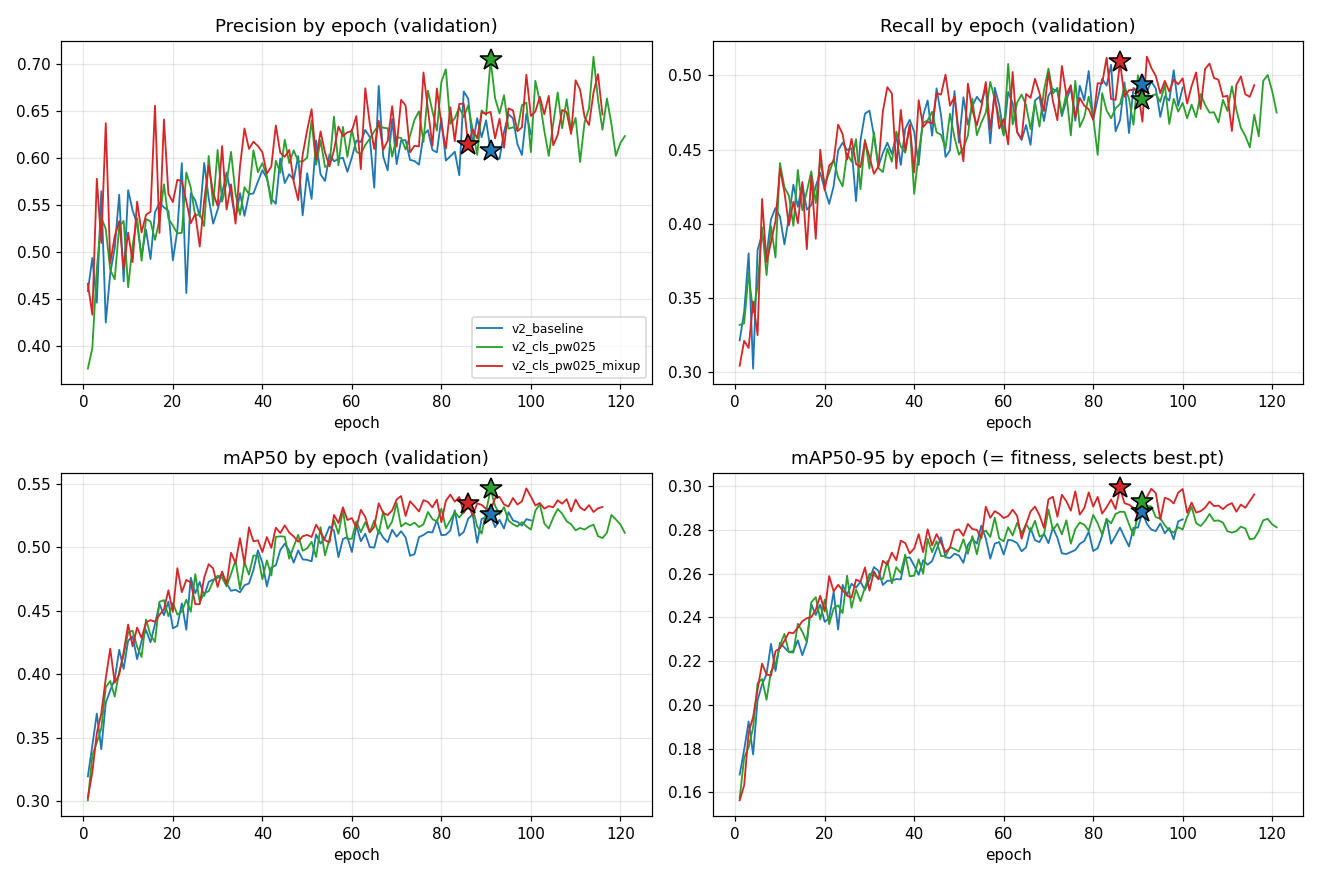

In [47]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

COL = {"v2_baseline": "tab:blue", "v2_cls_pw025": "tab:green", "v2_cls_pw025_mixup": "tab:red"}
dfs = {}
for n in THREE:
    d = pd.read_csv(RUNS / n / "results.csv"); d.columns = [c.strip() for c in d.columns]; dfs[n] = d

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
for ax, (col, title) in zip(axes.flat, [("metrics/precision(B)", "Precision by epoch (validation)"),
                                        ("metrics/recall(B)", "Recall by epoch (validation)"),
                                        ("metrics/mAP50(B)", "mAP50 by epoch (validation)"),
                                        ("metrics/mAP50-95(B)", "mAP50-95 by epoch (= fitness, selects best.pt)")]):
    for n in THREE:
        d = dfs[n]
        ax.plot(d["epoch"], d[col], color=COL[n], label=n, lw=1.2)
        bi = d["metrics/mAP50-95(B)"].idxmax()
        ax.plot(d.loc[bi, "epoch"], d.loc[bi, col], marker="*", markersize=15, color=COL[n], markeredgecolor="black", zorder=5)
    ax.set_title(title); ax.set_xlabel("epoch"); ax.grid(alpha=0.3)
axes.flat[0].legend(fontsize=8)
plt.tight_layout()
plt.savefig("_tmp_master_nb_mixup_metric_curves.png", dpi=110)
plt.show()

# Epoch-to-epoch noise on the plateau (epochs >= 60), the honest yardstick for best-epoch comparisons
rows = []
for n in ("v2_cls_pw025", "v2_cls_pw025_mixup"):
    p = dfs[n][dfs[n]["epoch"] >= 60]
    rows.append({"run": n, "epochs (>=60)": len(p),
                 "mAP50-95 mean": round(p["metrics/mAP50-95(B)"].mean(), 4), "mAP50-95 sd": round(p["metrics/mAP50-95(B)"].std(), 4),
                 "recall mean": round(p["metrics/recall(B)"].mean(), 4), "recall sd": round(p["metrics/recall(B)"].std(), 4),
                 "precision mean": round(p["metrics/precision(B)"].mean(), 4), "precision sd": round(p["metrics/precision(B)"].std(), 4)})
print(pd.DataFrame(rows).set_index("run").T.to_string())


loss curves: train (solid) and validation (dashed), v2_cls_pw025 vs v2_cls_pw025_mixup, 121 and 116 epochs

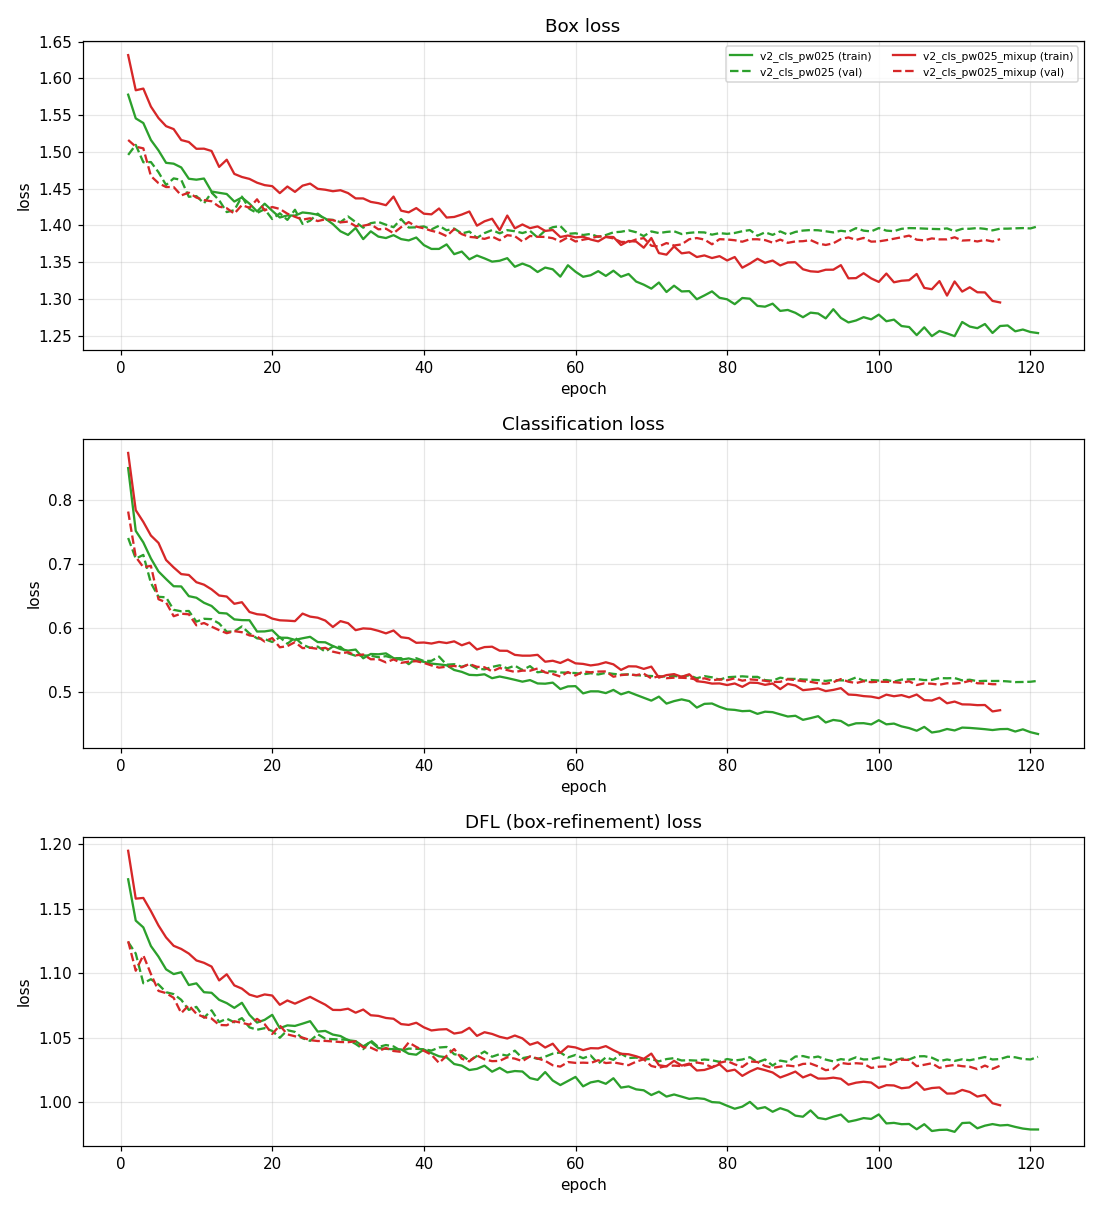

In [48]:
fig, axes = plt.subplots(3, 1, figsize=(10, 11))
for ax, (tc, vc, title) in zip(axes, [("train/box_loss", "val/box_loss", "Box loss"),
                                      ("train/cls_loss", "val/cls_loss", "Classification loss"),
                                      ("train/dfl_loss", "val/dfl_loss", "DFL (box-refinement) loss")]):
    for n in ("v2_cls_pw025", "v2_cls_pw025_mixup"):
        d = dfs[n]
        ax.plot(d["epoch"], d[tc], color=COL[n], linestyle="-", label=f"{n} (train)")
        ax.plot(d["epoch"], d[vc], color=COL[n], linestyle="--", label=f"{n} (val)")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.set_ylabel("loss"); ax.grid(alpha=0.3)
axes[0].legend(fontsize=7, ncol=2)
plt.tight_layout()
plt.savefig("_tmp_master_nb_mixup_loss_curves.png", dpi=110)
plt.show()
print("loss curves: train (solid) and validation (dashed), v2_cls_pw025 vs v2_cls_pw025_mixup,",
      f"{len(dfs['v2_cls_pw025'])} and {len(dfs['v2_cls_pw025_mixup'])} epochs")


**What the curves show.** All three runs follow the same transfer-learning shape as Section 7.5: sharp loss
drops in the first ~10 epochs, then a long plateau. MixUp's **training** losses sit visibly *higher* than
`v2_cls_pw025`'s on the plateau (mean box / cls / DFL loss over epochs ≥ 60: 1.345 / 0.509 / 1.022 against
1.287 / 0.464 / 0.994) — expected, since every MixUp composite contains two scenes' worth of objects at
half contrast, a harder target — while the **validation** losses (measured on clean, un-mixed images) end up
very close, MixUp's marginally lower (1.380 / 0.519 / 1.029 against 1.392 / 0.521 / 1.034). That is the
signature of a regulariser, not of a capacity change. On the validation metrics, MixUp's plateau sits
slightly above `v2_cls_pw025`'s for mAP50-95 and recall and level for precision (table above). **Plateau
statistics are the fair way to compare two runs**: a single best-epoch value is the maximum of ~60 noisy
epochs, and the epoch-to-epoch standard deviation (≈ 0.4–0.5 points of mAP50-95) is as large as the
best-epoch difference between the runs.

### 13.7 Validation results

Two sources, kept separate because they differ slightly: **(a)** each run's own training-time validation at its
`best.pt` epoch (`results.csv`); **(b)** the standalone validation harness (the Phase 2 evaluation driver of
Section 15.2 run on the validation split, `batch=8`), which is what the cross-model comparisons use. The two
are not bit-identical for any run — they differ by under one point on every *global* metric (the cause was not
investigated; they go through different code paths and precision settings). Per-class values of the rare VRU
classes can differ by more, because on a class with a few dozen instances one or two objects move AP by several
points — one more reason to read per-class VRU numbers with caution. The standalone harness
reproduces the earlier saved evaluations of `v2_baseline` and `v2_cls_pw025` exactly, which is why it is the
common yardstick for all three.

In [49]:
# (a) training-time validation at each run's best epoch
rows = []
for n in THREE:
    d = dfs[n]; b = d.loc[d["metrics/mAP50-95(B)"].idxmax()]
    rows.append({"run": n, "best epoch": int(b.epoch), "epochs run": len(d),
                 "Precision": round(100 * b["metrics/precision(B)"], 1), "Recall": round(100 * b["metrics/recall(B)"], 1),
                 "mAP50": round(100 * b["metrics/mAP50(B)"], 1), "mAP50-95": round(100 * b["metrics/mAP50-95(B)"], 1)})
print("(a) training-time validation, best epoch of each run (percent):")
print(pd.DataFrame(rows).set_index("run").to_string())

# (b) standalone harness, validation split, identical conditions for all three (percent)
V = EVALD / "phase2_dryrun_val_v2"
g = pd.read_csv(V / "official_global_metrics.csv").set_index("model")
print("\n(b) standalone validation harness (batch 8, imgsz 1152, NMS iou 0.70), percent:")
print((100 * g[["precision", "recall", "map50", "map50_95"]]).round(1).to_string())

pc = pd.read_csv(V / "official_per_class_metrics.csv")
for metric, title in (("ap50", "AP50"), ("ap50_95", "AP50-95")):
    t = pc.pivot(index="class", columns="model", values=metric).loc[CLASS_NAMES, THREE]
    t["MixUp - pw025 (pts)"] = 100 * (t["v2_cls_pw025_mixup"] - t["v2_cls_pw025"])
    t[THREE] = 100 * t[THREE]
    print(f"\nper-class {title} on validation (percent):")
    print(t.round(1).to_string())


(a) training-time validation, best epoch of each run (percent):
                    best epoch  epochs run  Precision  Recall  mAP50  mAP50-95
run                                                                           
v2_baseline                 91         100       60.7    49.3   52.6      28.8
v2_cls_pw025                91         121       70.4    48.3   54.6      29.3
v2_cls_pw025_mixup          86         116       61.3    50.9   53.4      29.9

(b) standalone validation harness (batch 8, imgsz 1152, NMS iou 0.70), percent:
                    precision  recall  map50  map50_95
model                                                 
v2_baseline              60.5    49.3   52.6      28.9
v2_cls_pw025             70.5    48.4   54.7      29.4
v2_cls_pw025_mixup       62.1    51.1   54.0      30.0

per-class AP50 on validation (percent):
model          v2_baseline  v2_cls_pw025  v2_cls_pw025_mixup  MixUp - pw025 (pts)
class                                                         

**Reading the validation results** (the confidence intervals that decide how much of this is signal come in
Section 15; validation is also the split used to pick every best epoch, so these numbers are optimistic for all
three runs alike):
- Globally MixUp is slightly ahead on recall and mAP50-95 and level-to-lower on mAP50 and best-epoch precision
  versus `v2_cls_pw025`. The precision gap in (a)/(b) is largely a selection artefact — `v2_cls_pw025`'s
  `best.pt` epoch happens to be a high-precision epoch (its plateau precision is the same as MixUp's, table
  in 13.6), and on the test split the ordering reverses (Section 15).
- Per class the picture is **mixed, not a VRU win**: bicycle improves, rider improves in AP50-95 but not AP50,
  motorcycle falls on both, pedestrian is flat to slightly lower. With 45–74 validation instances per rare VRU class these
  per-class moves are a handful of objects.

### 13.8 Confusion matrices

Ultralytics' own confusion matrices at the end of validation. Rows are *predicted*, columns *true*. They are
computed at the validator's very low confidence floor (the background counts run into the tens of thousands),
so **off-diagonal counts here are not comparable with the conf = 0.25 counts of Sections 9–10 and 14**. First
MixUp (from its training-time final validation), then `v2_cls_pw025` (from the earlier saved evaluation):

<IPython.core.display.Image object>

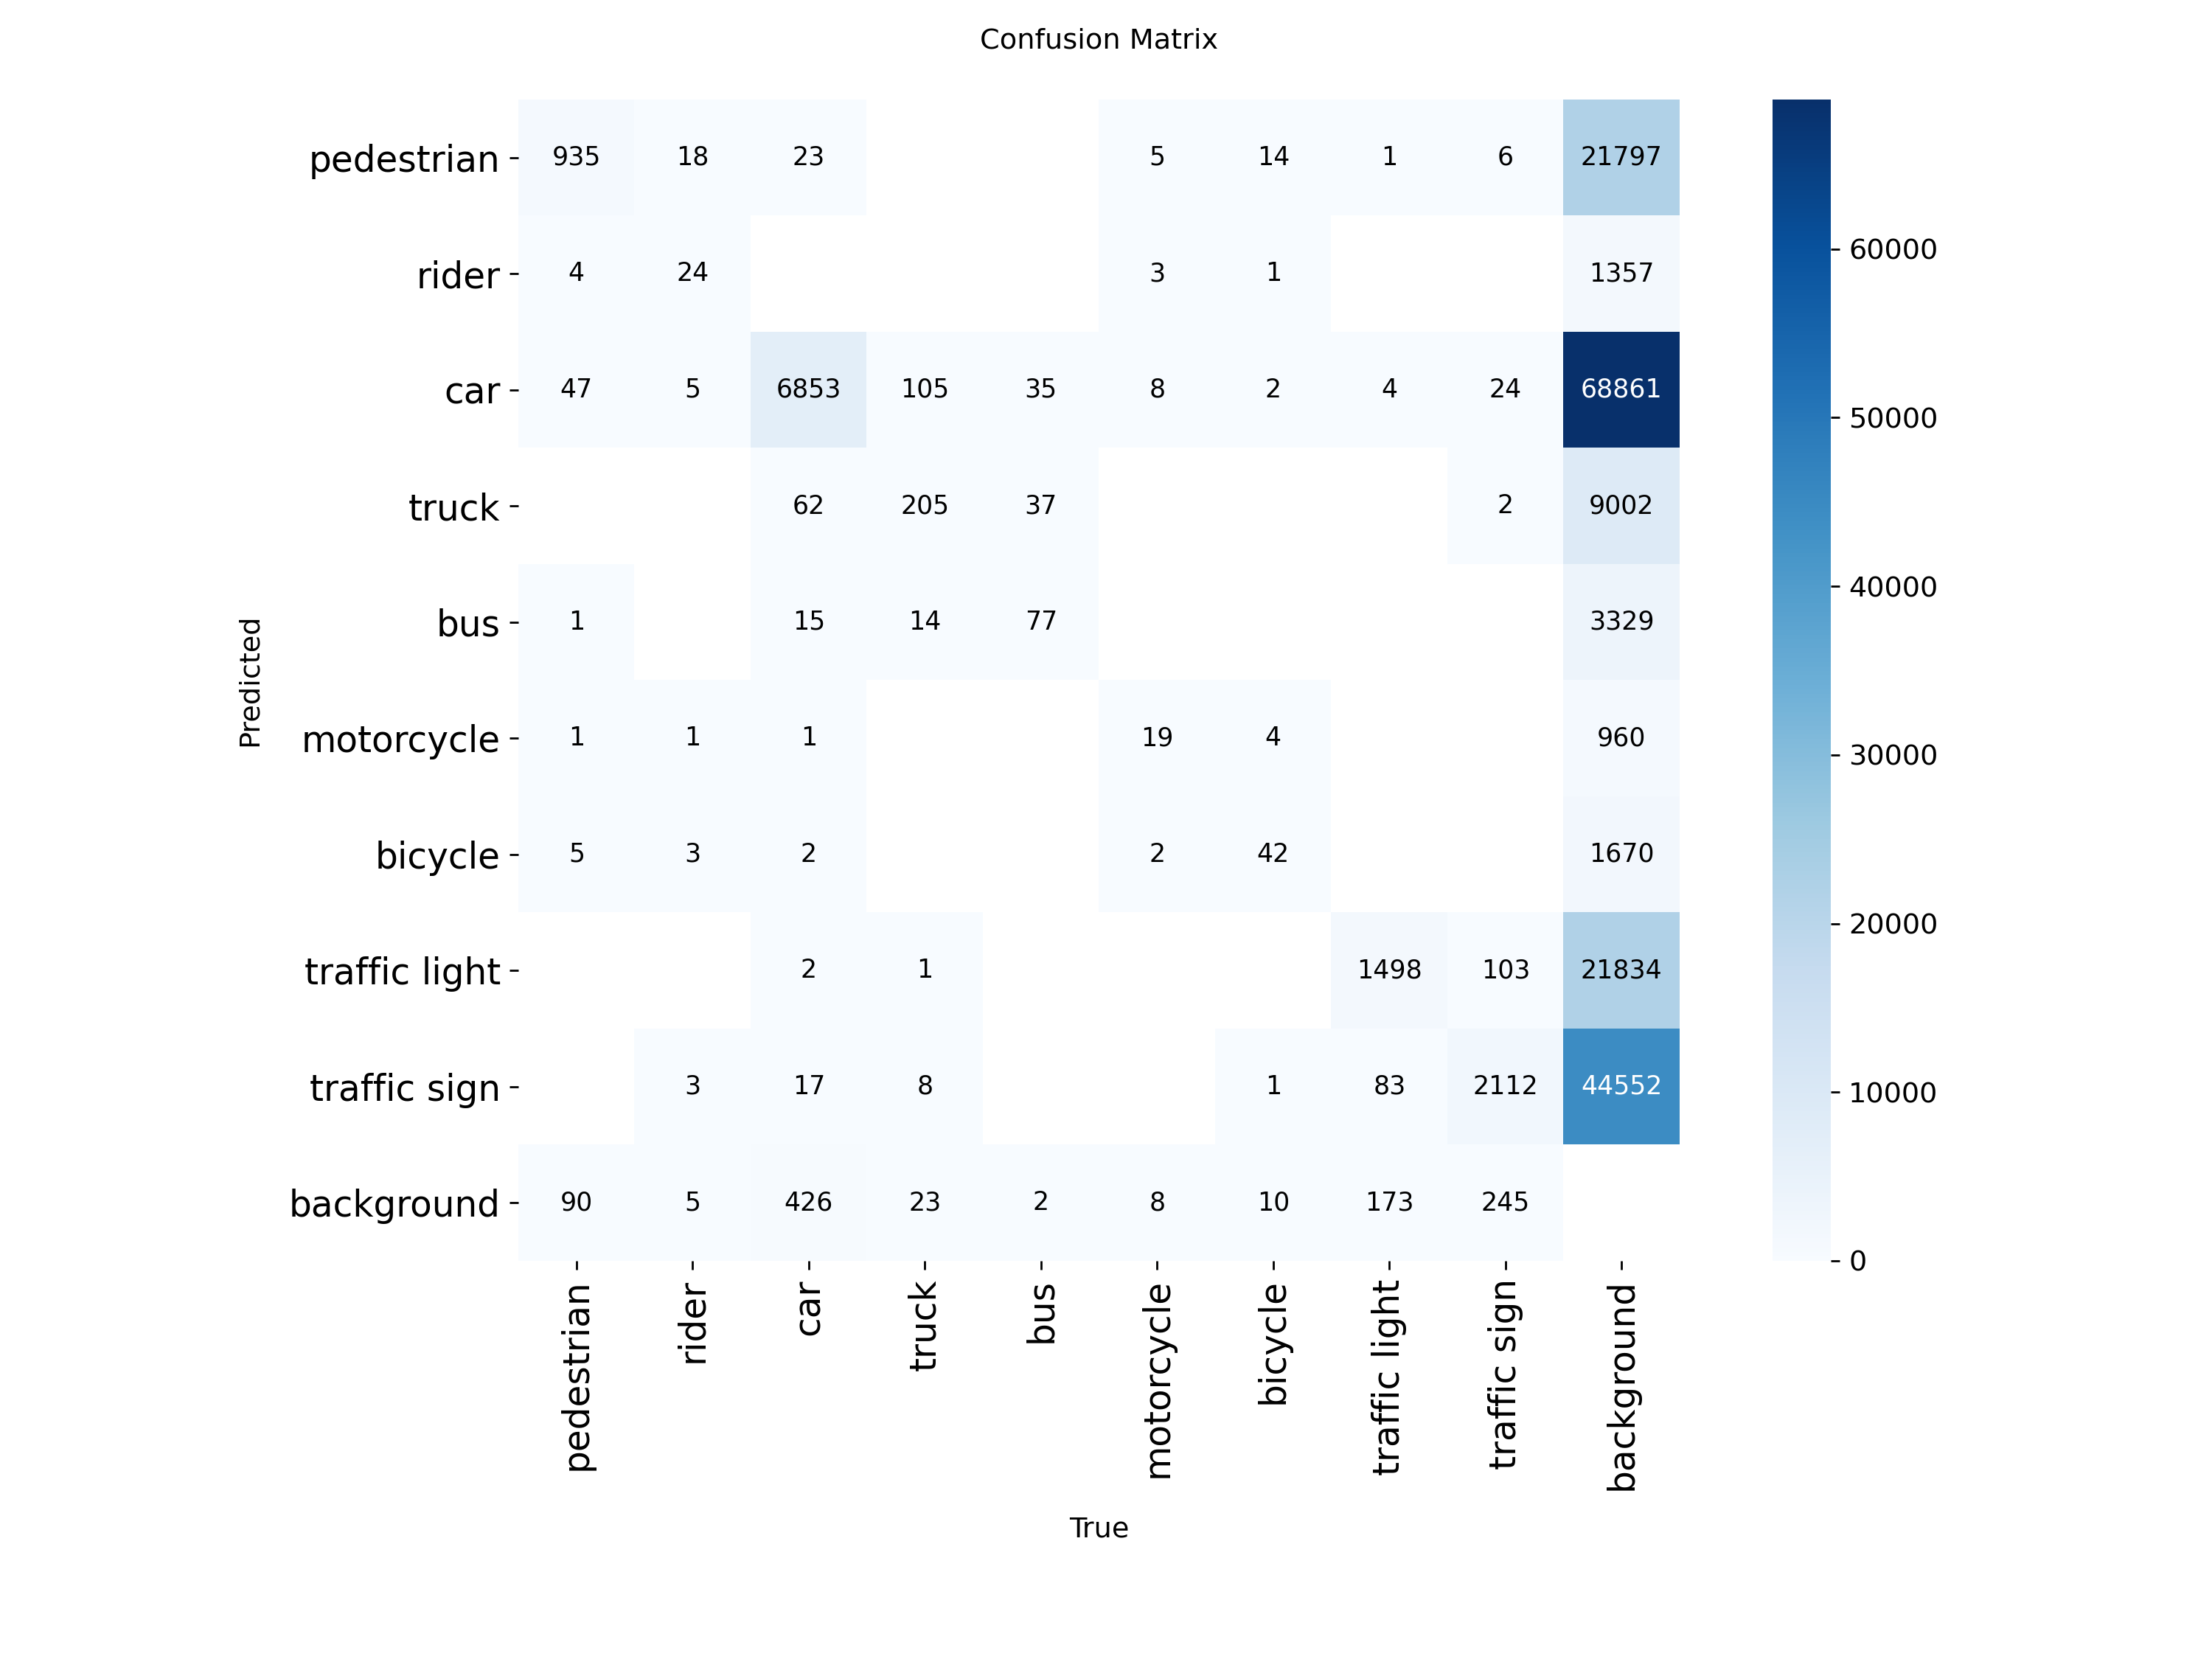

In [50]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "runs/drivesight_v2/v2_cls_pw025_mixup/confusion_matrix.png")))


<IPython.core.display.Image object>

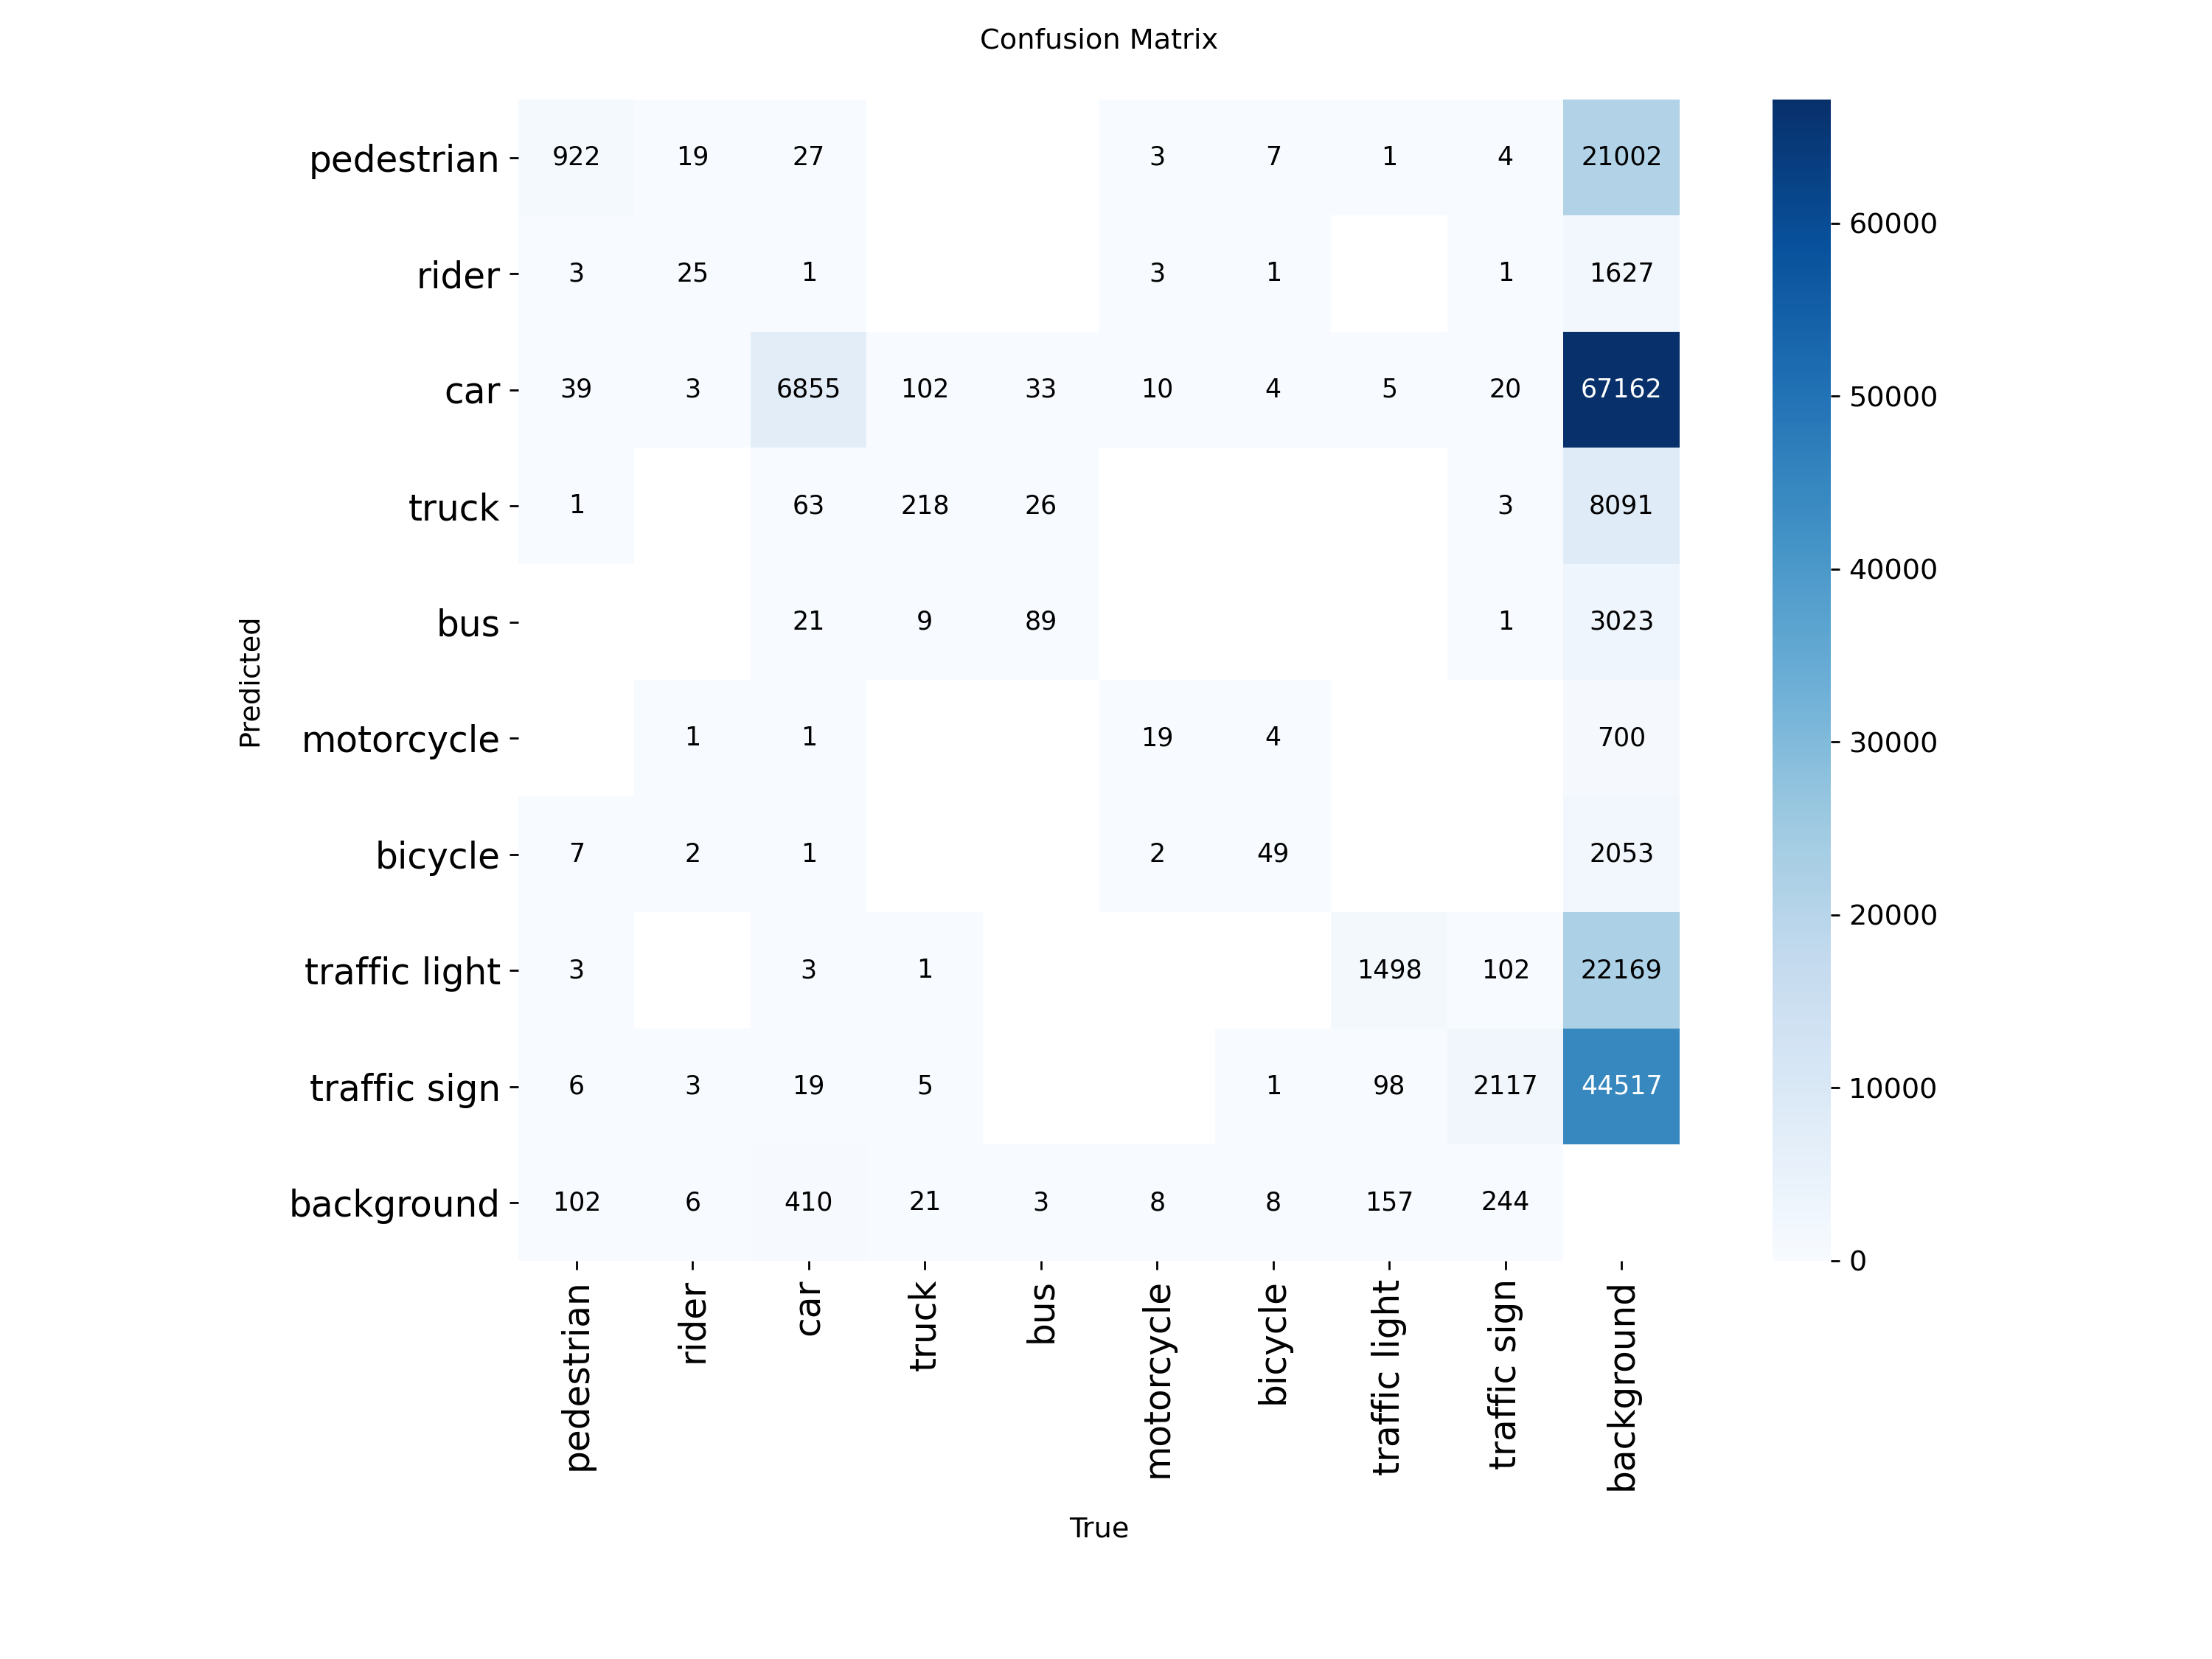

In [51]:
from IPython.display import Image, display
display(Image(str(PROJECT_ROOT / "reports/drivesight_v2/evaluation/cls_pw025_vs_others/v2_cls_pw025/confusion_matrix.png")))


Read off the two matrices (they are only saved as images, so these counts were transcribed by eye and are
worth re-checking against the figures): **rider → pedestrian is essentially unchanged** (18 for MixUp vs 19
for `v2_cls_pw025`), correctly detected riders 24 vs 25, motorcycles 19 vs 19; **bicycles misread as
pedestrians rise from 7 to 14** and correctly detected bicycles fall from 49 to 42. The cluster that dominates
every confusion matrix in this project — car / truck / bus — is visibly the same size in both. Nothing in
these matrices shows MixUp resolving the rider → pedestrian confusion.

### 13.9 Limitations and conclusion of the experiment

**Limitations.**
1. **One seed, one run.** Epoch-to-epoch noise is about as large as the best-epoch difference between runs
   (13.6); a single run cannot separate a real +0.5 from luck. Section 15 quantifies this with bootstrap
   intervals over *images* — which captures test-set sampling noise but **not** training-run-to-run variance.
2. **Best epoch chosen on the validation split**, so validation numbers are optimistic for every run.
3. **Tiny VRU samples** (13.2): per-class VRU differences are a few objects.
4. **Only `mixup=0.15` was tested**, and neither run reached the `close_mosaic` fine-tuning phase (epochs
   141–150), so neither received the augmentation-free polish the schedule was designed to end with.
5. **Three memory-pressure interruptions.** Proven lossless by the contiguity and backup checks above, but the
   run's wall-clock history is not a clean uninterrupted trace.

**Conclusion of the experiment itself.** MixUp trained stably, behaved as its source says it should, and
produced a checkpoint that is *comparable to* `v2_cls_pw025` — a small advantage in global recall / mAP50-95 at
validation, no VRU-specific benefit, a motorcycle precision drop, and no change to rider → pedestrian
confusion. Whether any of this is more than noise, and what to do with the checkpoint, is decided in Sections
14–15.

## 14. Phase 1 — Validation Diagnostics

Sections 13.7–13.8 gave aggregate validation metrics. They cannot say *what kind* of errors MixUp changed —
which is the question that matters, because MixUp was proposed specifically to attack the `true_miss` failure
mode of the rare VRU classes (13.1). This section is a **validation-only** diagnostic of `best.pt` for
`v2_cls_pw025_mixup` against the existing `v2_cls_pw025` analysis, run *before* any test-set comparison, so that
the test evaluation (Section 15) would not be the first time anyone looked at what the model does. Four analyses,
all inference-only (no training), all at the project's standard settings — `imgsz=1152`, NMS `iou=0.70`,
match-IoU 0.50, reference confidence 0.25 (the project-wide constant, never tuned):

1. **cause-of-miss categorisation** of every missed ground truth (`recall_diagnosis.py` logic, 14.2);
2. **false positives, false negatives and class confusion** (`audit_validation_errors.py` logic, 14.3);
3. **VRU recall by time of day** (a new analysis, 14.4);
4. a test of the **low-light hypothesis** that the earlier visual evidence had suggested (14.5).

The implementation of all four is embedded below. Raw outputs are in `reports/drivesight_v2/evaluation/mixup_phase1/`.
The MixUp checkpoint (and the `v2_cls_pw025` one) were hashed before and after; the cell confirms they were not
touched:

In [52]:
P1 = EVALD / "mixup_phase1"
before = (P1 / "checkpoint_hashes_before.txt").read_text().split()
after = (P1 / "checkpoint_hashes_after.txt").read_text().split()
print(" ".join(f"{h[:12]}...  {p}" for h, p in zip(before[0::2], before[1::2])).replace(" runs/", "\nruns/", 1))
print("\nchecksums of both best.pt files identical before and after Phase 1:", before == after)


94c22d0b56f9...  *runs/drivesight_v2/v2_cls_pw025_mixup/weights/best.pt 49df5d8da855...  *runs/drivesight_v2/v2_cls_pw025/weights/best.pt

checksums of both best.pt files identical before and after Phase 1: True

### 14.1 Shared building blocks — the project matcher and the time-of-day lookup

The same diagnostic matcher as Section 9.1 (same-class greedy IoU matches first, then cross-class confusions
among what is left, then misses / unmatched predictions), written here to return confusion pairs keyed by class
*name*, plus the BDD100K time-of-day lookup and the grouped-recall function used in 14.4. (**A lookup bug that
was found and fixed during this phase is documented in the docstring and again in 14.4.**)

In [53]:
import json
from collections import Counter, defaultdict
from pathlib import Path

CLASS_NAMES = ["pedestrian", "rider", "car", "truck", "bus", "motorcycle", "bicycle",
               "traffic light", "traffic sign"]
CID = {n: i for i, n in enumerate(CLASS_NAMES)}


def box_iou_pair(a, b):
    """IoU between two xyxy boxes."""
    x1, y1 = max(a[0], b[0]), max(a[1], b[1]); x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    union = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1]) + max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1]) - inter
    return inter / union if union > 0 else 0.0


def match_detections_named(ground_truth, predictions, match_iou):
    """The project's diagnostic matcher (same algorithm as Section 9.1), returning confusion pairs keyed by class
    NAME: same-class greedy IoU matches first, then cross-class confusions among what is left; whatever remains
    is a miss / an unmatched prediction. Used for every FP / FN / confusion count at a fixed confidence."""
    used_gt, used_pred, confusion_pairs = set(), set(), Counter()
    cand = [(box_iou_pair(g["box"], p["box"]), gi, pi)
            for gi, g in enumerate(ground_truth) for pi, p in enumerate(predictions)
            if g["class_id"] == p["class_id"] and box_iou_pair(g["box"], p["box"]) >= match_iou]
    for ov, gi, pi in sorted(cand, reverse=True):
        if gi in used_gt or pi in used_pred:
            continue
        used_gt.add(gi); used_pred.add(pi)
    cand = [(box_iou_pair(g["box"], p["box"]), gi, pi)
            for gi, g in enumerate(ground_truth) if gi not in used_gt
            for pi, p in enumerate(predictions) if pi not in used_pred and g["class_id"] != p["class_id"]
            and box_iou_pair(g["box"], p["box"]) >= match_iou]
    for ov, gi, pi in sorted(cand, reverse=True):
        if gi in used_gt or pi in used_pred:
            continue
        used_gt.add(gi); used_pred.add(pi)
        confusion_pairs[(CLASS_NAMES[ground_truth[gi]["class_id"]], CLASS_NAMES[predictions[pi]["class_id"]])] += 1
    return {"missed_gt": [g for i, g in enumerate(ground_truth) if i not in used_gt],
            "unmatched_predictions": [p for i, p in enumerate(predictions) if i not in used_pred],
            "confusion_pairs": confusion_pairs}


def timeofday_of(stem, raw_root):
    """BDD100K time-of-day attribute of an image. The project's YOLO val split is drawn from SEVERAL original
    BDD100K label splits (a 10k-image 'val' image's label can sit in labels/100k/train), so all three raw
    splits must be searched. (The first Phase-1 attempt searched only 'val' and returned 'missing' for 589 of
    686 images -- Section 14.4.)"""
    for split in ("train", "val", "test"):
        path = Path(raw_root) / split / f"{stem}.json"
        if path.exists():
            try:
                return json.loads(path.read_text(encoding="utf-8"))["attributes"].get("timeofday", "undefined")
            except Exception:
                return "unreadable"
    return "missing"


def recall_by_group(preds_by_img, gt_by_img, group_by_img, thresholds, match_iou=0.50):
    """Per-class recall at several confidence thresholds, grouped (here: by time of day).
    preds_by_img[stem] = (class ids [n], confidences [n], xyxy-normalized boxes [n,4]); gt_by_img[stem] = (class
    ids, boxes). recall = (GT - missed - matched-to-the-wrong-class) / GT. Higher thresholds are derived by
    filtering the same candidate list (exact for standard class-wise greedy NMS)."""
    stats = {t: defaultdict(lambda: defaultdict(Counter)) for t in thresholds}
    for stem, (pcls, pconf, pbox) in preds_by_img.items():
        gcls, gbox = gt_by_img[stem]
        gts = [{"class_id": int(c), "box": b.tolist()} for c, b in zip(gcls, gbox)]
        for t in thresholds:
            keep = pconf >= t
            preds = [{"class_id": int(c), "box": b.tolist()} for c, b in zip(pcls[keep], pbox[keep])]
            m = match_detections_named(gts, preds, match_iou)
            missed = Counter(CLASS_NAMES[g["class_id"]] for g in m["missed_gt"])
            wrong = Counter(a for (a, _b), n in m["confusion_pairs"].items() for _ in range(n))
            for cls, n in Counter(CLASS_NAMES[g["class_id"]] for g in gts).items():
                for grp in (group_by_img[stem], "ALL"):
                    c = stats[t][grp][cls]
                    c["gt"] += n; c["missed"] += missed.get(cls, 0); c["wrong_class"] += wrong.get(cls, 0)
    rows = []
    for t, groups in stats.items():
        for grp, classes in groups.items():
            for cls, c in classes.items():
                det = c["gt"] - c["missed"] - c["wrong_class"]
                rows.append({"threshold": t, "timeofday": grp, "class": cls, "n_gt": c["gt"],
                             "detected_correct": det, "missed_no_match": c["missed"],
                             "matched_wrong_class": c["wrong_class"], "recall": det / c["gt"]})
    return rows

print('defined: box_iou_pair, match_detections_named, timeofday_of, recall_by_group')


defined: box_iou_pair, match_detections_named, timeofday_of, recall_by_group

### 14.2 Cause-of-miss categorisation — the implementation

Every ground truth that is not correctly detected at the reference confidence 0.25 is a *miss*, and is
assigned to exactly one cause by looking at the **full low-confidence candidate pool** (the project used
`conf ≥ 0.05`): *incorrect classification* (matched to the wrong class), *low confidence* (the right class is
there at IoU ≥ 0.5 but below the threshold), *poor localisation* (right class nearby, box too loose) or *true
miss* (no right-class signal anywhere). This is the logic of `recall_diagnosis.py`, kept identical; the toy
example at the end uses synthetic boxes (not project data) to show one miss of each kind:

In [54]:
def greedy_match_full(ground_truth, predictions, match_iou):
    """Same two-pass matcher as match_detections_named, additionally returning WHICH ground-truth index was
    matched to which wrong class (needed to label a miss as 'incorrect_classification')."""
    used_gt, used_pred = set(), set()
    same_class = [(box_iou_pair(g["box"], p["box"]), gi, pi)
                  for gi, g in enumerate(ground_truth) for pi, p in enumerate(predictions)
                  if g["class_id"] == p["class_id"] and box_iou_pair(g["box"], p["box"]) >= match_iou]
    for ov, gi, pi in sorted(same_class, reverse=True):
        if gi in used_gt or pi in used_pred:
            continue
        used_gt.add(gi); used_pred.add(pi)
    cross_class = [(box_iou_pair(g["box"], p["box"]), gi, pi)
                   for gi, g in enumerate(ground_truth) if gi not in used_gt
                   for pi, p in enumerate(predictions) if pi not in used_pred and g["class_id"] != p["class_id"]
                   and box_iou_pair(g["box"], p["box"]) >= match_iou]
    confused_gt = {}
    for ov, gi, pi in sorted(cross_class, reverse=True):
        if gi in used_gt or pi in used_pred:
            continue
        used_gt.add(gi); used_pred.add(pi)
        confused_gt[gi] = CLASS_NAMES[predictions[pi]["class_id"]]
    return used_gt, confused_gt


def size_bucket(area_px):
    """COCO-style size buckets used throughout the project's error analysis (pixel area of the GT box)."""
    return "small" if area_px < 1024 else ("medium" if area_px < 9216 else "large")


def diagnose_misses(ground_truth, all_preds, reference_threshold=0.25, match_iou=0.50, localization_iou_floor=0.10):
    """Cause-of-miss categorisation (the logic of recall_diagnosis.py, transferred). all_preds is the FULL
    low-confidence candidate pool (the project used conf >= 0.05); [{class_id, box, confidence}, ...].
    A ground truth that is not correctly matched (same class, IoU >= match_iou) at the reference threshold is a
    miss, categorised as exactly one of:
      incorrect_classification - matched to the WRONG class at IoU >= match_iou
      low_confidence           - the right class exists at IoU >= match_iou somewhere in the pool, just below threshold
      poor_localization        - the right class exists nearby (IoU >= floor) but too loosely boxed to count
      true_miss                - no right-class signal at any confidence in the pool"""
    preds_ref = [p for p in all_preds if p["confidence"] >= reference_threshold]
    used_gt, confused_gt = greedy_match_full(ground_truth, preds_ref, match_iou)
    correct_gt = used_gt - set(confused_gt)
    out = []
    for gi, gt in enumerate(ground_truth):
        if gi in correct_gt:
            continue
        if gi in confused_gt:
            out.append({"gt_index": gi, "class": CLASS_NAMES[gt["class_id"]], "cause": "incorrect_classification",
                        "predicted_as": confused_gt[gi], "best_right_class_iou": None, "best_right_class_conf": None})
            continue
        best_iou, best_conf = 0.0, None
        for p in all_preds:
            if p["class_id"] != gt["class_id"]:
                continue
            ov = box_iou_pair(gt["box"], p["box"])
            if ov > best_iou:
                best_iou, best_conf = ov, p["confidence"]
        cause = ("low_confidence" if best_iou >= match_iou else
                 "poor_localization" if best_iou >= localization_iou_floor else "true_miss")
        out.append({"gt_index": gi, "class": CLASS_NAMES[gt["class_id"]], "cause": cause, "predicted_as": None,
                    "best_right_class_iou": round(best_iou, 3), "best_right_class_conf": best_conf})
    return out


# --- ILLUSTRATIVE TOY EXAMPLE (synthetic boxes, NOT project data): one GT of each cause + one correct detection ---
toy_gt = [
    {"class_id": 2, "box": [0.10, 0.10, 0.30, 0.40]},   # car       -> detected correctly (not a miss)
    {"class_id": 1, "box": [0.50, 0.20, 0.55, 0.45]},   # rider     -> confidently called pedestrian
    {"class_id": 6, "box": [0.70, 0.70, 0.75, 0.90]},   # bicycle   -> right class, but conf 0.12 < 0.25
    {"class_id": 5, "box": [0.20, 0.60, 0.30, 0.80]},   # motorcycle-> right class nearby, box too loose
    {"class_id": 0, "box": [0.80, 0.10, 0.85, 0.30]},   # pedestrian-> nothing at all
]
toy_pool = [
    {"class_id": 2, "box": [0.11, 0.09, 0.29, 0.41], "confidence": 0.90},
    {"class_id": 0, "box": [0.50, 0.20, 0.55, 0.45], "confidence": 0.80},
    {"class_id": 6, "box": [0.70, 0.70, 0.75, 0.90], "confidence": 0.12},
    {"class_id": 5, "box": [0.22, 0.62, 0.40, 0.95], "confidence": 0.60},
]
for row in diagnose_misses(toy_gt, toy_pool):
    print(row["class"].ljust(11), "->", row["cause"], "" if row["predicted_as"] is None else f"(as {row['predicted_as']})")


rider       -> incorrect_classification (as pedestrian)
bicycle     -> low_confidence 
motorcycle  -> poor_localization 
pedestrian  -> true_miss 

### 14.3 Results: causes of miss, false positives, false negatives, confusion

All numbers below are produced by running exactly the logic above (via the project's scripts) on real model
predictions and read here from the saved CSVs: `v2_cls_pw025` from the earlier analysis
(`cls_pw025_recall_diagnosis/`, `cls_pw025_vs_others/error_audit/`), MixUp from `mixup_phase1/`. Validation
split, 686 images, 13,420 ground-truth objects. Cells read *pw025 → MixUp*.

Cause of miss at conf 0.25, validation split  (v2_cls_pw025 -> v2_cls_pw025_mixup)
              all misses   true_miss low_confidence poor_localization incorrect_classification
pedestrian    439 -> 459  162 -> 161     181 -> 187         86 -> 101                 10 -> 10
rider           38 -> 35    19 -> 21         6 -> 2            1 -> 1                 12 -> 11
motorcycle      30 -> 29    20 -> 17         1 -> 2            3 -> 3                   6 -> 7
bicycle         47 -> 50    24 -> 28       14 -> 11            7 -> 8                   2 -> 3
car         1975 -> 1948  295 -> 283     886 -> 878        758 -> 759                 36 -> 28
truck         169 -> 185    69 -> 69       24 -> 32          10 -> 11                 66 -> 73
bus             72 -> 73    22 -> 26        11 -> 5            5 -> 3                 34 -> 39

Total misses over all 9 classes: 4562 -> 4559

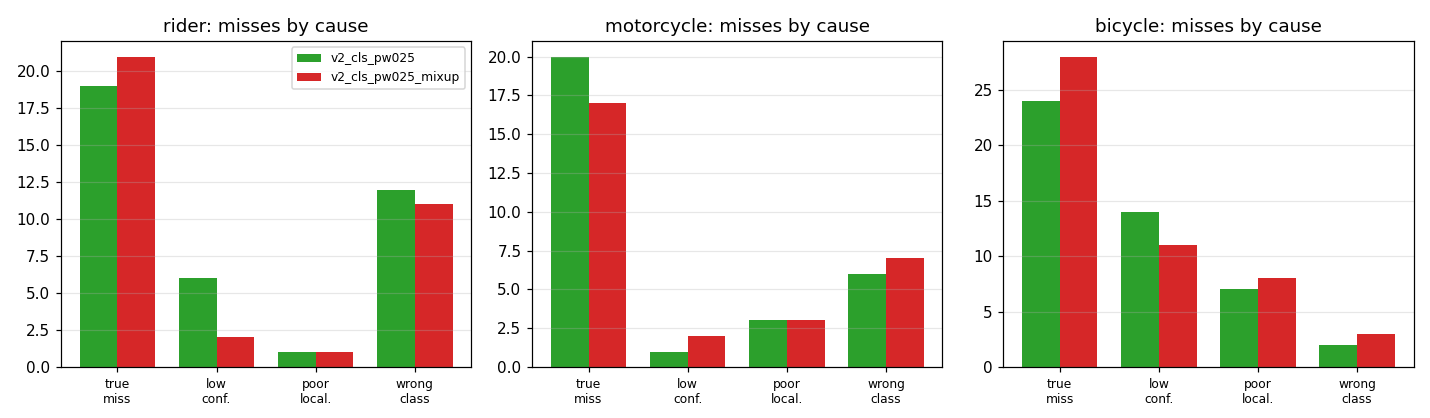

In [55]:
CAUSES = ["true_miss", "low_confidence", "poor_localization", "incorrect_classification"]
def cause_counts(path):
    d = pd.read_csv(path)
    return d.groupby(["class", "cause"]).size().unstack(fill_value=0).reindex(columns=CAUSES, fill_value=0)

ca = cause_counts(EVALD / "cls_pw025_recall_diagnosis/missed_object_causes.csv")
cb = cause_counts(EVALD / "mixup_phase1/recall_diagnosis/missed_object_causes.csv")
order = ["pedestrian", "rider", "motorcycle", "bicycle", "car", "truck", "bus"]
tab = pd.DataFrame({c: [f"{ca.loc[k, c]} -> {cb.loc[k, c]}" for k in order] for c in CAUSES}, index=order)
tab.insert(0, "all misses", [f"{ca.loc[k].sum()} -> {cb.loc[k].sum()}" for k in order])
print("Cause of miss at conf 0.25, validation split  (v2_cls_pw025 -> v2_cls_pw025_mixup)")
print(tab.to_string())
print(f"\nTotal misses over all 9 classes: {int(ca.values.sum())} -> {int(cb.values.sum())}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for ax, cls in zip(axes, ["rider", "motorcycle", "bicycle"]):
    x = np.arange(len(CAUSES)); w = 0.38
    ax.bar(x - w / 2, ca.loc[cls, CAUSES].values, w, label="v2_cls_pw025", color="tab:green")
    ax.bar(x + w / 2, cb.loc[cls, CAUSES].values, w, label="v2_cls_pw025_mixup", color="tab:red")
    ax.set_xticks(x); ax.set_xticklabels(["true\nmiss", "low\nconf.", "poor\nlocal.", "wrong\nclass"], fontsize=8)
    ax.set_title(f"{cls}: misses by cause"); ax.grid(alpha=0.3, axis="y")
axes[0].legend(fontsize=8)
plt.tight_layout(); plt.savefig("_tmp_master_nb_phase1_causes.png", dpi=110); plt.show()


In [56]:
AUD = {"pw025": EVALD / "cls_pw025_vs_others/error_audit/v2_cls_pw025", "MixUp": EVALD / "mixup_phase1/error_audit"}
print("Audit totals (conf 0.25, validation):")
print(pd.DataFrame({k: dict(pd.read_csv(v / "summary_totals.csv").values) for k, v in AUD.items()}).to_string())

fp = {k: pd.read_csv(v / "unmatched_predictions.csv").set_index("class")["unmatched_predictions"] for k, v in AUD.items()}
fn = {k: pd.read_csv(v / "missed_objects.csv").set_index("class")["missed_objects"] for k, v in AUD.items()}
rows = [{"class": c, "FP pw025": fp["pw025"].get(c, 0), "FP MixUp": fp["MixUp"].get(c, 0),
         "FN (no match) pw025": fn["pw025"].get(c, 0), "FN (no match) MixUp": fn["MixUp"].get(c, 0)}
        for c in VRU4 + ["car"]]
print("\nFalse positives (unmatched predictions) and false negatives (ground truths with no match), conf 0.25:")
print(pd.DataFrame(rows).set_index("class").to_string())

print("\nClass confusions involving a VRU class (true -> predicted : count), pw025 vs MixUp:")
conf = {k: pd.read_csv(v / "class_confusions.csv") for k, v in AUD.items()}
pairs = sorted({(r.true_class, r.predicted_class) for d in conf.values() for r in d.itertuples()
                if r.true_class in VRU4 or r.predicted_class in VRU4})
out = []
for t, p in pairs:
    g = lambda d: int(d[(d.true_class == t) & (d.predicted_class == p)]["count"].sum())
    out.append({"true -> predicted": f"{t} -> {p}", "pw025": g(conf["pw025"]), "MixUp": g(conf["MixUp"])})
print(pd.DataFrame(out).sort_values(["pw025", "MixUp"], ascending=False).to_string(index=False))


Audit totals (conf 0.25, validation):
                       pw025  MixUp
images                   686    686
ground_truth_objects   13420  13420
predictions            12726  12695
correct                 8858   8861
confused                 202    213
missed                  4360   4346
unmatched_predictions   3666   3621

False positives (unmatched predictions) and false negatives (ground truths with no match), conf 0.25:
            FP pw025  FP MixUp  FN (no match) pw025  FN (no match) MixUp
class                                                                   
pedestrian       371       305                  429                  449
rider              8         8                   26                   24
motorcycle         3         9                   24                   22
bicycle           21        17                   45                   47
car             1742      1720                 1939                 1920

Class confusions involving a VRU class (true -> predicted :

**What the diagnostics say.**
- **The failure profile did not change.** Total misses are 4,562 vs 4,559. For the three rare VRU classes the
  dominant cause stays `true_miss`, and MixUp does **not** reduce it: rider 19 → 21, motorcycle 20 → 17,
  bicycle 24 → 28 (the pre-stated measurement of 13.1). The measured effect on the failure mode MixUp was
  chosen to attack is therefore nil — within a few objects either way, on 45–74 instances per class.
- **Pedestrian**: false positives fall by 18 % (371 → 305), but poor-localisation misses rise
  (86 → 101) and no-match false negatives rise (429 → 449) — consistent with the small recall loss at the fixed
  threshold seen in 14.4 and again, with an interval, in Section 15.
- **Motorcycle false positives rise from 3 to 9**, which is the mechanism behind the validation precision drop
  for that class in 13.7 — a handful of boxes. Bicycle FP 21 → 17, rider FP unchanged at 8.
- **Rider → pedestrian is unchanged at 9** (the single most-tracked confusion of the whole project, Sections
  5.2 and 9.2); **bicycle → pedestrian appears (2)**, absent for `v2_cls_pw025`. Neither class of change is
  large enough to be distinguished from noise here.

**Robustness check.** The numbers above come from running the scripts with `model.predict(conf=0.05)`.
Section 15's evaluation caches the predictions of `val()` itself instead. The two inference paths differ
slightly (single-image letterboxing vs batched rectangular inference), so the embedded code can be re-run on
the cached `val()` predictions as an independent check of the same conclusions — individual counts move by a
few objects (up to six here), but MixUp still shows no reduction of `true_miss` for any rare VRU class:

In [57]:
import pickle
from collections import Counter

rows = []
for model, label in (("v2_cls_pw025", "pw025"), ("v2_cls_pw025_mixup", "MixUp")):
    d = pickle.load(open(EVALD / f"phase2_dryrun_val_v2/predictions_{model}.pkl", "rb"))   # val() predictions, conf >= 0.001
    recomputed = Counter()
    for stem in d["stems"]:
        pc, pf, pb = d["preds"][stem]
        gc, gb = d["gt"][stem]
        if len(gc) == 0:
            continue
        keep = pf >= 0.05                                      # the project's candidate-pool floor
        pool = [{"class_id": int(c), "box": b.tolist(), "confidence": float(f)} for c, b, f in zip(pc[keep], pb[keep], pf[keep])]
        gts = [{"class_id": int(c), "box": b.tolist()} for c, b in zip(gc, gb)]
        for r in diagnose_misses(gts, pool):
            recomputed[(r["class"], r["cause"])] += 1
    saved = ca if label == "pw025" else cb
    for cls in ("rider", "motorcycle", "bicycle"):
        rows.append({"model": label, "class": cls, **{f"{c} (saved/recomputed)": f"{int(saved.loc[cls, c])}/{recomputed[(cls, c)]}" for c in CAUSES}})
print(pd.DataFrame(rows).to_string(index=False))


model      class true_miss (saved/recomputed) low_confidence (saved/recomputed) poor_localization (saved/recomputed) incorrect_classification (saved/recomputed)
pw025      rider                        19/15                               6/3                                  1/4                                       12/13
pw025 motorcycle                        20/18                               1/2                                  3/2                                         6/9
pw025    bicycle                        24/23                             14/20                                  7/6                                         2/2
MixUp      rider                        21/19                               2/3                                  1/2                                       11/12
MixUp motorcycle                        17/18                               2/5                                  3/5                                         7/4
MixUp    bicycle                  

### 14.4 VRU recall by time of day

**Why this analysis exists.** The earlier visual evidence (Section 9.3) suggested that low light was a recurring
contributor to rider/bicycle failures. That was three hand-picked failure images, not a measurement. The
validation split carries BDD100K's per-image `timeofday` attribute, so the claim can be tested directly:
*is VRU recall lower at dawn/dusk and night than in daylight?*

**A bug found and fixed along the way — documented, not hidden.** The first run of this analysis looked up the
attribute only in the raw `val` label folder and returned `missing` for **589 of 686 images** — because the
project's YOLO validation split is drawn from *several* original BDD100K label splits (Section 2.2: the
10k image package and the 100k label folders are matched globally, so an image's label can sit in a different
raw split than the image itself — here, mostly in `labels/100k/train`). Its output folder (`timeofday/`) is kept on disk
as evidence and must be ignored; the corrected lookup (`timeofday_of` in 14.1, which searches all three raw
splits) produced `timeofday_all_splits/`, the only valid result:

In [58]:
first = json.loads((P1 / "timeofday/run_config.json").read_text())
fixed = json.loads((P1 / "timeofday_all_splits/run_config.json").read_text())
print("FIRST attempt (invalid; searched only raw 'val'):", first["timeofday_counts"])
print("FIXED lookup (all raw splits, 686 images)       :", fixed["timeofday_counts"])

tod = pd.read_csv(P1 / "timeofday_all_splits/recall_by_timeofday.csv")
def cell(model, thr, grp, classes):
    s = tod[(tod.model == model) & (tod.threshold == thr) & (tod.timeofday == grp) & (tod["class"].isin(classes))]
    n, d = int(s.n_gt.sum()), int(s.detected_correct.sum())
    return n, d
print("\nVRU recall by time of day, conf 0.25, validation split  (correctly detected / ground truth)")
rows = []
for grp in ("daytime", "dawn/dusk", "night", "ALL"):
    for name, classes in (("pedestrian", ["pedestrian"]), ("rider", ["rider"]), ("motorcycle", ["motorcycle"]),
                          ("bicycle", ["bicycle"]), ("RIDER+MOTO+BIKE pooled", ["rider", "motorcycle", "bicycle"])):
        n, da = cell("v2_cls_pw025", 0.25, grp, classes); _, db = cell("v2_cls_pw025_mixup", 0.25, grp, classes)
        if n:
            rows.append({"time of day": grp, "class": name, "n_gt": n, "pw025": f"{da}/{n} = {100*da/n:.1f}%",
                         "MixUp": f"{db}/{n} = {100*db/n:.1f}%"})
print(pd.DataFrame(rows).to_string(index=False))

# the same grouped analysis at the lower threshold 0.10 (pooled VRU only)
print("\nPooled rider+motorcycle+bicycle at conf 0.10:")
for grp in ("daytime", "dawn/dusk", "night", "ALL"):
    n, da = cell("v2_cls_pw025", 0.1, grp, ["rider", "motorcycle", "bicycle"]); _, db = cell("v2_cls_pw025_mixup", 0.1, grp, ["rider", "motorcycle", "bicycle"])
    print(f"  {grp:10s} n={n:3d}   pw025 {da}/{n} = {100*da/n:5.1f}%   MixUp {db}/{n} = {100*db/n:5.1f}%")


FIRST attempt (invalid; searched only raw 'val'): {'missing': 589, 'daytime': 80, 'dawn/dusk': 11, 'night': 5, 'undefined': 1}
FIXED lookup (all raw splits, 686 images)       : {'daytime': 575, 'dawn/dusk': 83, 'night': 25, 'undefined': 3}

VRU recall by time of day, conf 0.25, validation split  (correctly detected / ground truth)
time of day                  class  n_gt            pw025            MixUp
    daytime             pedestrian   935  552/935 = 59.0%  535/935 = 57.2%
    daytime                  rider    51    18/51 = 35.3%    21/51 = 41.2%
    daytime             motorcycle    38    10/38 = 26.3%    11/38 = 28.9%
    daytime                bicycle    70    25/70 = 35.7%    22/70 = 31.4%
    daytime RIDER+MOTO+BIKE pooled   159   53/159 = 33.3%   54/159 = 34.0%
  dawn/dusk             pedestrian   132   88/132 = 66.7%   85/132 = 64.4%
  dawn/dusk                  rider     7      3/7 = 42.9%      3/7 = 42.9%
  dawn/dusk             motorcycle     6      5/6 = 83.3%      5/6 

**Robustness check** — the same grouped recall recomputed with the embedded `recall_by_group` on the cached
`val()` predictions (a different inference path from the saved Phase 1 run above; the counts move by a
few objects):

In [59]:
RAW_LABELS = PROJECT_ROOT / "data/bdd100k/labels/100k"
rows = []
for model, label in (("v2_cls_pw025", "pw025"), ("v2_cls_pw025_mixup", "MixUp")):
    d = pickle.load(open(EVALD / f"phase2_dryrun_val_v2/predictions_{model}.pkl", "rb"))
    groups = {s: timeofday_of(s, RAW_LABELS) for s in d["stems"]}
    res = recall_by_group(d["preds"], d["gt"], groups, thresholds=[0.25])
    for grp in ("daytime", "dawn/dusk", "night"):
        sel = [r for r in res if r["timeofday"] == grp and r["class"] in ("rider", "motorcycle", "bicycle")]
        n = sum(r["n_gt"] for r in sel); det = sum(r["detected_correct"] for r in sel)
        rows.append({"model": label, "time of day": grp, "pooled rider+moto+bike": f"{det}/{n} = {100*det/n:.1f}%"})
print(pd.DataFrame(rows).to_string(index=False))


model time of day pooled rider+moto+bike
pw025     daytime         50/159 = 31.4%
pw025   dawn/dusk          11/16 = 68.8%
pw025       night             0/3 = 0.0%
MixUp     daytime         51/159 = 32.1%
MixUp   dawn/dusk           9/16 = 56.2%
MixUp       night             0/3 = 0.0%

Note the size of the swings on 16 dawn/dusk ground truths: the recomputation gives 11/16 for `v2_cls_pw025` and 9/16
for MixUp (a two-object difference, in the *opposite* direction to the saved run's 10/16 vs 10/16) — which is what
"indistinguishable" looks like at this sample size. In every version dawn/dusk recall (56–69 %) is at or above
daytime recall (31–34 %).

### 14.5 The low-light hypothesis — and why the evidence does not support it

**What the hypothesis rested on.** Two of the three failure images inspected in Section 9.3 were dim/dusk scenes
(the rider → pedestrian image and the bicycle behind a pole), and both Section 9.3 and 18.1 proposed low light
as a recurring contributor. That was a reading of three hand-picked images, not a measurement.

**What the measurement shows.** In the validation split, pooled over rider + motorcycle + bicycle (16 ground
truths at dawn/dusk, 159 in daylight, 3 at night — numbers in 14.4):

| | daytime | dawn/dusk | night |
|---|---:|---:|---:|
| `v2_cls_pw025` | 53/159 = 33.3% | 10/16 = 62.5% | 0/3 |
| `v2_cls_pw025_mixup` | 54/159 = 34.0% | 10/16 = 62.5% | 0/3 |

- **VRU recall is already low in full daylight (about one in three).** Dawn/dusk recall is, if anything,
  *higher* than daytime, not lower (though on only 16 objects). Whatever drives the VRU misses, it is not
  low light.
- **The night result cannot say anything**: 3 VRU ground truths in the whole validation split.
- **MixUp and `v2_cls_pw025` are indistinguishable in every lighting condition** on these pooled counts.
- **The only visible lighting-related difference is for pedestrians** (the large class: 935 daytime and 132
  dawn/dusk ground truths), where MixUp is slightly lower in both groups — the same small pedestrian-recall
  loss as in 14.3 and Section 15.

**Why the hypothesis was plausible but untestable at training time.** The training set contains almost no
night VRU data at all, which would limit what *any* lighting augmentation could teach:

Training-set images by BDD100K time of day (counts), 2,744 train images in total:
           all_train_images  rider_images  motorcycle_images  bicycle_images
timeofday                                                                   
dawn/dusk               297            19                  9              18
daytime                2330           173                116             199
night                   112             2                  0               3
undefined                 5             0                  0               0
TOTAL                  2744           194                125             220

Share of each column's images (percent):
           all_train_images  rider_images  motorcycle_images  bicycle_images
timeofday                                                                   
dawn/dusk              10.8           9.8                7.2             8.2
daytime                84.9          89.2               92.8            90.5
night                   4.1  

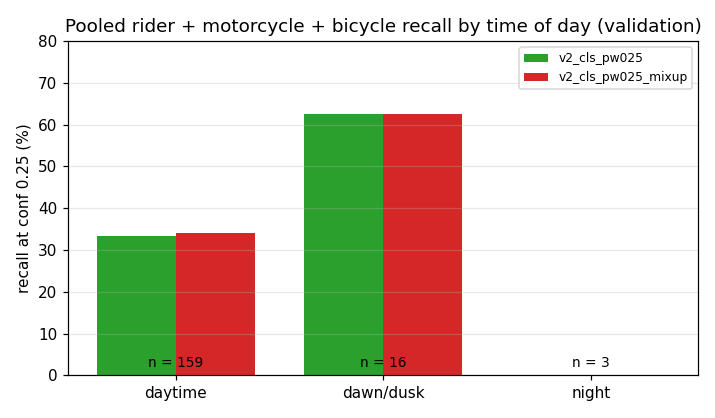

In [60]:
t = pd.read_csv(PROJECT_ROOT / "reports/drivesight_v2/vru_dataset_audit/scene_attr_timeofday_counts.csv").set_index("timeofday")
t.loc["TOTAL"] = t.sum()
share = (100 * t.div(t.loc["TOTAL"])).round(1)
print("Training-set images by BDD100K time of day (counts), 2,744 train images in total:")
print(t.to_string())
print("\nShare of each column's images (percent):")
print(share.to_string())

# figure: pooled VRU recall by time of day, with the number of ground truths annotated
fig, ax = plt.subplots(figsize=(6.5, 3.8))
grp_order = ["daytime", "dawn/dusk", "night"]
xs = np.arange(len(grp_order)); w = 0.38
for off, model, lab, col in ((-w / 2, "v2_cls_pw025", "v2_cls_pw025", "tab:green"), (w / 2, "v2_cls_pw025_mixup", "v2_cls_pw025_mixup", "tab:red")):
    vals = []
    for g in grp_order:
        n, d_ = cell(model, 0.25, g, ["rider", "motorcycle", "bicycle"]); vals.append(100 * d_ / n)
    ax.bar(xs + off, vals, w, label=lab, color=col)
for i, g in enumerate(grp_order):
    n, _ = cell("v2_cls_pw025", 0.25, g, ["rider", "motorcycle", "bicycle"])
    ax.text(i, 2, f"n = {n}", ha="center", fontsize=9)
ax.set_xticks(xs); ax.set_xticklabels(grp_order); ax.set_ylabel("recall at conf 0.25 (%)"); ax.set_ylim(0, 80)
ax.set_title("Pooled rider + motorcycle + bicycle recall by time of day (validation)")
ax.legend(fontsize=8); ax.grid(alpha=0.3, axis="y")
plt.tight_layout(); plt.savefig("_tmp_master_nb_phase1_timeofday.png", dpi=110); plt.show()


Only **2 rider, 0 motorcycle and 3 bicycle** training images are night scenes (1.0 %, 0 % and 1.4 % of those
classes' images; dusk/dawn is 7–10 %). So the honest statement is narrower than the original hypothesis:
*night VRU performance cannot be learned or measured with this data* — but **dusk/dawn is not where the VRUs are
failing, and daytime recall is already poor**. This changes the priority of any follow-up work:
**targeted low-light augmentation is *not* supported as a first lever** by this evidence.

### 14.6 Phase 1 summary — MixUp vs `v2_cls_pw025` on validation

| question | answer |
|---|---|
| Did MixUp reduce VRU `true_miss` (the pre-stated measure)? | **No**: rider 19→21, motorcycle 20→17, bicycle 24→28 |
| Did the failure profile change? | No: total misses 4,562 vs 4,559; same two failure regimes |
| Rider → pedestrian? | Unchanged (9 at conf 0.25); bicycle → pedestrian appears (2) |
| False positives? | Pedestrian −18 % (371→305); motorcycle 3→9 (a handful of boxes); car and rider ≈ flat |
| VRU recall by lighting? | Indistinguishable from `v2_cls_pw025` in every group; small pedestrian-recall loss |
| Is low light the VRU problem? | **Not supported**: dusk/dawn recall (62.5 %) ≥ daytime (33.3 %); night n = 3 |

The Phase 1 verdict was that MixUp **did not demonstrate a convincing improvement in VRU detection**, which
(together with the unresolved question of whether its small global gain was real) is what made the controlled
test-set comparison of Section 15 worth running — as a one-shot confirmation, with the decision rule fixed in
advance.

## 15. Phase 2 — Final Test-Set Evaluation

**Purpose.** Phase 1 (Section 14) said MixUp showed no convincing VRU improvement on validation, but validation
is the split every best epoch was chosen on, and its VRU classes are tiny. The question left was whether
MixUp's small global gain is *real*. This section answers it on held-out data with a protocol fixed in
advance: identical conditions for all three models, paired bootstrap confidence intervals, a **promotion
rule written down before the test run**, and checkpoint/dataset integrity verified before and after.

**An important honesty note about the test split.** It is *not* untouched any more: Section 12 already used it
twice (the three-checkpoint comparison, 12.2, and the frozen-profile check, 12.3), and the audit of Section
12.1 showed that **no checkpoint, threshold or hyperparameter was ever selected from test results**. This
evaluation is a **third look and is treated as a one-shot confirmation**: nothing here is tuned on test, the
decision rule was fixed beforehand, and the test split should not be used for model selection afterwards.

**What this notebook does and does not run.** As in Section 12, this notebook does **not** run inference on the
test split. The evaluation driver of 15.2 is embedded in full (guarded by `RUN_TEST_EVAL = False`); the
statistics code of 15.3 *is* run, but on the **already-saved prediction caches** from the real evaluation
(`final_test_set_with_mixup/predictions_*.pkl`), where it reproduces every saved number — so the code shown
is demonstrably the code that produced the results.

### 15.1 Protocol

| item | setting |
|---|---|
| split | `test`, 830 images, fingerprinted (image bytes, label contents, labels cache) before and after |
| checkpoints | `best.pt` of `v2_baseline` (epoch 91), `v2_cls_pw025` (epoch 91), `v2_cls_pw025_mixup` (epoch 86) |
| inference | `imgsz=1152`, NMS `iou=0.70`, `batch=8`, GPU 0, no test-time augmentation — **identical for all three** |
| mAP / AP | official Ultralytics `val()` (confidence floor 0.001), COCO-style IoU 0.50:0.05:0.95 |
| FP / FN / confusion | at the project's reference confidence **0.25**, match IoU 0.50 (never tuned on test) |
| uncertainty | paired image-level bootstrap, **2,000 replicates**, seed 12345, percentile 95 % intervals; the same resample is applied to all three models |
| promotion rule | fixed in advance (15.8): all three of three criteria must pass |
| thresholds | **none tuned**; the frozen inference profiles (Section 11) are not part of this comparison |

### 15.2 The evaluation driver — implementation

`run_final_eval` is the real driver (transferred from `archive/scripts/drivesight_v2/final_eval_driver.py`). It records
SHA-256 hashes of every checkpoint and a fingerprint of the split before anything runs; runs the official
Ultralytics `val()` with identical arguments for every model; caches the predictions `val()` itself produced
together with the ground truth; and re-hashes everything afterwards, **aborting if anything changed**. It
refuses to overwrite an existing output directory and refuses `split='test'` without an explicit confirmation
flag. One disclosed difference between this embedded version and the file that was executed for the test run:
the executed file passed a *relative* `project` path, which Ultralytics silently redirected to
`runs/detect/reports/…`; the plots were copied back into the evaluation directory afterwards (the numeric
results and caches were never affected) and the embedded code below uses the corrected absolute path — see
15.5.

In [61]:
RUN_TEST_EVAL = False   # HARD GUARD: with False (as shipped) the function below is only DEFINED, never called.

import csv
import hashlib
import json
import pickle
import platform
import time
from pathlib import Path

import numpy as np
import torch
import ultralytics
from PIL import Image
from ultralytics import YOLO

IMG_EXT = {".jpg", ".jpeg", ".png"}


def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            b = f.read(chunk)
            if not b:
                break
            h.update(b)
    return h.hexdigest()


def fingerprint_split(data_yaml, split):
    """SHA256 fingerprint of an evaluation split: every image's bytes, every label file's contents, and the
    Ultralytics labels-cache file. Recorded BEFORE and AFTER an evaluation; any difference aborts the run."""
    root = Path(data_yaml).parent
    img_dir, lbl_dir, cache = root / "images" / split, root / "labels" / split, root / "labels" / f"{split}.cache"
    images = sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXT)
    h_img, h_lbl = hashlib.sha256(), hashlib.sha256()
    for im in images:
        h_img.update(im.name.encode()); h_img.update(sha256_file(im).encode())
        lp = lbl_dir / f"{im.stem}.txt"
        h_lbl.update(im.stem.encode()); h_lbl.update(lp.read_bytes() if lp.exists() else b"<missing>")
    return {"n_images": len(images), "images_sha256": h_img.hexdigest(), "labels_sha256": h_lbl.hexdigest(),
            "labels_cache_sha256": sha256_file(cache) if cache.exists() else None}


def read_gt(label_path):
    """YOLO label file -> (class ids [n], normalized xyxy boxes [n,4])."""
    cls, boxes = [], []
    if Path(label_path).exists():
        for line in Path(label_path).read_text(encoding="utf-8").splitlines():
            parts = line.split()
            if len(parts) != 5:
                continue
            c, xc, yc, w, h = int(parts[0]), *map(float, parts[1:])
            cls.append(c); boxes.append([xc - w / 2, yc - h / 2, xc + w / 2, yc + h / 2])
    return np.array(cls, dtype=np.int16), np.array(boxes, dtype=np.float32).reshape(-1, 4)


def run_final_eval(models, data_yaml, split, output_dir, imgsz=1152, nms_iou=0.70, batch=8, device="0",
                   confirm_one_shot_test=False):
    """Controlled, identical-conditions evaluation of several checkpoints on ONE split.
    models: {label: path to best.pt}.  What it does:
      1. hashes every checkpoint and fingerprints the split BEFORE anything runs;
      2. runs the official Ultralytics val() for each model with identical arguments (official global and
         per-class P / R / AP50 / AP50-95);
      3. caches the predictions that val() ITSELF produced (save_json=True -> predictions.json, conf >= 0.001,
         same NMS) together with the ground truth, so every downstream number (bootstrap CIs, FP / FN at the
         reference confidence, rider->pedestrian) is computed from exactly the predictions behind the official
         metrics (an earlier draft used a separate predict() pass; its boxes differ slightly from val()'s
         rectangular-batch inference and biased the recomputed mAP ~0.012 low -- Section 15.5);
      4. re-hashes checkpoints and split AFTER and ASSERTS nothing changed.
    Guards: refuses to overwrite an existing output directory; split='test' additionally requires
    confirm_one_shot_test=True. No threshold is chosen anywhere in this function."""
    if split == "test" and not confirm_one_shot_test:
        raise SystemExit("Refusing: split='test' requires confirm_one_shot_test=True (one-shot confirmation).")
    out = Path(output_dir)
    assert not out.exists(), f"Refusing to overwrite existing {out}"
    out.mkdir(parents=True)
    t0 = time.time()
    models = {k: Path(v) for k, v in models.items()}
    hashes_before = {k: sha256_file(v) for k, v in models.items()}
    fp_before = fingerprint_split(data_yaml, split)
    (out / "checkpoint_hashes_before.json").write_text(json.dumps(hashes_before, indent=2))
    (out / "split_fingerprint_before.json").write_text(json.dumps(fp_before, indent=2))

    root = Path(data_yaml).parent
    images = sorted(p for p in (root / "images" / split).iterdir() if p.suffix.lower() in IMG_EXT)
    gt = {p.stem: read_gt(root / "labels" / split / f"{p.stem}.txt") for p in images}
    glob_rows, cls_rows = [], []
    for label, path in models.items():
        vm = YOLO(str(path)).val(data=str(data_yaml), split=split, imgsz=imgsz, iou=nms_iou, batch=batch,
                                 device=device, plots=True, save_json=True,
                                 # ABSOLUTE project path: Ultralytics silently prefixes a RELATIVE project with
                                 # "runs/detect/" (the executed test run hit exactly this; its plots were copied
                                 # into the evaluation directory afterwards -- Section 15.5)
                                 project=str(out.resolve() / "ultralytics_val"), name=label,
                                 exist_ok=False, verbose=False)
        b = vm.box
        glob_rows.append({"model": label, "precision": float(b.mp), "recall": float(b.mr),
                          "map50": float(b.map50), "map50_95": float(b.map)})
        for k, ci in enumerate(b.ap_class_index):
            cls_rows.append({"model": label, "class": CLASS_NAMES[int(ci)], "precision": float(b.p[k]),
                             "recall": float(b.r[k]), "ap50": float(b.all_ap[k, 0]),
                             "ap50_95": float(b.all_ap[k].mean())})
        by_img = {}
        for r in json.loads((Path(vm.save_dir) / "predictions.json").read_text(encoding="utf-8")):
            by_img.setdefault(r["image_id"], []).append(r)
        preds = {}
        for im in images:
            with Image.open(im) as pil:
                W, H = pil.size
            rs = by_img.get(im.stem, [])
            # Ultralytics' json category_id is 1-indexed for non-COCO datasets; bbox is pixel xywh.
            cls = np.array([r["category_id"] - 1 for r in rs], dtype=np.int16)
            conf = np.array([r["score"] for r in rs], dtype=np.float32)
            box = np.array([[r["bbox"][0] / W, r["bbox"][1] / H, (r["bbox"][0] + r["bbox"][2]) / W,
                             (r["bbox"][1] + r["bbox"][3]) / H] for r in rs], dtype=np.float32).reshape(-1, 4)
            assert cls.size == 0 or (cls.min() >= 0 and cls.max() < len(CLASS_NAMES)), "category_id mapping off"
            preds[im.stem] = (cls, conf, box)
        with open(out / f"predictions_{label}.pkl", "wb") as f:
            pickle.dump({"label": label, "split": split, "stems": [p.stem for p in images], "preds": preds,
                         "gt": gt, "class_names": CLASS_NAMES}, f, protocol=4)
        torch.cuda.empty_cache()

    for name, rows in (("official_global_metrics.csv", glob_rows), ("official_per_class_metrics.csv", cls_rows)):
        with open(out / name, "w", newline="", encoding="utf-8") as f:
            w = csv.DictWriter(f, fieldnames=list(rows[0].keys())); w.writeheader(); w.writerows(rows)

    hashes_after = {k: sha256_file(v) for k, v in models.items()}
    fp_after = fingerprint_split(data_yaml, split)
    (out / "checkpoint_hashes_after.json").write_text(json.dumps(hashes_after, indent=2))
    (out / "split_fingerprint_after.json").write_text(json.dumps(fp_after, indent=2))
    (out / "run_config.json").write_text(json.dumps({
        "split": split, "data": str(data_yaml), "imgsz": imgsz, "nms_iou": nms_iou, "batch": batch,
        "device": device, "models": {k: str(v) for k, v in models.items()},
        "ultralytics": ultralytics.__version__, "torch": torch.__version__, "numpy": np.__version__,
        "python": platform.python_version(), "elapsed_s": round(time.time() - t0, 1),
        "checkpoints_unchanged": hashes_before == hashes_after, "split_unchanged": fp_before == fp_after}, indent=2))
    assert hashes_before == hashes_after, "CHECKPOINT HASH CHANGED DURING EVALUATION"
    assert fp_before == fp_after, "SPLIT FINGERPRINT CHANGED DURING EVALUATION"
    return glob_rows, cls_rows


if RUN_TEST_EVAL:
    # Exactly the call that produced final_test_set_with_mixup/ (not executed by this notebook):
    run_final_eval(
        models={"v2_baseline": PROJECT_ROOT / "runs/drivesight_v2/v2_baseline/weights/best.pt",
                "v2_cls_pw025": PROJECT_ROOT / "runs/drivesight_v2/v2_cls_pw025/weights/best.pt",
                "v2_cls_pw025_mixup": PROJECT_ROOT / "runs/drivesight_v2/v2_cls_pw025_mixup/weights/best.pt"},
        data_yaml=PROJECT_ROOT / "data/bdd100k/yolo_dataset/data.yaml", split="test",
        output_dir=PROJECT_ROOT / "reports/drivesight_v2/evaluation/final_test_set_with_mixup",
        confirm_one_shot_test=True)
else:
    print("RUN_TEST_EVAL is False -- run_final_eval is defined but NOT executed; the test split is not touched by this notebook.")


RUN_TEST_EVAL is False -- run_final_eval is defined but NOT executed; the test split is not touched by this notebook.

### 15.3 The paired bootstrap — implementation

Everything the intervals rest on, embedded in full (transferred from `archive/scripts/drivesight_v2/paired_bootstrap.py`).
Three design points are worth stating:
- **AP is recomputed from the cached `val()` predictions with Ultralytics' own recipe** — confidence-ordered
  greedy matching at ten IoU thresholds and 101-point interpolated AP — so the bootstrap's point estimates
  can be checked against the official numbers (15.4 and 15.7). Getting this exactly right took two fixes
  (15.5).
- **A bootstrap replicate resamples *images*** (as integer multiplicities, so a replicate is a weighted
  cumulative sum — fast and vectorised) and applies the **same** resample to every model, so the CI of a
  *difference* between two models is paired and tight.
- The count statistics at conf 0.25 use the project's diagnostic matcher of Section 14.1, so FP / FN /
  confusion numbers are consistent with every earlier error audit.

Primitives first — matching, AP, and the matcher reference:

In [62]:
import numpy as np

CLASS_NAMES = ["pedestrian", "rider", "car", "truck", "bus", "motorcycle", "bicycle",
               "traffic light", "traffic sign"]
NC = len(CLASS_NAMES)
CID = {n: i for i, n in enumerate(CLASS_NAMES)}
VRU4 = ["pedestrian", "rider", "motorcycle", "bicycle"]      # the project's VRU set
RARE3 = ["rider", "motorcycle", "bicycle"]                    # the three rare VRU classes
IOU_THR = np.linspace(0.5, 0.95, 10)                         # COCO-style IoU thresholds 0.50:0.05:0.95
X101 = np.linspace(0, 1, 101)                                # 101-point interpolation grid
_trapz = getattr(np, "trapezoid", None) or np.trapz


def iou_matrix(a, b):
    """Pairwise IoU between xyxy box arrays a [n,4] and b [m,4] -> [n,m]."""
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-16)


def image_tp(pcls, pbox, gcls, gbox):
    """Correct-prediction matrix [n_pred, 10] for ONE image, replicating the installed Ultralytics
    (8.4.x) DetectionValidator.match_predictions exactly. Predictions MUST be ordered by descending
    confidence: each prediction claims its best still-unclaimed same-class target at each IoU threshold
    (confidence-ordered greedy). NOTE: this is NOT a global IoU-ordered greedy match -- the first draft of
    this evaluation used that variant and under-estimated mAP50 by up to 0.10 (Section 15.5)."""
    n = len(pcls)
    correct = np.zeros((n, 10), dtype=bool)
    if n == 0 or len(gcls) == 0:
        return correct
    iou = iou_matrix(gbox, pbox) * (gcls[:, None] == pcls[None, :])
    matched = np.zeros((iou.shape[0], 10), dtype=bool)
    cols = np.arange(10)
    for j in np.flatnonzero((iou >= IOU_THR.min()).any(0)):
        available = np.where(matched, 0, iou[:, j, None])    # IoU with each still-unclaimed target
        k = available.argmax(0)                               # best unclaimed target per threshold
        correct[j] = available[k, cols] >= IOU_THR
        matched[k, cols] |= correct[j]
    return correct


def compute_ap(rec, prec):
    """Same sentinels / precision envelope / 101-point interpolation as ultralytics.utils.metrics.compute_ap."""
    mrec = np.concatenate(([0.0], rec, [rec[-1] if len(rec) else 1.0], [1.0]))
    mpre = np.concatenate(([1.0], prec, [0.0], [0.0]))
    mpre = np.flip(np.maximum.accumulate(np.flip(mpre)))
    return _trapz(np.interp(X101, mrec, mpre), X101)


# match_detections_named (the project's fixed-confidence FP / FN / confusion matcher) is defined in Section 14.1.

print('defined: iou_matrix, image_tp, compute_ap')


defined: iou_matrix, image_tp, compute_ap

Per-model data (built once from a model's cached predictions) and every statistic the evaluation reports:

In [63]:
import pickle


class ModelData:
    """Everything the bootstrap needs for ONE model, built once from its cached predictions
    (predictions_<label>.pkl, written by run_final_eval): a per-prediction correctness matrix at the ten IoU
    thresholds, per-image ground-truth class counts, and per-image count tables at the reference confidence."""

    def __init__(self, pkl_path, ref_conf=0.25, match_iou=0.50):
        d = pickle.load(open(pkl_path, "rb"))
        self.label, self.stems = d["label"], d["stems"]
        n = len(self.stems)
        confs, tps, clss, imgs = [], [], [], []
        self.G = np.zeros((n, NC))                                   # ground-truth count per image and class
        self.cnt = {k: np.zeros((n, NC)) for k in ("gt", "correct", "missed", "confused_out", "fp")}
        self.rider_ped = np.zeros(n)
        for i, s in enumerate(self.stems):
            pcls, pconf, pbox = d["preds"][s]
            o = np.argsort(-pconf, kind="stable")                    # confidence-descending, as image_tp requires
            pcls, pconf, pbox = pcls[o], pconf[o], pbox[o]
            gcls, gbox = d["gt"][s]
            tps.append(image_tp(pcls, pbox, gcls, gbox)); confs.append(pconf); clss.append(pcls)
            imgs.append(np.full(len(pcls), i))
            for c in gcls:
                self.G[i, c] += 1
            keep = pconf >= ref_conf                                  # reference confidence (project constant 0.25)
            preds = [{"class_id": int(c), "box": b.tolist()} for c, b in zip(pcls[keep], pbox[keep])]
            gts = [{"class_id": int(c), "box": b.tolist()} for c, b in zip(gcls, gbox)]
            m = match_detections_named(gts, preds, match_iou)
            for g in gts:
                self.cnt["gt"][i, g["class_id"]] += 1
            for g in m["missed_gt"]:
                self.cnt["missed"][i, g["class_id"]] += 1
            for p in m["unmatched_predictions"]:
                self.cnt["fp"][i, p["class_id"]] += 1
            for (gn, _pn), k in m["confusion_pairs"].items():
                self.cnt["confused_out"][i, CID[gn]] += k
            self.rider_ped[i] = m["confusion_pairs"].get(("rider", "pedestrian"), 0)
        self.cnt["correct"] = self.cnt["gt"] - self.cnt["missed"] - self.cnt["confused_out"]
        self.conf = np.concatenate(confs); self.tp = np.concatenate(tps)
        self.cls = np.concatenate(clss); self.img = np.concatenate(imgs)
        self.order = [np.nonzero(self.cls == c)[0][np.argsort(-self.conf[self.cls == c], kind="stable")]
                      for c in range(NC)]

    def ap_all(self, w):
        """AP per class at the 10 IoU thresholds for an image-weight vector w (w = all-ones is the full sample;
        w = bootstrap multiplicities is one replicate). Weighted cumulative TP/FP make a replicate vectorised."""
        ap = np.full((NC, 10), np.nan)
        for c in range(NC):
            n_l = (w * self.G[:, c]).sum()
            if n_l == 0:
                continue
            idx = self.order[c]
            if len(idx) == 0:
                ap[c] = 0.0
                continue
            wi = w[self.img[idx]][:, None]
            tpc = np.cumsum(self.tp[idx] * wi, 0); fpc = np.cumsum((~self.tp[idx]) * wi, 0)
            rec = tpc / (n_l + 1e-16); prec = tpc / np.maximum(tpc + fpc, 1e-16)
            for j in range(10):
                ap[c, j] = compute_ap(rec[:, j], prec[:, j])
        return ap

    def stats(self, w):
        """Every statistic the evaluation reports, for image weights w."""
        ap = self.ap_all(w)
        ap50, ap5095 = ap[:, 0], np.nanmean(ap, axis=1)
        s = {"mAP50": np.nanmean(ap50), "mAP50-95": np.nanmean(ap5095),
             "VRU4_AP50-95": np.mean([ap5095[CID[c]] for c in VRU4]),
             "VRU4_AP50": np.mean([ap50[CID[c]] for c in VRU4]),
             "RARE3_AP50-95": np.mean([ap5095[CID[c]] for c in RARE3])}
        for c in VRU4:
            s[f"AP50[{c}]"] = ap50[CID[c]]; s[f"AP50-95[{c}]"] = ap5095[CID[c]]
        tot = {k: (w[:, None] * v).sum(0) for k, v in self.cnt.items()}
        rec = tot["correct"] / np.maximum(tot["gt"], 1)
        for c in VRU4:
            i = CID[c]
            s[f"recall@ref[{c}]"] = rec[i]; s[f"FP@ref[{c}]"] = tot["fp"][i]; s[f"FN@ref[{c}]"] = tot["missed"][i]
        s["VRU4_macro_recall@ref"] = np.mean([rec[CID[c]] for c in VRU4])
        s["micro_recall@ref"] = tot["correct"].sum() / max(tot["gt"].sum(), 1)
        s["FP_total@ref"] = tot["fp"].sum(); s["FN_total@ref"] = tot["missed"].sum()
        s["rider->pedestrian@ref"] = (w * self.rider_ped).sum()
        return s

print('defined: ModelData (ap_all, stats)')


defined: ModelData (ap_all, stats)

The bootstrap loop, the paired-difference table, and the **pre-registered promotion rule** exactly as it was
fixed before the test run:

In [64]:
def paired_bootstrap(data, n_boot=2000, seed=12345):
    """data: {label: ModelData}, all built from the SAME images. Each replicate resamples IMAGES with replacement
    (as integer multiplicities) and applies the SAME resample to every model, so differences between models are
    paired. Returns (point estimates on the full sample, {label: {metric: array of n_boot replicate values}})."""
    labels = list(data)
    stems = data[labels[0]].stems
    assert all(d.stems == stems for d in data.values()), "models were evaluated on different image sets"
    n = len(stems)
    point = {m: d.stats(np.ones(n)) for m, d in data.items()}
    keys = list(point[labels[0]])
    boot = {m: {k: np.empty(n_boot) for k in keys} for m in labels}
    rng = np.random.default_rng(seed)
    for b in range(n_boot):
        w = np.bincount(rng.integers(0, n, n), minlength=n).astype(float)
        for m in labels:
            s = data[m].stats(w)
            for k in keys:
                boot[m][k][b] = s[k]
    return point, boot


def percentile_ci(a, level=95):
    lo = (100 - level) / 2
    return np.nanpercentile(a, lo), np.nanpercentile(a, 100 - lo)


def paired_difference_table(point, boot, pairs):
    """For each (a, b) pair: point difference, percentile 95% CI of the paired difference, and an approximate
    two-sided bootstrap p-value (2 * the smaller tail mass around zero)."""
    rows = []
    for a, b in pairs:
        for k in point[a]:
            d = boot[a][k] - boot[b][k]
            lo, hi = percentile_ci(d)
            p = min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))
            rows.append({"comparison": f"{a} - {b}", "metric": k, "point_diff": point[a][k] - point[b][k],
                         "ci95_low": lo, "ci95_high": hi, "approx_two_sided_p": p})
    return rows


def evaluate_promotion_rule(diff_rows, official_recall_candidate, official_recall_reference, candidate, reference):
    """The pre-registered promotion rule (fixed BEFORE the test run; never modified afterwards):
      (1) the paired 95% CI of the VRU-average AP50-95 difference (pedestrian, rider, motorcycle, bicycle)
          has a lower bound above 0;
      (2) no VRU class has an AP50 point-difference below -0.03;
      (3) the candidate's official mean recall is not lower than the reference's.
    All three must hold. The script reports booleans; the decision stays with the human reviewer."""
    cmp_name = f"{candidate} - {reference}"
    get = {r["metric"]: r for r in diff_rows if r["comparison"] == cmp_name}
    c1 = get["VRU4_AP50-95"]
    ap50_diffs = {c: get[f"AP50[{c}]"]["point_diff"] for c in VRU4}
    rule = {
        "criterion_1_VRU4_AP50-95_diff_CI_lower_gt_0": {"diff": c1["point_diff"], "ci95": [c1["ci95_low"], c1["ci95_high"]],
                                                         "pass": bool(c1["ci95_low"] > 0)},
        "criterion_2_no_VRU_class_AP50_drop_gt_0.03": {"AP50_diffs": ap50_diffs,
                                                       "pass": bool(all(v >= -0.03 for v in ap50_diffs.values()))},
        "criterion_3_official_mean_recall_not_lower": {"candidate": official_recall_candidate,
                                                       "reference": official_recall_reference,
                                                       "pass": bool(official_recall_candidate >= official_recall_reference)},
    }
    rule["all_criteria_pass"] = all(rule[k]["pass"] for k in rule if k.startswith("criterion"))
    return rule

print('defined: paired_bootstrap, percentile_ci, paired_difference_table, evaluate_promotion_rule')


defined: paired_bootstrap, percentile_ci, paired_difference_table, evaluate_promotion_rule

### 15.4 Integrity and reproducibility — verified before any MixUp number is read

Two independent checks, both run on the saved artifacts of the real test evaluation:
1. **Hash / fingerprint integrity**: every checkpoint's SHA-256 and the test split's fingerprint (images,
   labels, labels cache) are identical before and after the evaluation.
2. **Reproducibility gate**: the baseline and `v2_cls_pw025` test metrics produced by *this* run must equal the
   earlier test report (Section 12.2) **exactly** — and the run was set up so that if they had not, MixUp's
   results would not have been read at all until the discrepancy was explained.

In [65]:
T = EVALD / "final_test_set_with_mixup"
hb = json.loads((T / "checkpoint_hashes_before.json").read_text()); ha = json.loads((T / "checkpoint_hashes_after.json").read_text())
fb = json.loads((T / "split_fingerprint_before.json").read_text()); fa = json.loads((T / "split_fingerprint_after.json").read_text())
rc = json.loads((T / "run_config.json").read_text())

print("Checkpoint SHA-256 (before == after):")
for k in hb:
    print(f"  {k:20s} {hb[k][:16]}...   unchanged: {hb[k] == ha[k]}")
print("\nTest-split fingerprint (before == after):")
for k in fb:
    print(f"  {k:22s} {str(fb[k])[:16]:16s}   unchanged: {fb[k] == fa[k]}")
print("\nrun_config: split =", rc["split"], "| imgsz =", rc["imgsz"], "| nms_iou =", rc["nms_iou"], "| batch =", rc["batch"],
      "| ultralytics", rc["ultralytics"], "| torch", rc["torch"].split("+")[0], "| elapsed", rc["elapsed_s"], "s",
      "| checkpoints_unchanged =", rc["checkpoints_unchanged"], "| split_unchanged =", rc["split_unchanged"])

# Reproducibility gate: baseline and pw025 vs the earlier test report (Section 12.2 source files)
new_g = pd.read_csv(T / "official_global_metrics.csv").set_index("model")
old_g = pd.read_csv(EVALD / "final_test_set/summary_global_metrics.csv").set_index("model")
new_c = pd.read_csv(T / "official_per_class_metrics.csv"); old_c = pd.read_csv(EVALD / "final_test_set/summary_per_class_metrics.csv")
worst = 0.0
print("\nReproducibility gate -- new test run vs the earlier test report (absolute differences):")
for m in ("v2_baseline", "v2_cls_pw025"):
    d_glob = (new_g.loc[m, ["precision", "recall", "map50", "map50_95"]] - old_g.loc[m, ["precision", "recall", "map50", "map50_95"]]).abs()
    a = new_c[(new_c.model == m) & new_c["class"].isin(VRU4)].set_index("class")[["ap50", "ap50_95"]]
    b = old_c[(old_c.model == m) & old_c["class"].isin(VRU4)].set_index("class")[["ap50", "ap50_95"]]
    d_cls = (a - b).abs().values.max()
    worst = max(worst, float(d_glob.max()), float(d_cls))
    print(f"  {m:14s} global max diff {float(d_glob.max()):.2e} | VRU per-class AP max diff {float(d_cls):.2e}")
print("GATE:", "PASS" if worst < 1e-4 else "FAIL", f"(worst difference {worst:.2e})")


Checkpoint SHA-256 (before == after):
  v2_baseline          068d68d68de92f5a...   unchanged: True
  v2_cls_pw025         49df5d8da855996c...   unchanged: True
  v2_cls_pw025_mixup   94c22d0b56f9fa8c...   unchanged: True

Test-split fingerprint (before == after):
  n_images               830                unchanged: True
  images_sha256          5451ae1624e898ff   unchanged: True
  labels_sha256          ce8405cdaad5dab8   unchanged: True
  labels_cache_sha256    d1f97cce6b58d6ae   unchanged: True

run_config: split = test | imgsz = 1152 | nms_iou = 0.7 | batch = 8 | ultralytics 8.4.189 | torch 2.10.0 | elapsed 158.0 s | checkpoints_unchanged = True | split_unchanged = True

Reproducibility gate -- new test run vs the earlier test report (absolute differences):
  v2_baseline    global max diff 0.00e+00 | VRU per-class AP max diff 0.00e+00
  v2_cls_pw025   global max diff 0.00e+00 | VRU per-class AP max diff 0.00e+00
GATE: PASS (worst difference 0.00e+00)

### 15.5 What went wrong in the validation dry run — and how it was fixed

Before touching the test split, the whole pipeline was exercised on the **validation** split. The dry run
failed its own check, which is exactly what a dry run is for. The built-in *calc check* compares the
bootstrap's recomputed AP with the official Ultralytics numbers; the cell below shows the largest absolute
difference at each stage (the first three are validation-split dry runs, the last is the real test run):

In [66]:
stages = [
    ("1. first draft (IoU-ordered global greedy matching; predict() predictions)", "phase2_dryrun_val/bootstrap"),
    ("2. confidence-ordered matching + Ultralytics' compute_ap sentinels (still predict())", "phase2_dryrun_val/bootstrap_v2_check"),
    ("3. + cache val()'s OWN predictions (category_id is 1-indexed)", "phase2_dryrun_val_v2/bootstrap"),
    ("4. the real TEST run (same code as 3)", "final_test_set_with_mixup/bootstrap"),
]
rows = []
for label, sub in stages:
    c = pd.read_csv(EVALD / sub / "calc_check_vs_official.csv")
    worst = c.loc[c["abs_diff"].idxmax()]
    rows.append({"stage": label, "max |recomputed - official|": f"{c['abs_diff'].max():.5f}",
                 "mean": f"{c['abs_diff'].mean():.5f}", "worst metric": f"{worst['model']} / {worst['metric']}"})
print(pd.DataFrame(rows).to_string(index=False))


                                                                               stage max |recomputed - official|    mean                          worst metric
          1. first draft (IoU-ordered global greedy matching; predict() predictions)                     0.10284 0.04397                   v2_baseline / mAP50
2. confidence-ordered matching + Ultralytics' compute_ap sentinels (still predict())                     0.03374 0.01421         v2_cls_pw025 / AP50-95[rider]
                       3. + cache val()'s OWN predictions (category_id is 1-indexed)                     0.00501 0.00038 v2_cls_pw025_mixup / AP50-95[bicycle]
                                               4. the real TEST run (same code as 3)                     0.00035 0.00008         v2_cls_pw025_mixup / mAP50-95

**The five problems found, in order**
1. **Wrong matching order (the big one).** The first draft matched ground truths by a *global IoU-ordered*
   greedy pass. The installed Ultralytics (8.4.189, `DetectionValidator.match_predictions`) instead walks the
   detections in **descending confidence order** and lets each claim its best still-unclaimed same-class
   target. In crowded scenes the first scheme lets a low-confidence box steal a ground truth from a
   high-confidence one, which lowered the recomputed AP50 by up to **0.10**. The bug was isolated by feeding
   Ultralytics' *own* saved predictions through the recomputation (0.457 vs the official 0.547) and then
   running Ultralytics' own `ap_per_class` on the first draft's matching results (0.453 — the same wrong
   number), which pinned the fault on the matching, not the integration.
2. **Slightly different AP integration sentinels** than Ultralytics' `compute_ap` — fixed (the embedded
   `compute_ap` reproduces them).
3. **`predict()` is not `val()`.** Even with 1 and 2 fixed, a separate per-image `predict()` pass leaves a
   residual gap (stage 2, up to ~0.03), because `val()` runs batched rectangular inference. After the fix,
   the recomputation applied to Ultralytics' own saved predictions matched the official numbers to 3 decimals
   (0.5475 / 0.2946 vs 0.5474 / 0.2943). The driver therefore caches **`val()`'s own `predictions.json`** and
   never runs a second inference pass (stage 3; its `category_id` is **1-indexed** for non-COCO datasets).
4. **Relative `project` path.** Ultralytics silently prefixes a relative `project` with `runs/detect/`, so the
   plots and `predictions.json` of the dry runs *and of the real test run* landed under
   `runs/detect/reports/drivesight_v2/evaluation/…` instead of the evaluation directory. The numbers and caches
   were unaffected (the driver reads `vm.save_dir`); the test run's plots were **copied** into
   `final_test_set_with_mixup/ultralytics_val/` afterwards, nothing was moved or deleted, and the embedded
   driver now passes an absolute path.
5. **(Phase 1) the time-of-day lookup bug** — documented in 14.4.

Both dry-run folders are kept on disk as evidence. **`phase2_dryrun_val/` holds the invalid stage-1 and
stage-2 results** and must be ignored; `phase2_dryrun_val_v2/` is the valid validation-split run used in
Section 13.7.

### 15.6 Official test metrics — all three models

Straight from the official Ultralytics `val()` (percent; precision and recall are the mean over classes at each
class's own max-F1 point, as Ultralytics reports them):

| | `v2_baseline` | `v2_cls_pw025` | `v2_cls_pw025_mixup` |
|---|---:|---:|---:|
| Precision | 63.2 | 61.4 | 66.4 |
| Recall | 48.1 | 50.7 | 49.4 |
| mAP50 | 51.9 | 53.7 | 54.0 |
| mAP50-95 | 27.6 | 28.4 | 29.2 |

*(source: `final_test_set_with_mixup/official_global_metrics.csv`; baseline and `v2_cls_pw025` reproduce Section
12.2 exactly — 15.4.)* Per-class, all nine classes, with the four VRU classes first:

In [67]:
pcs = pd.read_csv(EVALD / "final_test_set_with_mixup/official_per_class_metrics.csv")
order = VRU4 + [c for c in CLASS_NAMES if c not in VRU4]
for metric, title in (("ap50", "AP50"), ("ap50_95", "AP50-95"), ("recall", "Recall (at each class's max-F1 point)"), ("precision", "Precision (same point)")):
    t = (100 * pcs.pivot(index="class", columns="model", values=metric)).loc[order, THREE].round(1)
    t["MixUp - pw025"] = (t["v2_cls_pw025_mixup"] - t["v2_cls_pw025"]).round(1)
    print(f"\nTEST per-class {title}, percent:")
    print(t.to_string())



TEST per-class AP50, percent:
model          v2_baseline  v2_cls_pw025  v2_cls_pw025_mixup  MixUp - pw025
class                                                                      
pedestrian            59.7          59.6                59.7            0.1
rider                 34.5          39.6                40.1            0.5
motorcycle            38.3          42.7                41.7           -1.0
bicycle               42.9          46.8                42.5           -4.3
car                   77.8          77.6                78.0            0.4
truck                 50.7          51.6                52.1            0.5
bus                   41.3          43.5                50.2            6.7
traffic light         61.9          61.6                62.1            0.5
traffic sign          60.4          60.6                59.2           -1.4

TEST per-class AP50-95, percent:
model          v2_baseline  v2_cls_pw025  v2_cls_pw025_mixup  MixUp - pw025
class                  

### 15.7 Paired bootstrap results

First the recomputation that ties the embedded code to the saved results: `ModelData` is built from the three
**saved test prediction caches**, the full-sample statistics are recomputed, and compared with (a) the saved
bootstrap point estimates and (b) the official Ultralytics numbers. The 2,000-replicate loop itself takes about
seven minutes, so by default the notebook displays its **saved** output (`RUN_FULL_BOOTSTRAP = False`);
flipping the flag re-runs it with the same seed and reproduces the file.

In [68]:
import time
T = EVALD / "final_test_set_with_mixup"
t0 = time.time()
data = {m: ModelData(T / f"predictions_{m}.pkl") for m in THREE}            # built from the saved test predictions
point_full = {m: d.stats(np.ones(len(d.stems))) for m, d in data.items()}
print(f"built ModelData for {len(THREE)} models from the saved caches in {time.time() - t0:.1f}s")

saved_pm = pd.read_csv(T / "bootstrap/per_model_point_and_ci.csv")
worst = max(abs(r.point - point_full[r.model][r.metric]) for r in saved_pm.itertuples())
print(f"max |recomputed - saved point estimate| over {len(saved_pm)} statistics: {worst:.2e}  (saved CSV is rounded to 5 decimals)")

official = pd.read_csv(T / "official_global_metrics.csv").set_index("model")
print("\nrecomputed vs official Ultralytics (test):")
for m in THREE:
    print(f"  {m:20s} mAP50    {point_full[m]['mAP50']:.4f} vs {official.loc[m, 'map50']:.4f}   "
          f"mAP50-95 {point_full[m]['mAP50-95']:.4f} vs {official.loc[m, 'map50_95']:.4f}")

PAIRS = [("v2_cls_pw025_mixup", "v2_cls_pw025"), ("v2_cls_pw025", "v2_baseline"), ("v2_cls_pw025_mixup", "v2_baseline")]
RUN_FULL_BOOTSTRAP = False      # ~7 minutes; set True to re-run the 2,000-replicate bootstrap (seed 12345)
if RUN_FULL_BOOTSTRAP:
    point, boot = paired_bootstrap(data, n_boot=2000, seed=12345)
    diff_rows = paired_difference_table(point, boot, PAIRS)
    print("re-ran the full bootstrap")
else:
    sd = pd.read_csv(T / "bootstrap/paired_differences.csv")
    diff_rows = sd.to_dict("records")
    print("\nusing the SAVED 2,000-replicate paired differences (bootstrap/paired_differences.csv)")


built ModelData for 3 models from the saved caches in 2.3s
max |recomputed - saved point estimate| over 90 statistics: 4.99e-06  (saved CSV is rounded to 5 decimals)

recomputed vs official Ultralytics (test):
  v2_baseline          mAP50    0.5193 vs 0.5193   mAP50-95 0.2760 vs 0.2758
  v2_cls_pw025         mAP50    0.5373 vs 0.5373   mAP50-95 0.2843 vs 0.2840
  v2_cls_pw025_mixup   mAP50    0.5395 vs 0.5395   mAP50-95 0.2920 vs 0.2916

using the SAVED 2,000-replicate paired differences (bootstrap/paired_differences.csv)

**Per-model estimates with 95 % intervals** (image-level bootstrap; the intervals of two models overlap a lot
even when their paired difference is informative, which is why 15.7's *paired* differences below are the
right comparison). Percent for the AP and recall rows; raw counts for FP / FN / confusion at conf 0.25:

In [69]:
pm = pd.read_csv(T / "bootstrap/per_model_point_and_ci.csv")
SHOW = ["mAP50", "mAP50-95", "VRU4_AP50-95", "RARE3_AP50-95",
        "AP50-95[pedestrian]", "AP50-95[rider]", "AP50-95[motorcycle]", "AP50-95[bicycle]",
        "AP50[pedestrian]", "AP50[rider]", "AP50[motorcycle]", "AP50[bicycle]",
        "recall@ref[pedestrian]", "recall@ref[rider]", "recall@ref[motorcycle]", "recall@ref[bicycle]"]
COUNTS = ["FP@ref[pedestrian]", "FP@ref[rider]", "FP@ref[motorcycle]", "FP@ref[bicycle]",
          "FN@ref[pedestrian]", "FN@ref[rider]", "FN@ref[motorcycle]", "FN@ref[bicycle]",
          "rider->pedestrian@ref", "FP_total@ref", "FN_total@ref"]
def fmt(r, scale):
    return f"{scale * r.point:.2f} [{scale * r.ci95_low:.2f}, {scale * r.ci95_high:.2f}]" if scale != 1 else f"{r.point:.0f} [{r.ci95_low:.0f}, {r.ci95_high:.0f}]"
for names, scale, title in ((SHOW, 100, "percent"), (COUNTS, 1, "counts at conf 0.25")):
    rows = {}
    for k in names:
        rows[k] = {m[3:]: fmt(pm[(pm.model == m) & (pm.metric == k)].iloc[0], scale) for m in THREE}
    print(f"\nTEST, point estimate [95% CI], {title}:")
    print(pd.DataFrame(rows).T.to_string())



TEST, point estimate [95% CI], percent:
                                    baseline             cls_pw025       cls_pw025_mixup
mAP50                   51.93 [49.05, 55.38]  53.73 [50.41, 57.17]  53.95 [50.73, 57.37]
mAP50-95                27.60 [26.22, 29.54]  28.43 [26.89, 30.33]  29.20 [27.56, 31.20]
VRU4_AP50-95            19.05 [16.27, 22.73]  20.58 [17.59, 24.19]  21.07 [17.85, 24.80]
RARE3_AP50-95           15.47 [12.01, 20.10]  17.72 [13.81, 22.32]  18.25 [14.14, 23.03]
AP50-95[pedestrian]     29.82 [27.32, 32.30]  29.14 [26.74, 31.68]  29.52 [27.19, 31.94]
AP50-95[rider]           12.68 [8.41, 18.50]   14.37 [9.47, 20.99]  17.30 [11.61, 24.77]
AP50-95[motorcycle]      17.36 [9.78, 26.91]  19.81 [11.48, 28.52]  19.60 [11.13, 29.68]
AP50-95[bicycle]        16.36 [11.85, 22.22]  19.00 [14.09, 24.82]  17.84 [13.02, 23.54]
AP50[pedestrian]        59.65 [55.62, 63.54]  59.60 [55.72, 63.24]  59.71 [56.01, 63.32]
AP50[rider]             34.46 [23.52, 46.83]  39.55 [27.03, 52.37]  4

**Paired differences** — the quantity that decides every comparison. Each row is *model A minus model B* on the
same bootstrap resamples; the interval is a 95 % percentile interval, `p` is the approximate two-sided
bootstrap p-value (twice the smaller tail mass around zero). **An interval that contains 0 means the difference
is not distinguishable from sampling noise on this test set.** Percentage points for AP / recall, counts for
FP / FN:

In [70]:
dd = pd.DataFrame(diff_rows)
KEY = ["mAP50", "mAP50-95", "VRU4_AP50-95", "VRU4_AP50", "RARE3_AP50-95",
       "AP50-95[pedestrian]", "AP50-95[rider]", "AP50-95[motorcycle]", "AP50-95[bicycle]",
       "AP50[pedestrian]", "AP50[rider]", "AP50[motorcycle]", "AP50[bicycle]",
       "micro_recall@ref", "VRU4_macro_recall@ref",
       "recall@ref[pedestrian]", "recall@ref[rider]", "recall@ref[motorcycle]", "recall@ref[bicycle]",
       "FP@ref[pedestrian]", "FP@ref[rider]", "FP@ref[motorcycle]", "FP@ref[bicycle]",
       "FP_total@ref", "FN_total@ref", "rider->pedestrian@ref"]
for comp in dd["comparison"].unique():
    s = dd[dd.comparison == comp].set_index("metric").loc[KEY]
    is_count = s.index.str.startswith(("FP", "FN", "rider->"))
    sc = np.where(is_count, 1.0, 100.0)
    out = pd.DataFrame({"diff": (s.point_diff * sc).round(2), "CI low": (s.ci95_low * sc).round(2),
                        "CI high": (s.ci95_high * sc).round(2), "p~": s.approx_two_sided_p.round(3)})
    out["excludes 0"] = np.where((s.ci95_low > 0) | (s.ci95_high < 0), "YES", "")
    print(f"\n===== {comp}   (pts for AP/recall rows, counts for FP/FN/confusion rows) =====")
    print(out.to_string())



===== v2_cls_pw025_mixup - v2_cls_pw025   (pts for AP/recall rows, counts for FP/FN/confusion rows) =====
                          diff  CI low  CI high     p~ excludes 0
metric                                                           
mAP50                     0.22   -1.46     2.07  0.739           
mAP50-95                  0.77   -0.16     1.69  0.103           
VRU4_AP50-95              0.49   -1.28     2.32  0.566           
VRU4_AP50                -1.16   -4.60     2.67  0.611           
RARE3_AP50-95             0.52   -1.70     2.92  0.616           
AP50-95[pedestrian]       0.38   -0.50     1.28  0.439           
AP50-95[rider]            2.94   -0.78     6.47  0.127           
AP50-95[motorcycle]      -0.20   -5.12     5.51  0.991           
AP50-95[bicycle]         -1.16   -3.69     1.65  0.389           
AP50[pedestrian]          0.11   -1.48     1.68  0.925           
AP50[rider]               0.52   -5.99     7.59  0.865           
AP50[motorcycle]         -1.02   -9

12 paired differences plotted (MixUp minus v2_cls_pw025); 12 of 12 intervals contain 0

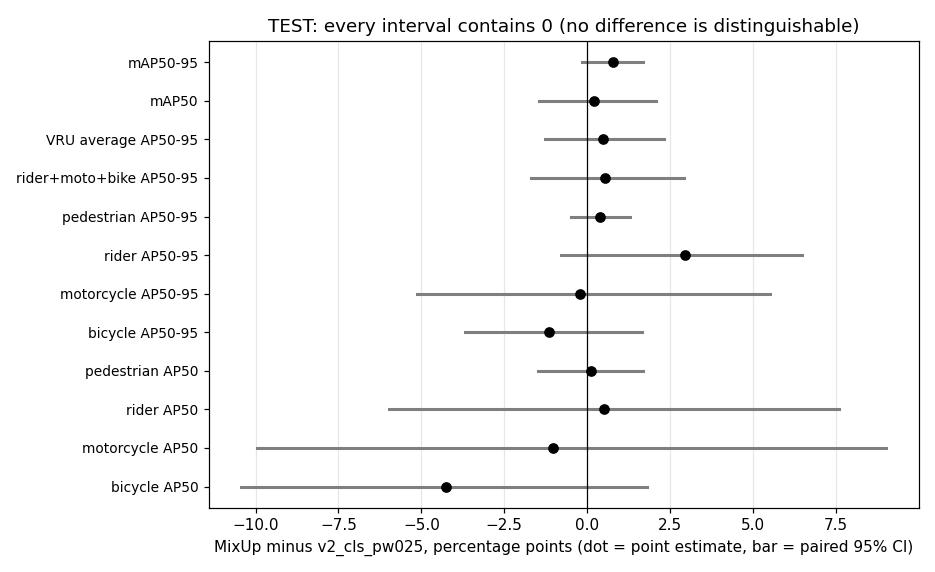

In [71]:
# Forest plot of the decision-relevant paired differences: MixUp minus v2_cls_pw025
ROWS = [("mAP50-95", "mAP50-95", 100), ("mAP50", "mAP50", 100), ("VRU4_AP50-95", "VRU average AP50-95", 100),
        ("RARE3_AP50-95", "rider+moto+bike AP50-95", 100),
        ("AP50-95[pedestrian]", "pedestrian AP50-95", 100), ("AP50-95[rider]", "rider AP50-95", 100),
        ("AP50-95[motorcycle]", "motorcycle AP50-95", 100), ("AP50-95[bicycle]", "bicycle AP50-95", 100),
        ("AP50[pedestrian]", "pedestrian AP50", 100), ("AP50[rider]", "rider AP50", 100),
        ("AP50[motorcycle]", "motorcycle AP50", 100), ("AP50[bicycle]", "bicycle AP50", 100)]
cmp_ = dd[dd.comparison == "v2_cls_pw025_mixup - v2_cls_pw025"].set_index("metric")
fig, ax = plt.subplots(figsize=(8.5, 5.2))
for i, (k, lab, sc) in enumerate(ROWS[::-1]):
    r = cmp_.loc[k]; lo, hi, pt = sc * r.ci95_low, sc * r.ci95_high, sc * r.point_diff
    colr = "tab:red" if (lo > 0 or hi < 0) else "tab:gray"
    ax.plot([lo, hi], [i, i], color=colr, lw=2); ax.plot(pt, i, "o", color="black", zorder=3)
ax.axvline(0, color="black", lw=0.8)
ax.set_yticks(range(len(ROWS))); ax.set_yticklabels([r[1] for r in ROWS[::-1]], fontsize=9)
ax.set_xlabel("MixUp minus v2_cls_pw025, percentage points (dot = point estimate, bar = paired 95% CI)")
ax.set_title("TEST: every interval contains 0 (no difference is distinguishable)")
ax.grid(alpha=0.3, axis="x"); plt.tight_layout()
plt.savefig("_tmp_master_nb_phase2_forest.png", dpi=110); plt.show()
n0 = sum(1 for k, _, sc in ROWS if cmp_.loc[k].ci95_low <= 0 <= cmp_.loc[k].ci95_high)
print(f"{len(ROWS)} paired differences plotted (MixUp minus v2_cls_pw025); {n0} of {len(ROWS)} intervals contain 0")


### 15.8 The three pre-established MixUp promotion criteria

Fixed before the test run and never modified (`evaluate_promotion_rule`, 15.3). **All three must hold** for MixUp
to replace `v2_cls_pw025`. The cell applies the embedded rule function to the paired differences and checks that
it reproduces the `decision_rule.json` that the original run wrote:

In [72]:
off = pd.read_csv(T / "official_global_metrics.csv").set_index("model")
rule = evaluate_promotion_rule(diff_rows, float(off.loc["v2_cls_pw025_mixup", "recall"]), float(off.loc["v2_cls_pw025", "recall"]),
                               "v2_cls_pw025_mixup", "v2_cls_pw025")
saved_rule = json.loads((T / "bootstrap/decision_rule.json").read_text())
same = all(rule[k]["pass"] == saved_rule[k]["pass"] for k in rule if k.startswith("criterion")) and rule["all_criteria_pass"] == saved_rule["all_criteria_pass"]
print("embedded rule reproduces the saved decision_rule.json verdicts:", same, "\n")

c1 = rule["criterion_1_VRU4_AP50-95_diff_CI_lower_gt_0"]
c2 = rule["criterion_2_no_VRU_class_AP50_drop_gt_0.03"]
c3 = rule["criterion_3_official_mean_recall_not_lower"]
yn = lambda b: "PASS" if b else "FAIL"
print(f"(1) VRU-average AP50-95 diff CI lower bound > 0 :  diff {100*c1['diff']:+.2f} pts, 95% CI [{100*c1['ci95'][0]:+.2f}, {100*c1['ci95'][1]:+.2f}]   -> {yn(c1['pass'])}")
print(f"(2) no VRU class loses > 3 pts of AP50          :  " + ", ".join(f"{k} {100*v:+.2f}" for k, v in c2["AP50_diffs"].items()) + f"   -> {yn(c2['pass'])}")
print(f"(3) official mean recall not lower              :  MixUp {100*c3['candidate']:.1f}% vs pw025 {100*c3['reference']:.1f}%   -> {yn(c3['pass'])}")
print("\nALL THREE CRITERIA PASS:", rule["all_criteria_pass"], "  ->  MixUp is NOT promoted.")


embedded rule reproduces the saved decision_rule.json verdicts: True 

(1) VRU-average AP50-95 diff CI lower bound > 0 :  diff +0.49 pts, 95% CI [-1.28, +2.32]   -> FAIL
(2) no VRU class loses > 3 pts of AP50          :  pedestrian +0.11, rider +0.52, motorcycle -1.02, bicycle -4.25   -> FAIL
(3) official mean recall not lower              :  MixUp 49.4% vs pw025 50.7%   -> FAIL

ALL THREE CRITERIA PASS: False   ->  MixUp is NOT promoted.

| criterion | result | verdict |
|---|---|---|
| 1. VRU-average AP50-95 difference has a 95 % CI lower bound above 0 | +0.49 pts, CI [-1.28, +2.32] | **FAIL** |
| 2. No VRU class loses more than 3 pts of AP50 | pedestrian +0.11, rider +0.52, motorcycle -1.02, **bicycle -4.25** | **FAIL** |
| 3. Official mean recall not lower than `v2_cls_pw025`'s | 49.4 % vs 50.7 % | **FAIL** |

**By the rule, MixUp is not promoted.** The rule was not modified after seeing the results. Criteria 2 and 3
fail on *point estimates* that are themselves not statistically distinguishable from zero (see 15.9) — the rule
is deliberately conservative — but criterion 1, the one that asks for positive evidence, fails on its own
terms: the interval includes zero.

### 15.9 Distinguishable or inconclusive?

**MixUp vs `v2_cls_pw025` is inconclusive on every headline metric.**
- Global: mAP50-95 +0.77 (95% CI -0.16 to +1.69) pts (p ≈ 0.10); mAP50 +0.22 (95% CI -1.46 to +2.07) pts.
  A small positive lead, but its interval contains zero. The validation dry run showed the same direction
  (+0.6 pts) with an equally wide interval, so the sign is consistent across two splits — **suggestive, not
  established**.
- VRU-average AP50-95: +0.49 (95% CI -1.28 to +2.32) pts. Rider AP50-95 +2.94 (95% CI -0.78 to +6.47),
  motorcycle -0.20 (95% CI -5.12 to +5.51), bicycle -1.16 (95% CI -3.69 to +1.65) — all consistent
  with no effect.
- The **bicycle AP50 drop** that fails criterion 2 is -4.25 (95% CI -10.43 to +1.82) pts, interval spanning zero:
  a point estimate the data cannot distinguish from zero in either direction.

**The only intervals that exclude zero between these two models are three pedestrian statistics at the fixed 0.25
threshold**: pedestrian recall -2.36 (95% CI -4.40 to -0.40) pts, the matching count of missed pedestrians
(false negatives) +27 (95% CI +3 to +52), and pedestrian false positives
-48 (95% CI -92 to -9). Recall and false negatives are the same quantity in two units, so
this is **one effect seen two ways** — at the same
confidence cutoff MixUp finds slightly fewer pedestrians and raises fewer false alarms — while pedestrian AP
itself is the same (53.7 vs 54.0 mAP50 overall; pedestrian AP50 differs by
+0.11 (95% CI -1.48 to +1.68) pts). It is a *shift along the same precision-recall curve*, not a better or worse
detector.

**All intervals that exclude zero, across all three comparisons** (unadjusted; 30 metrics × 3 comparisons = 90
intervals were computed, so a couple of such hits are expected by chance alone):

- `v2_cls_pw025 - v2_baseline` — `FN@ref[pedestrian]`
- `v2_cls_pw025 - v2_baseline` — `FP@ref[pedestrian]`
- `v2_cls_pw025 - v2_baseline` — `FP_total@ref`
- `v2_cls_pw025 - v2_baseline` — `recall@ref[pedestrian]`
- `v2_cls_pw025_mixup - v2_baseline` — `FP@ref[pedestrian]`
- `v2_cls_pw025_mixup - v2_baseline` — `FP_total@ref`
- `v2_cls_pw025_mixup - v2_baseline` — `mAP50-95`
- `v2_cls_pw025_mixup - v2_cls_pw025` — `FN@ref[pedestrian]`
- `v2_cls_pw025_mixup - v2_cls_pw025` — `FP@ref[pedestrian]`
- `v2_cls_pw025_mixup - v2_cls_pw025` — `recall@ref[pedestrian]`

**MixUp vs the baseline is distinguishable on one global metric**: mAP50-95 +1.60 (95% CI +0.47 to +2.66) pts. By
contrast `v2_cls_pw025` vs baseline is *not* distinguishable on it (+0.83 (95% CI -0.38 to +1.99)). So MixUp is
measurably better than the plain V2 baseline on mAP50-95, but that does not bear on the decision, which is
MixUp against the current best.

**A note on bus.** MixUp's largest per-class point difference on test is not a VRU class: bus AP50 is
+6.7 pts
(AP50-95 +4.6).
Bootstrap intervals were computed for the global metrics and the four VRU classes only, so whether the bus gain is
distinguishable from noise was **not tested**; the validation harness shows no such gain
(bus AP50 -0.1 pts, Section 13.7), which argues against reading it as a
robust MixUp effect. It is mentioned so the per-class table of 15.6 is not read selectively.

**What the intervals do and do not cover.** They quantify *test-set sampling noise* (which 830 images were
drawn), the dominant uncertainty for VRU classes with 39–116 instances. They do **not** capture *training*
variance — a second MixUp run with another seed could land a few tenths of a point either way, as the epoch-to-epoch
plateau noise of 13.6 suggests — and they are unadjusted for the number of metrics examined.

**A further limitation: the bootstrap assumes image-level independence.** Each replicate resamples
individual *images* as if they were independent draws. BDD100K images come from driving videos, and images
from the same video or sequence may be correlated (similar scenes, the same road users). This project can
verify the split only at the filename-prefix-group level (Sections 2.3 and 18.5), not at the video/sequence
level, so neither independence nor the absence of within-sequence correlation was independently verified. If
such correlation exists, image-level intervals are **too narrow** and the true uncertainty is larger. That
cannot turn an inconclusive result into a conclusive one, but it could weaken the few intervals that
excluded zero (the pedestrian operating-point statistics, and MixUp vs the baseline on mAP50-95). A
**group-level (cluster) bootstrap** — resampling whole filename-prefix groups, or real sequences where they
can be identified — is a consideration for future work.

**Two further cautions.**
- *Count statistics at conf 0.25 differ from earlier reports.* This evaluation takes `val()`'s own predictions
  and filters them at 0.25; the earlier audits ran inference directly at 0.25. The inference paths differ
  slightly, so absolute FP / FN / confusion counts here are not interchangeable with Section 12's — the three
  models are compared consistently *within* this evaluation, which is all the decision needs. The cell below
  shows the size of the discrepancy for `v2_cls_pw025`.
- *Official precision has no interval here.* MixUp's higher test precision (66.4 vs
  61.4) is a point estimate at each class's own max-F1 operating point and was not
  bootstrapped; at the **fixed** 0.25 threshold MixUp actually has *more* total false positives
  (+136 (95% CI -18 to +287)).

In [73]:
# Size of the count-statistic discrepancy for pw025 on test: earlier audit (predict at conf 0.25) vs this evaluation
old = Path(EVALD / "final_test_set/error_audit/v2_cls_pw025")
old_fp = pd.read_csv(old / "unmatched_predictions.csv").set_index("class")["unmatched_predictions"]
old_fn = pd.read_csv(old / "missed_objects.csv").set_index("class")["missed_objects"]
old_cf = pd.read_csv(old / "class_confusions.csv")
old_rp = int(old_cf[(old_cf.true_class == "rider") & (old_cf.predicted_class == "pedestrian")]["count"].sum())
pm2 = pm[pm.model == "v2_cls_pw025"].set_index("metric")["point"]
rows = [{"statistic": f"{k} FP / FN (no match)", "earlier audit (Section 12)": f"{old_fp.get(k, 0)} / {old_fn.get(k, 0)}",
         "this evaluation": f"{pm2[f'FP@ref[{k}]']:.0f} / {pm2[f'FN@ref[{k}]']:.0f}"} for k in VRU4]
rows.append({"statistic": "rider -> pedestrian", "earlier audit (Section 12)": old_rp, "this evaluation": f"{pm2['rider->pedestrian@ref']:.0f}"})
print(pd.DataFrame(rows).to_string(index=False))


                    statistic earlier audit (Section 12) this evaluation
pedestrian FP / FN (no match)                  371 / 515       384 / 522
     rider FP / FN (no match)                    15 / 34         22 / 33
motorcycle FP / FN (no match)                     5 / 19          8 / 18
   bicycle FP / FN (no match)                    12 / 62         23 / 64
          rider -> pedestrian                         11               9

### 15.10 Final model-selection decision

**Keep `v2_cls_pw025` as the preferred checkpoint. MixUp (`v2_cls_pw025_mixup`) is not promoted.**

Final official test metrics, for the record (percent):

| | Precision | Recall | mAP50 | mAP50-95 |
|---|---:|---:|---:|---:|
| `v2_baseline` | 63.2 | 48.1 | 51.9 | 27.6 |
| **`v2_cls_pw025`** (preferred) | 61.4 | **50.7** | 53.7 | 28.4 |
| `v2_cls_pw025_mixup` | **66.4** | 49.4 | **54.0** | **29.2** |

**Why, in one paragraph.** MixUp fails the pre-registered promotion rule on all three criteria; the evidence it
offers is a small, consistent-in-sign but statistically unestablished lead in global mAP50-95 and nothing for the
VRU classes the experiment was run for (Phase 1: no reduction of `true_miss`; Phase 2: every VRU interval
contains zero). `v2_cls_pw025` additionally keeps an advantage that is not in the table: its two frozen inference
profiles (Section 11) were calibrated for it and would have to be re-derived for any other checkpoint
(Section 10.2 showed that shift is real). MixUp remains a documented, reproducible
experiment — not discarded evidence — and its checkpoint is kept.

**The test split is now closed for model selection.** It has been scored three times; nothing was tuned on it,
but it should not be used to choose between further candidates. Any further candidate needs a held-out set
designed for the purpose.

## 16. Conclusion of the YOLO11n V2 Experiments

V2 is now complete: three controlled experiments, each differing from the last by one variable, evaluated on
validation throughout and confirmed once on held-out test data with a protocol fixed in advance.

### 16.1 What we attempted

| experiment | single change | val-split result (Section 13.7) | **test result** (percent) P / R / mAP50 / mAP50-95 |
|---|---|---|---|
| `v2_baseline` | the V2 recipe (imgsz 1152, batch 4, AdamW, full fine-tune) replacing V1's 640–960 px / batch 1–2 | broad win over every V1 variant (Section 6.7) | 63.2 / 48.1 / 51.9 / 27.6 |
| `v2_cls_pw025` | + class weighting `cls_pw=0.25` (after `cls_pw=0.5` proved too aggressive, Section 7.3) | best checkpoint of the Section 7 comparison (Section 7.4) | 61.4 / 50.7 / 53.7 / 28.4 |
| `v2_cls_pw025_mixup` | + MixUp `mixup=0.15` | comparable to `v2_cls_pw025`; no VRU benefit (Sections 13–14) | 66.4 / 49.4 / 54.0 / 29.2 |

Around them: threshold calibration and two frozen inference profiles for `v2_cls_pw025` (Sections 10 and 11), a
recall / error analysis of the failure modes (Section 9), validation diagnostics of the MixUp checkpoint
(Section 14) and a controlled, paired test comparison (Section 15).

### 16.2 What improved

- **V2's recipe over V1** — the largest single step: every one of the 9 classes improved over V1 on validation,
  recall by about +5.7 to +5.9 points, with no class-weighting lever applied yet (Section 6.7).
- **Class weighting at 0.25** gave the best checkpoint of the comparison in Section 7 (made before MixUp existed): the best
  mAP50, mAP50-95 and precision on validation, motorcycle and rider gains, the car-false-positive spike of `cls_pw=0.5` fully resolved
  (Sections 7.3–7.4). On the test split its direction held (recall, mAP50, mAP50-95, rider / motorcycle /
  bicycle AP50 all above baseline, Section 12.2). **A nuance the paired intervals of Section 15 add**: on test,
  `v2_cls_pw025` vs baseline is *not individually distinguishable* on mAP50-95 (+0.83 (95% CI -0.38 to +1.99) pts) —
  the improvement is directionally consistent across splits, but each test-split number alone carries more
  noise than Section 12 conveyed. The one distinguishable effect is again pedestrian at the 0.25 threshold
  (more pedestrians found, +3.75 (95% CI +1.51 to +6.00) pts, at the price of +125 (95% CI +80 to +172) false positives).
- **MixUp vs the plain baseline** is distinguishable on mAP50-95 (+1.60 (95% CI +0.47 to +2.66) pts) — a real but small
  improvement over V2's starting point, not over its best checkpoint.
- **Tooling and discipline**: a self-documenting notebook, hashed and fingerprinted evaluations, a reproducibility
  gate, a pre-registered promotion rule and a paired-bootstrap statistics module, all embedded here.

### 16.3 What did not improve

- **The VRU classes remain the weakest**, and neither class weighting nor MixUp moved them by an amount the data
  can distinguish from noise (Section 15.9). Test-set numbers for the preferred checkpoint, with their intervals:

In [74]:
pm = pd.read_csv(EVALD / "final_test_set_with_mixup/bootstrap/per_model_point_and_ci.csv")
rows = []
for cls in VRU4:
    g = lambda k: pm[(pm.model == "v2_cls_pw025") & (pm.metric == k)].iloc[0]
    a, r = g(f"AP50-95[{cls}]"), g(f"recall@ref[{cls}]")
    rows.append({"class": cls, "AP50-95 (%)": f"{100*a.point:.1f} [{100*a.ci95_low:.1f}, {100*a.ci95_high:.1f}]",
                 "recall @ conf 0.25 (%)": f"{100*r.point:.1f} [{100*r.ci95_low:.1f}, {100*r.ci95_high:.1f}]",
                 "FP @ 0.25": f"{g(f'FP@ref[{cls}]').point:.0f}", "FN @ 0.25": f"{g(f'FN@ref[{cls}]').point:.0f}"})
print("v2_cls_pw025, TEST split, point estimate [95% bootstrap CI]:")
print(pd.DataFrame(rows).set_index("class").to_string())
rp = pm[(pm.model == "v2_cls_pw025") & (pm.metric == "rider->pedestrian@ref")].iloc[0]
print(f"\nrider -> pedestrian at conf 0.25: {rp.point:.0f}  [{rp.ci95_low:.0f}, {rp.ci95_high:.0f}]  (this evaluation's pipeline; 11 in the earlier Section 12 audit)")


v2_cls_pw025, TEST split, point estimate [95% bootstrap CI]:
                  AP50-95 (%) recall @ conf 0.25 (%) FP @ 0.25 FN @ 0.25
class                                                                   
pedestrian  29.1 [26.7, 31.7]      56.7 [52.8, 60.4]       384       522
rider        14.4 [9.5, 21.0]      38.9 [26.2, 52.2]        22        33
motorcycle  19.8 [11.5, 28.5]      41.0 [24.1, 58.3]         8        18
bicycle     19.0 [14.1, 24.8]      37.9 [27.4, 49.1]        23        64

rider -> pedestrian at conf 0.25: 9  [4, 15]  (this evaluation's pipeline; 11 in the earlier Section 12 audit)

Read these as a *state of the art for this model on this data*, not as a target: rider and bicycle AP50-95 sit
around 14.4 % and 19.0 %, fewer than four in ten riders and bicycles are found at the working threshold (recall
38.9 % for riders), and the intervals are wide because the test split has only 72 riders and 39
motorcycles.
- **rider → pedestrian confusion is not solved** by any V2 experiment or by thresholding (Sections 10.4, 12.3, 14.3).
- **The car / truck / bus similarity cluster** (Section 18.3) was never a V2 target and is unchanged.
- **Precision** does not generalise as cleanly as recall (Section 12.2) and, at fixed thresholds, `v2_cls_pw025` and
  MixUp both pay for their recall gains with extra pedestrian false positives.

### 16.4 Why MixUp was not selected

It failed all three pre-registered promotion criteria (Section 15.8), and the reasons are substantive, not just
procedural: (i) the one criterion that demands positive evidence — a VRU-average AP50-95 gain with a confidence
interval above zero — fails because the measured gain (+0.49 (95% CI -1.28 to +2.32) pts) is indistinguishable from none;
(ii) Phase 1 showed MixUp **did not reduce the VRU `true_miss` rate**, the failure mode it was proposed to attack
(Section 14.3); (iii) its small global mAP50-95 lead (+0.77 (95% CI -0.16 to +1.69) pts) is consistent in sign across
validation and test but not established; (iv) it would orphan the frozen inference profiles, which are
calibrated to `v2_cls_pw025`.

### 16.5 Why class weighting (`v2_cls_pw025`) remains preferred

It was the best checkpoint of the Section 7 comparison, its profile-level deployment configuration
(Section 11) exists and was validated on both splits, its test direction replicates, and the only alternative
with a nominal global advantage — MixUp, whose best-epoch validation and test mAP50-95 are both nominally higher —
never clears the evidence bar (Section 15). The case for it is **"best-supported and
cheapest to keep"**, not "proven decisively better": on test, `v2_cls_pw025` vs baseline is also within noise
on mAP50-95 (16.2).

### 16.6 The preferred checkpoint and its test results

`v2_cls_pw025` (`runs/drivesight_v2/v2_cls_pw025/weights/best.pt`): epoch 91 of 121 trained, chosen for the highest
validation mAP50-95 (Section 6.6), `cls_pw=0.25`, fine-tuned from `yolo11n.pt` at imgsz 1152, batch 4, AdamW lr0 0.001.
Deployed through one of the two frozen inference profiles (Section 11), not a flat threshold.

| test split (n = 830) | value |
|---|---:|
| Recall | 50.7 % (best of baseline / `cls_pw` / `cls_pw025`) |
| mAP50 | 53.7 % (best) |
| mAP50-95 | 28.4 % (best) |
| Precision | 61.4 % (lowest of the three: the validation advantage that did not generalise) |
| rider AP50 | 39.6 % (+5.1 pts vs baseline) |
| motorcycle AP50 | 42.7 % (+4.4 pts vs baseline) |
| bicycle AP50 | 46.8 % (+3.9 pts vs baseline, the largest VRU margin on test) |

Known weaknesses: rider→pedestrian confusion is reduced but not solved (11 of about 45 test riders); rider and bicycle
AP50-95 stay low in absolute terms (14.4 % / 19.0 % on validation); car, pedestrian and traffic-sign/light AP50 are
essentially unchanged from baseline (Section 8); the rear-view-motorcyclist failure is unresolved (Section 6.9); and
precision generalises less cleanly than recall (Section 12.2). The test split is the project's only held-out split and
was scored three times (Section 12 twice, Section 15 once); nothing was selected from it.

### 16.7 The remaining VRU weaknesses and the evidence behind them

| evidence | source | implication |
|---|---|---|
| Rare-VRU misses are dominated by `true_miss` (50–67 %), unchanged by thresholds, class weighting or MixUp | 9.2, 10, 14.3 | a **representation / data** problem, not a calibration or loss-weighting one |
| Only 245 rider, 166 motorcycle, 399 bicycle training instances (194 / 125 / 220 images; 341 of 2,744 training images contain any rare VRU) | 3, 13.2 | the model has seen very few examples of each class's visual diversity |
| Atypical poses and viewpoints (wrecked motorcycle; rear-view motorcyclist) defeat every model variant | 6.9, 9.3 | **diversity**, not volume or resolution, is the binding constraint |
| VRU recall is already low in full daylight (≈ 33 %), dusk/dawn is not worse, night has almost no data | 14.4–14.5 | lighting augmentation is **not** supported as a first lever |
| Two training-side levers (loss weighting, MixUp) gave at most modest, mostly statistically unestablished VRU gains | 7, 16–18 | further *tuning of the same data* has low expected impact |
| The evaluation cannot resolve small VRU effects: ±1.8 pts half-width on the VRU-average AP50-95 with 39–116 instances per class | 15.7 | any further work needs a **larger, VRU-rich held-out set**, or no future VRU claim will be checkable |

### 16.8 Where each piece of implementation lives in this notebook

| component | where |
|---|---|
| Dataset preparation: BDD100K → YOLO conversion, label matching, group split, YAML | Sections 2.2–2.4, 4 |
| Model initialisation, architecture, transfer learning | 6.1–6.2 |
| Class weighting: the weight formula and the verbatim Ultralytics source | 7.2 |
| MixUp: the verbatim Ultralytics source and a live run of the real class | 13.3 |
| Training function, resume procedure, early stopping, fitness | 6.4, 6.6, 13.5 |
| Validation (official `val()` driver, hashes, fingerprints) | 13.7, 15.2 |
| Evaluation: project matcher, threshold-policy scoring, Ultralytics-faithful AP | 9.1, 10.1, 14.1, 15.3 |
| Bootstrap and the promotion rule | 15.3, 15.8 |
| Error analysis: cause-of-miss, FP / FN / confusion, time of day | 9, 14.2–14.5 |
| Visualisations and comparisons | 7.5, 8, 13.6, 14.3, 14.5, 15.7 |
| Frozen inference profiles | 11 |

### 16.9 Environment, external dependencies and checkpoints

- **Software**: Python 3.10, `ultralytics==8.4.189`, PyTorch 2.10 (CUDA 13), NumPy 2.2, pandas 2.3, matplotlib 3.10,
  PyYAML, Pillow, SciPy (printed live in 13.2). **`ultralytics==8.4.189` is the official PyPI release** — byte-identical to the published wheel
  (SHA-256 `eb14b93d1eb4894dc60e25d31bb865db2336d4705d386764ebd2f5cd42cec8a5`, verified in Section 7.2) — and `cls_pw` / `cls_remap`
  are stock features of that version, so **no patch or customized build is needed**: `pip install ultralytics==8.4.189`
  reproduces the class-weighted runs, including the MixUp run (`cls_pw=0.25`). Other Ultralytics versions were not tested
  and would need checking for these features first.
- **Hardware**: one NVIDIA GeForce RTX 2050 (4 GB), 15.3 GB host RAM, Windows 11 — the reason for `batch=4`,
  `workers=0`, and the repeated memory-pressure interruptions (13.5). The MixUp run's 116 epochs took about 8 hours of
  training time in total (≈ 4.1 minutes per epoch, summed over its four segments).
- **Data**: BDD100K — the 10k image package (`data/bdd100k/images/10k`, of which 4,260 images are used: 2,744 / 686 / 830) and
  the 100K label JSONs (`data/bdd100k/labels/100k`); the converted dataset in `data/bdd100k/yolo_dataset/`. BDD100K is
  subject to its own licence (commonly documented as non-commercial research/educational use — re-confirm before any other use).
- **Checkpoints and results** (existence and size verified live below).

The cell checks every path this notebook's conclusions depend on:

In [75]:
PATHS = {
    "preferred checkpoint  v2_cls_pw025 best.pt": "runs/drivesight_v2/v2_cls_pw025/weights/best.pt",
    "baseline checkpoint   v2_baseline best.pt": "runs/drivesight_v2/v2_baseline/weights/best.pt",
    "MixUp checkpoint      v2_cls_pw025_mixup best.pt": "runs/drivesight_v2/v2_cls_pw025_mixup/weights/best.pt",
    "MixUp epoch-114 backup (full state)": "runs/drivesight_v2/v2_cls_pw025_mixup_backup_ep114/last.pt",
    "pretrained starting weights": "weights/yolo11n.pt",
    "dataset config": "data/bdd100k/yolo_dataset/data.yaml",
    "test evaluation directory": "reports/drivesight_v2/evaluation/final_test_set_with_mixup",
    "Phase 1 diagnostics directory": "reports/drivesight_v2/evaluation/mixup_phase1",
}
for label, rel in PATHS.items():
    p = PROJECT_ROOT / rel
    size = f"{p.stat().st_size / 1e6:8.1f} MB" if p.is_file() else ("   (directory)" if p.is_dir() else "      MISSING")
    print(f"{label:48s} {size}   exists: {p.exists()}   {rel}")
print("\nNote: the v2_cls_pw025 and v2_cls_pw025_mixup best.pt files are optimizer-stripped (5.6 MB); v2_baseline's best.pt is a 26.7 MB")
print("checkpoint that was not stripped. A resume needs the full-state last.pt -- hence the epoch-114 backup (26.7 MB).")


preferred checkpoint  v2_cls_pw025 best.pt            5.6 MB   exists: True   runs/drivesight_v2/v2_cls_pw025/weights/best.pt
baseline checkpoint   v2_baseline best.pt            26.7 MB   exists: True   runs/drivesight_v2/v2_baseline/weights/best.pt
MixUp checkpoint      v2_cls_pw025_mixup best.pt      5.6 MB   exists: True   runs/drivesight_v2/v2_cls_pw025_mixup/weights/best.pt
MixUp epoch-114 backup (full state)                  26.7 MB   exists: True   runs/drivesight_v2/v2_cls_pw025_mixup_backup_ep114/last.pt
pretrained starting weights                           5.6 MB   exists: True   weights/yolo11n.pt
dataset config                                        0.0 MB   exists: True   data/bdd100k/yolo_dataset/data.yaml
test evaluation directory                           (directory)   exists: True   reports/drivesight_v2/evaluation/final_test_set_with_mixup
Phase 1 diagnostics directory                       (directory)   exists: True   reports/drivesight_v2/evaluation/mixup_phase1

N

### 16.10 Consolidated limitations of V2

1. **Single training seed per experiment.** Epoch-to-epoch noise (≈ 0.4–0.5 pts mAP50-95 on the plateau) is as large as
   the differences between the checkpoints; bootstrap intervals cover test-sampling noise only, not training variance.
2. **Best epochs and every threshold policy were chosen on the validation split**, so validation numbers are optimistic.
3. **The test split has been scored three times** (Section 12 twice, Section 15 once). Nothing was tuned on it, but it
   cannot support further model selection.
4. **Tiny VRU samples**: 39–116 test and 45–74 validation instances per rare VRU class.
5. **The results depend on one exact library version**: `ultralytics==8.4.189` (official PyPI release; `cls_pw` / `cls_remap`
   are stock features, Section 7.2). Other versions were not tested.
6. **Video-level leakage cannot be excluded**: the split is leakage-free at the filename-prefix-group level only
   (Sections 2.3 and 18.5).
7. **The frozen inference profiles are valid for `v2_cls_pw025` only** (Section 11).
8. **Interrupted training histories** (memory pressure) — proven lossless by contiguity and hash checks, but not
   clean uninterrupted traces.
9. **Count-style statistics are pipeline-dependent**: FP / FN / confusion counts at conf 0.25 differ by a few objects
   depending on how predictions were produced (15.9); the model comparison inside one pipeline is consistent.

10. **The paired bootstrap assumes image-level independence.** It resamples images, not videos or
    sequences; BDD100K images from the same sequence may be correlated, and video/sequence-level independence
    was not independently verified (only filename-prefix groups, Sections 2.3 and 18.5). If such correlation
    exists, the reported intervals are too narrow. A group-level bootstrap is a consideration for future work.

**Generator note.** The notebook was produced by a generator script that executed the code cells and cross-checked every
hand-written number of Sections 13–16 against the saved files at build time. That script and the other original scripts are kept
under `archive/scripts/`, for provenance only. The notebook has **no runtime dependency on any script**: every algorithm it uses is
defined in its own cells.

## 17. Three-Model Comparison on the V2 Data — YOLOv8s vs YOLO11s vs YOLO11n (`v2_cls_pw025`)

> **Scope.** V2 data only (2,744 train / 686 validation / 830 test images, the same files every earlier section used);
> no other dataset is involved. The two new models were **retrained by this project on the V2 training split** with the
> V2 recipe; the friends' repository publishes no weights. Every result is read from saved files in
> `reports/drivesight_v2/evaluation/three_model_comparison/` (cells print `not yet run` if a file is missing).
> **Validation is the only split used to compare and choose; the test split stays closed** (Section 15.10).

### 17.1 The three models

| | **YOLOv8s** | **YOLO11s** | **YOLO11n `v2_cls_pw025`** |
|---|---|---|---|
| origin | friends' repo (`train_yolov8s.ipynb`, `evaluate_yolo_models.ipynb`, `visualize_yolov8setyolo11s.ipynb`) | same repo (`train_yolo11s.ipynb`) | this project (Sections 6–16) |
| pretrained start | `yolov8s.pt` (COCO) | `yolo11s.pt` (COCO) | `yolo11n.pt` (COCO) |
| trained here on | V2 train split | V2 train split | V2 train split |
| training recipe | V2 recipe (below) | V2 recipe (below) | V2 recipe (this is the recipe) |
| status of the weights | **retrained in this section** | **retrained in this section** | **existing checkpoint, unchanged** |

*What the friends' repository did differently* (read from their notebooks, not assumed): they trained on a
2,500-image subset of BDD100K split 1,750 / 375 / 375, at `imgsz=640`, 30 epochs, batch 4, with Ultralytics
defaults (`cls_pw=0`, no `cls_remap`), on an RTX 3050. Their reported test numbers are on **their** split and are not
comparable with anything in this notebook. Only the architectures — YOLOv8s and YOLO11s — are carried over; the
data, the splits and the recipe are this project's. The class list and class order are identical to ours, so the
V2 `data.yaml` is used unchanged.

**Capacity is not equal, and that is part of the question.** The two "s" models are several times larger than the
nano model (parameter counts below). A result in favour of an "s" model therefore mixes *architecture* with *size*;
this notebook does not claim to separate them.

In [76]:
import json, pickle, time
import numpy as np
import pandas as pd
import torch
from pathlib import Path

CMP_DIR = PROJECT_ROOT / "reports/drivesight_v2/evaluation/three_model_comparison"
RUNS = PROJECT_ROOT / "runs/drivesight_v2"
CMP = {  # label -> (display name, run directory name)
    "v2_cls_pw025":          ("YOLO11n (existing)", "v2_cls_pw025"),
    "v2_yolov8s_cls_pw025":  ("YOLOv8s (retrained)", "v2_yolov8s_cls_pw025"),
    "v2_yolo11s_cls_pw025":  ("YOLO11s (retrained)", "v2_yolo11s_cls_pw025"),
}
THREE3 = list(CMP)
VRU4 = ["pedestrian", "rider", "motorcycle", "bicycle"]
CLASS_NAMES = ["pedestrian", "rider", "car", "truck", "bus", "motorcycle", "bicycle", "traffic light", "traffic sign"]

rows = []
for label, (disp, run) in CMP.items():
    ck = RUNS / run / "weights" / "best.pt"
    if not ck.exists():
        rows.append({"model": disp, "checkpoint": "not yet trained", "parameters": "-", "best epoch": "-"})
        continue
    c = torch.load(ck, map_location="cpu", weights_only=False)
    net = c.get("ema") or c.get("model")
    n_par = sum(p.numel() for p in net.parameters())
    res = RUNS / run / "results.csv"
    best_ep = "-"
    if res.exists():
        d = pd.read_csv(res); d.columns = [x.strip() for x in d.columns]
        best_ep = int(d.loc[d["metrics/mAP50-95(B)"].idxmax(), "epoch"])
    rows.append({"model": disp, "checkpoint": str(ck.relative_to(PROJECT_ROOT)), "parameters": f"{n_par / 1e6:.2f} M",
                 "best epoch": best_ep})
print(pd.DataFrame(rows).set_index("model").to_string())


                                                                  checkpoint parameters  best epoch
model                                                                                              
YOLO11n (existing)           runs\drivesight_v2\v2_cls_pw025\weights\best.pt     2.61 M          91
YOLOv8s (retrained)  runs\drivesight_v2\v2_yolov8s_cls_pw025\weights\best.pt    11.14 M          65
YOLO11s (retrained)  runs\drivesight_v2\v2_yolo11s_cls_pw025\weights\best.pt     9.43 M          55

### 17.2 Where the two new models come from, and why they were chosen

**Why these two.** The project's reference, YOLO11n, is the smallest model of its family. Two questions are open after
Section 16: *is a larger backbone enough to lift the VRU classes*, and *does the newer YOLO11 design beat the
established YOLOv8 design at the same "s" scale?* Your friends' repository trains exactly the two "s" models that
answer them (YOLOv8s and YOLO11s), so their architectures are reused and compared with the existing nano model on the
same V2 data. Both fit the 4 GB RTX 2050 at the V2 recipe (imgsz 1152, batch 4): measured peak memory 2.8 GB and 3.3 GB.

**What was taken from the friends' repository, and what was not.** The cell below prints their original training code
(`train_yolov8s.ipynb` and `train_yolo11s.ipynb`, printed verbatim in the cell below; the two differ only in
the weights file and the run name) and sets their configuration next to the V2 configuration used here. The architectures
and the "identical parameters for every model" principle are kept; their data subset, image size and epoch budget are not,
because those would make the comparison with the existing V2 model meaningless.

In [77]:
# The friends' training code, copied verbatim from their repository (reference only, never executed here).
FRIENDS_TRAIN_CELLS = r"""# Verbatim copy of the training cells of src/detection/train_yolov8s.ipynb
# from https://github.com/arijkhemiri2002/DriveSight (friends' repository). REFERENCE ONLY - not executed by this project.

MODEL_WEIGHTS = "yolov8s.pt"
RUN_NAME = "bdd_yolov8s"
print("Modèle :", MODEL_WEIGHTS)
print("Dossier de sortie :", RUNS_DIR / RUN_NAME)


# ---- next cell ----
# Entraînement
# Les paramètres sont identiques entre les modèles pour rendre la comparaison plus équitable.
RUNS_DIR.mkdir(parents=True, exist_ok=True)
model = YOLO(MODEL_WEIGHTS)
start_time = time.perf_counter()

train_results = model.train(
    data=str(DATA_YAML),
    epochs=30,
    imgsz=640,
    batch=4,
    seed=42,
    deterministic=True,
    workers=2,
    device=0,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
    save=True,
    val=True
)

elapsed_seconds = time.perf_counter() - start_time
best_weights = RUNS_DIR / RUN_NAME / "weights" / "best.pt"
last_weights = RUNS_DIR / RUN_NAME / "weights" / "last.pt"

print(f"Durée d'entraînement : {elapsed_seconds/60:.1f} minutes")
print("Meilleurs poids :", best_weights, "| existe :", best_weights.is_file())
print("Derniers poids :", last_weights, "| existe :", last_weights.is_file())

if not best_weights.is_file():
    raise FileNotFoundError("L'entraînement s'est terminé mais best.pt est absent.")

del model
if torch.cuda.is_available():
    torch.cuda.empty_cache()
"""
print("=" * 100); print("train_yolov8s.ipynb (training cells). train_yolo11s.ipynb is identical except for the two lines shown below."); print("=" * 100)
print(FRIENDS_TRAIN_CELLS)
print("\n" + "=" * 100); print("YOLO11s notebook differs from the YOLOv8s one only in:"); print("=" * 100)
print('  YOLOv8s: MODEL_WEIGHTS = "yolov8s.pt"  /  RUN_NAME = "bdd_yolov8s"')
print('  YOLO11s: MODEL_WEIGHTS = "yolo11s.pt"  /  RUN_NAME = "bdd_yolo11s"')

ref_cmp = pd.DataFrame({
    "friends' repository": {"training images": "1,750 (2,500-image subset, split 1,750/375/375)", "imgsz": 640, "epochs": 30,
                            "patience": "Ultralytics default (100)", "batch": 4, "seed": 42, "workers": 2,
                            "optimizer": "Ultralytics default (auto)", "class weighting": "none (cls_pw 0)",
                            "validation set": "their 375-image split"},
    "this project (V2 recipe)": {"training images": "2,744 (full V2 train split)", "imgsz": 1152, "epochs": "150 (early-stopped)",
                                 "patience": 30, "batch": 4, "seed": 0, "workers": 0, "optimizer": "AdamW, lr0 0.001",
                                 "class weighting": "cls_pw 0.25 + cls_remap", "validation set": "V2 validation split, 686 images"}})
print("\n"); print(ref_cmp.to_string())


train_yolov8s.ipynb (training cells). train_yolo11s.ipynb is identical except for the two lines shown below.
# Verbatim copy of the training cells of src/detection/train_yolov8s.ipynb
# from https://github.com/arijkhemiri2002/DriveSight (friends' repository). REFERENCE ONLY - not executed by this project.

MODEL_WEIGHTS = "yolov8s.pt"
RUN_NAME = "bdd_yolov8s"
print("Modèle :", MODEL_WEIGHTS)
print("Dossier de sortie :", RUNS_DIR / RUN_NAME)


# ---- next cell ----
# Entraînement
# Les paramètres sont identiques entre les modèles pour rendre la comparaison plus équitable.
RUNS_DIR.mkdir(parents=True, exist_ok=True)
model = YOLO(MODEL_WEIGHTS)
start_time = time.perf_counter()

train_results = model.train(
    data=str(DATA_YAML),
    epochs=30,
    imgsz=640,
    batch=4,
    seed=42,
    deterministic=True,
    workers=2,
    device=0,
    project=str(RUNS_DIR),
    name=RUN_NAME,
    exist_ok=True,
    plots=True,
    save=True,
    val=True
)

elapsed_seconds = time.perf_counter() - s

### 17.3 The three architectures

| | YOLO11n | **YOLOv8s** | **YOLO11s** |
|---|---|---|---|
| family | YOLO11 (2024) | YOLOv8 (2023) | YOLO11 (2024) |
| scale (depth / width) | 0.50 / 0.25 | 0.33 / 0.50 | 0.50 / 0.50 |
| feature block | C3k2 | C2f | C3k2 |
| context / attention | SPPF + C2PSA (spatial attention) | SPPF | SPPF + C2PSA (spatial attention) |
| head | decoupled, anchor-free | decoupled, anchor-free | decoupled, anchor-free |

All three predict boxes without anchors and share the same loss family (box, DFL, class), which is why the V2 `cls_pw`
class weighting applies to all of them unchanged. The cell below does not take these numbers from a table: it loads each saved
`best.pt` and reports the real layer count, parameter count, GFLOPs at 1152 px and the building blocks it contains.

In [78]:
from collections import Counter
from ultralytics import YOLO
arch_rows, blocks = [], {}
for label, (disp, run) in CMP.items():
    ck = RUNS / run / "weights" / "best.pt"
    if not ck.exists():
        print(disp, ": checkpoint not found"); continue
    m = YOLO(str(ck))
    from ultralytics.utils.torch_utils import get_flops
    layers = len(list(m.model.modules()))   # module instances (not the fused layer count)
    params = sum(x.numel() for x in m.model.parameters())
    gflops = get_flops(m.model, 1152)
    cnt = Counter(type(x).__name__ for x in m.model.modules())
    blocks[disp] = {k: cnt[k] for k in ("Conv", "C2f", "C3k2", "SPPF", "C2PSA", "Detect") if cnt[k]}
    arch_rows.append({"model": disp, "modules": layers, "parameters (M)": params / 1e6, "GFLOPs @1152": gflops,
                      "classes (nc)": m.model.yaml.get("nc"), "class names": len(m.names)})
    del m
print(pd.DataFrame(arch_rows).set_index("model").round(2).to_string())
print("\nbuilding blocks found in each network (module instances):")
print(pd.DataFrame(blocks).fillna(0).astype(int).to_string())


                     modules  parameters (M)  GFLOPs @1152  classes (nc)  class names
model                                                                                
YOLO11n (existing)       320            2.61         21.76             9            9
YOLOv8s (retrained)      225           11.14         92.86             9            9
YOLO11s (retrained)      319            9.43         71.15             9            9

building blocks found in each network (module instances):
        YOLO11n (existing)  YOLOv8s (retrained)  YOLO11s (retrained)
Conv                    75                   57                   75
C3k2                     8                    0                    8
SPPF                     1                    1                    1
C2PSA                    1                    0                    1
Detect                   1                    1                    1
C2f                      0                    8                    0

### 17.4 The training recipe and the fairness checks

The two new runs used the original `train_v2.py` (archived; its logic is the `train_v2_experiment` function of Section 6.4) unchanged, with only `--weights`, `--name`, `--cls_pw 0.25`
and `--workers 0` set. `workers=0` was checked against the original `args.yaml` files: **every V2 run
(`v2_baseline`, `v2_cls_pw`, `v2_cls_pw025`, `v2_cls_pw025_mixup`) was trained with `workers: 0`**, so this is the same value, not a
deviation (the function default of 2 in Section 6.1 is the part that differs from the history). The cell below
compares the saved `args.yaml` of each new run with the one of `v2_cls_pw025`, key by key, and lists every
difference; only the model, the run name and the bookkeeping `resume` entry are expected to differ.

In [79]:
import yaml
ref = yaml.safe_load((RUNS / "v2_cls_pw025" / "args.yaml").read_text(encoding="utf-8"))
IGNORE = {"save_dir", "name", "model", "resume"}
for label, (disp, run) in CMP.items():
    if label == "v2_cls_pw025":
        continue
    p = RUNS / run / "args.yaml"
    if not p.exists():
        print(f"{disp}: args.yaml not found (training not yet run)")
        continue
    a = yaml.safe_load(p.read_text(encoding="utf-8"))
    diff = {k: (ref.get(k), a.get(k)) for k in sorted(set(ref) | set(a)) if k not in IGNORE and ref.get(k) != a.get(k)}
    print(f"{disp}: {len(ref)} keys compared against v2_cls_pw025; differences outside {sorted(IGNORE)}: "
          f"{diff if diff else 'NONE'}")
    for k in ("imgsz", "batch", "epochs", "patience", "optimizer", "lr0", "cls_pw", "mixup", "seed", "workers", "deterministic"):
        print(f"    {k:14s} {a.get(k)!r}")


YOLOv8s (retrained): 114 keys compared against v2_cls_pw025; differences outside ['model', 'name', 'resume', 'save_dir']: NONE
    imgsz          1152
    batch          4
    epochs         150
    patience       30
    optimizer      'AdamW'
    lr0            0.001
    cls_pw         0.25
    mixup          0.0
    seed           0
    workers        0
    deterministic  True
YOLO11s (retrained): 114 keys compared against v2_cls_pw025; differences outside ['model', 'name', 'resume', 'save_dir']: NONE
    imgsz          1152
    batch          4
    epochs         150
    patience       30
    optimizer      'AdamW'
    lr0            0.001
    cls_pw         0.25
    mixup          0.0
    seed           0
    workers        0
    deterministic  True

### 17.5 Training code and the guard

The same entry point as Section 6.1 (`train_v2_experiment`), called with the two new starting weights. It is gated
behind its own hard guard, `RUN_THREE_MODEL_TRAINING = False`: executing this notebook never trains anything.
Each run takes roughly 9–14 hours on the 4 GB GPU (measured by the two-epoch smoke tests: about 5.2–5.7 minutes per
epoch, 2.8 GB / 3.3 GB peak memory), and is resumable with `resume_v2.py` exactly like the earlier runs. If a run
is interrupted, resume it; **do not restart it with a different recipe**.

In [80]:
RUN_THREE_MODEL_TRAINING = False   # HARD GUARD. With False (as shipped) nothing below trains.

NEW_RUNS = {   # name -> pretrained starting weights (downloaded once into weights/, never modified)
    "v2_yolov8s_cls_pw025": PROJECT_ROOT / "weights" / "yolov8s.pt",
    "v2_yolo11s_cls_pw025": PROJECT_ROOT / "weights" / "yolo11s.pt",
}
if RUN_THREE_MODEL_TRAINING:
    for name, w in NEW_RUNS.items():                     # one after the other, never simultaneously
        train_v2_experiment(name=name, cls_pw=0.25, weights=str(w), workers=0)
else:
    print("RUN_THREE_MODEL_TRAINING is False -- nothing was trained. The commands that produced the saved runs were:\n")
    for name, w in NEW_RUNS.items():
        print(f"python archive/scripts/drivesight_v2/train_v2.py --name {name} --weights {w.relative_to(PROJECT_ROOT)} "
              f"--cls_pw 0.25 --workers 0")


RUN_THREE_MODEL_TRAINING is False -- nothing was trained. The commands that produced the saved runs were:

python archive/scripts/drivesight_v2/train_v2.py --name v2_yolov8s_cls_pw025 --weights weights\yolov8s.pt --cls_pw 0.25 --workers 0
python archive/scripts/drivesight_v2/train_v2.py --name v2_yolo11s_cls_pw025 --weights weights\yolo11s.pt --cls_pw 0.25 --workers 0

### 17.6 What each model's training run produced

Read from the saved run files (`args.yaml`, `results.csv`, and `run_manifest.json` where the run wrote one), so the numbers
cannot drift from the files. *Epochs run* is smaller than 150 because patience 30 stopped each run once the validation
fitness had not improved for 30 epochs. The YOLOv8s run was interrupted once by the operating system at epoch 44
(memory pressure, not a training error) and resumed from `last.pt` with the recipe unchanged.

In [81]:
rows, last = [], {}
for label, (disp, run) in CMP.items():
    rd = RUNS / run
    if not (rd / "results.csv").exists():
        rows.append({"model": disp, "status": "no results.csv"}); continue
    d = pd.read_csv(rd / "results.csv"); d.columns = [c.strip() for c in d.columns]
    k = "metrics/mAP50-95(B)"; i = d[k].idxmax()
    man = json.loads((rd / "run_manifest.json").read_text()) if (rd / "run_manifest.json").exists() else {}
    a = yaml.safe_load((rd / "args.yaml").read_text(encoding="utf-8"))
    rows.append({"model": disp, "pretrained start": {"v2_cls_pw025": "yolo11n.pt", "v2_yolov8s_cls_pw025": "yolov8s.pt", "v2_yolo11s_cls_pw025": "yolo11s.pt"}[label], "epochs run": len(d), "best epoch": int(d.epoch[i]),
                 "mAP50-95 @best": d.loc[i, k], "mAP50 @best": d.loc[i, "metrics/mAP50(B)"],
                 "precision @best": d.loc[i, "metrics/precision(B)"], "recall @best": d.loc[i, "metrics/recall(B)"],
                 "final train box loss": d["train/box_loss"].iloc[-1], "final train cls loss": d["train/cls_loss"].iloc[-1],
                 "peak GPU MB (manifest)": round(man["peak_gpu_mem_mb"]) if "peak_gpu_mem_mb" in man else "n/a"})
    last[disp] = d[["epoch", k, "metrics/recall(B)", "train/box_loss", "train/cls_loss", "val/box_loss", "val/cls_loss"]].tail(4)
print(pd.DataFrame(rows).set_index("model").astype(str).T.to_string())
for disp, t in last.items():
    print(f"\n{disp} -- last four recorded epochs:"); print(t.round(4).to_string(index=False))


model                  YOLO11n (existing) YOLOv8s (retrained) YOLO11s (retrained)
pretrained start               yolo11n.pt          yolov8s.pt          yolo11s.pt
epochs run                            121                  95                  85
best epoch                             91                  65                  55
mAP50-95 @best                    0.29295             0.31497             0.31454
mAP50 @best                       0.54585             0.57479             0.57573
precision @best                   0.70379             0.71787             0.66758
recall @best                      0.48322             0.51746             0.52904
final train box loss              1.25359             1.13675             1.19791
final train cls loss              0.43435             0.35925             0.39564
peak GPU MB (manifest)                n/a                 n/a                3538

YOLO11n (existing) -- last four recorded epochs:
 epoch  metrics/mAP50-95(B)  metrics/recall(B)  

### 17.7 Training dynamics

Read from each run's own `results.csv`. These curves are training-time validation on the V2 validation split, with
Ultralytics' own best-epoch rule (`best.pt` = highest fitness); they are context, not the comparison, which uses the
single controlled evaluation of Section 17.8.

In [82]:
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
COLS3 = {"v2_cls_pw025": "tab:green", "v2_yolov8s_cls_pw025": "tab:purple", "v2_yolo11s_cls_pw025": "tab:orange"}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
have = False
for label, (disp, run) in CMP.items():
    p = RUNS / run / "results.csv"
    if not p.exists():
        continue
    have = True
    d = pd.read_csv(p); d.columns = [c.strip() for c in d.columns]
    for ax, col, ttl in zip(axes, ["metrics/mAP50-95(B)", "metrics/recall(B)", "val/cls_loss"],
                            ["val mAP50-95", "val recall", "val cls loss"]):
        ax.plot(d["epoch"], d[col], label=disp, color=COLS3[label]); ax.set_title(ttl); ax.set_xlabel("epoch")
    b = d.loc[d["metrics/mAP50-95(B)"].idxmax()]
    print(f"{disp:22s} epochs run {len(d):3d} | best epoch {int(b['epoch']):3d} (mAP50-95 {b['metrics/mAP50-95(B)']:.4f}, "
          f"recall {b['metrics/recall(B)']:.4f}) | {d['time'].iloc[-1] / 3600:.1f} h of recorded training time (per segment if resumed)")
if have:
    axes[0].legend(); fig.tight_layout(); fig.savefig("_tmp_master_nb_threemodel_curves.png", dpi=110)
    from IPython.display import Image, display
    display(Image("_tmp_master_nb_threemodel_curves.png"))
else:
    print("not yet run: no results.csv for any model")
plt.close(fig)


YOLO11n (existing)     epochs run 121 | best epoch  91 (mAP50-95 0.2929, recall 0.4832) | 2.9 h of recorded training time (per segment if resumed)
YOLOv8s (retrained)    epochs run  95 | best epoch  65 (mAP50-95 0.3150, recall 0.5175) | 4.6 h of recorded training time (per segment if resumed)
YOLO11s (retrained)    epochs run  85 | best epoch  55 (mAP50-95 0.3145, recall 0.5290) | 8.1 h of recorded training time (per segment if resumed)
<IPython.core.display.Image object>

### 17.8 One controlled evaluation on the V2 validation split

All three checkpoints go through the **same** function as Section 15 (`run_final_eval`): identical `imgsz=1152`,
NMS IoU 0.70, `conf >= 0.001`, official Ultralytics `val()`, SHA-256 of every checkpoint and a fingerprint of the
split taken before and after, and the predictions `val()` itself produced cached for everything downstream (paired
bootstrap, confusion matrices, miss counts). The output directory must not exist, so earlier results cannot be
overwritten. `split='val'`: the test split is not touched. Evaluating the existing `v2_cls_pw025` again is read-only
and puts it on exactly the same code path as the newcomers; its historical numbers in Sections 8 and 15 are not
altered.

In [83]:
RUN_THREE_MODEL_VAL_EVAL = False   # HARD GUARD (GPU, a few minutes per model). Validation split only.
VAL_DIR = CMP_DIR / "val"
if RUN_THREE_MODEL_VAL_EVAL:
    run_final_eval({label: RUNS / run / "weights" / "best.pt" for label, (_, run) in CMP.items()},
                   PROJECT_ROOT / "data/bdd100k/yolo_dataset/data.yaml", "val", VAL_DIR)
    print("evaluation finished")
elif VAL_DIR.exists():
    before = json.loads((VAL_DIR / "checkpoint_hashes_before.json").read_text())
    after = json.loads((VAL_DIR / "checkpoint_hashes_after.json").read_text())
    print("saved evaluation found:", VAL_DIR.relative_to(PROJECT_ROOT))
    print("checkpoint hashes identical before/after evaluation:", before == after)
    print("split fingerprint identical before/after:",
          json.loads((VAL_DIR / "split_fingerprint_before.json").read_text()) == json.loads((VAL_DIR / "split_fingerprint_after.json").read_text()))
    print("hash of the existing YOLO11n checkpoint used here:", before.get("v2_cls_pw025", "?")[:16] + "...")
else:
    print("not yet run: no saved validation evaluation in", VAL_DIR.relative_to(PROJECT_ROOT))


saved evaluation found: reports\drivesight_v2\evaluation\three_model_comparison\val
checkpoint hashes identical before/after evaluation: True
split fingerprint identical before/after: True
hash of the existing YOLO11n checkpoint used here: 49df5d8da855996c...

### 17.9 Global and per-class results (validation)

Official Ultralytics numbers from the controlled evaluation. `VRU-4` is the mean over pedestrian, rider,
motorcycle and bicycle. The validation split holds only 59 riders, 45 motorcycles and 74 bicycles, so per-class
differences for the rare classes are noisy (Section 15); the paired intervals of 20.7 say how noisy.

In [84]:
if not (VAL_DIR / "official_global_metrics.csv").exists():
    print("not yet run: official_global_metrics.csv missing")
else:
    g = pd.read_csv(VAL_DIR / "official_global_metrics.csv").set_index("model")
    pc = pd.read_csv(VAL_DIR / "official_per_class_metrics.csv")
    out = pd.DataFrame({CMP[m][0]: {"precision": g.loc[m, "precision"], "recall": g.loc[m, "recall"],
                                    "mAP50": g.loc[m, "map50"], "mAP50-95": g.loc[m, "map50_95"],
                                    "VRU-4 AP50-95": pc[(pc.model == m) & pc["class"].isin(VRU4)]["ap50_95"].mean(),
                                    "VRU-4 AP50": pc[(pc.model == m) & pc["class"].isin(VRU4)]["ap50"].mean(),
                                    "VRU-4 recall": pc[(pc.model == m) & pc["class"].isin(VRU4)]["recall"].mean()}
                        for m in THREE3 if m in g.index})
    print("GLOBAL (V2 validation, 686 images; recall columns are Ultralytics' P/R at its max-F1 confidence):")
    print((100 * out).round(2).to_string())
    for metric, ttl in (("ap50_95", "AP50-95"), ("ap50", "AP50"), ("recall", "recall")):
        t = pc.pivot(index="class", columns="model", values=metric).reindex(CLASS_NAMES)
        t = t[[m for m in THREE3 if m in t.columns]].rename(columns={m: CMP[m][0] for m in THREE3})
        t.index = [("* " if c in VRU4 else "  ") + c for c in t.index]
        print(f"\nPER-CLASS {ttl} (%; * = VRU-4 class):")
        print((100 * t).round(1).to_string())


GLOBAL (V2 validation, 686 images; recall columns are Ultralytics' P/R at its max-F1 confidence):
               YOLO11n (existing)  YOLOv8s (retrained)  YOLO11s (retrained)
precision                   70.54                71.76                66.54
recall                      48.39                51.87                52.99
mAP50                       54.74                57.58                57.48
mAP50-95                    29.43                31.51                31.54
VRU-4 AP50-95               20.50                23.88                21.55
VRU-4 AP50                  46.12                49.81                47.26
VRU-4 recall                38.77                43.81                46.15

PER-CLASS AP50-95 (%; * = VRU-4 class):
model            YOLO11n (existing)  YOLOv8s (retrained)  YOLO11s (retrained)
* pedestrian                   30.8                 32.7                 32.8
* rider                        18.2                 23.4                 19.4
  car              

### 17.10 Paired bootstrap on the validation split

The same machinery as Section 15.3 (`ModelData`, `paired_bootstrap`, `paired_difference_table`): images are resampled
with replacement, **the same resample for every model**, so a difference between two models is paired. The two
comparisons that matter are each "s" model against the existing YOLO11n (the reference), plus YOLO11s against
YOLOv8s. An interval that contains 0 means *not distinguishable from sampling noise on this validation set*. The
full 2,000-replicate run takes minutes of CPU, so by default the saved table is read; the same cell recomputes it
when `RUN_VAL_BOOTSTRAP = True`. No selection rule is applied here beyond reporting the intervals — the decision
in 17.14 only states what the intervals support.

In [85]:
RUN_VAL_BOOTSTRAP = False   # CPU, several minutes for 2,000 replicates
PAIRS3 = [("v2_yolov8s_cls_pw025", "v2_cls_pw025"), ("v2_yolo11s_cls_pw025", "v2_cls_pw025"),
          ("v2_yolo11s_cls_pw025", "v2_yolov8s_cls_pw025")]
BOOT_DIR = VAL_DIR / "bootstrap"
KEY3 = ["mAP50", "mAP50-95", "VRU4_AP50-95", "VRU4_AP50", "RARE3_AP50-95",
        "AP50-95[pedestrian]", "AP50-95[rider]", "AP50-95[motorcycle]", "AP50-95[bicycle]",
        "VRU4_macro_recall@ref", "micro_recall@ref",
        "recall@ref[rider]", "recall@ref[motorcycle]", "recall@ref[bicycle]", "rider->pedestrian@ref"]
diff3 = None
if not VAL_DIR.exists():
    print("not yet run: no validation evaluation to bootstrap")
elif RUN_VAL_BOOTSTRAP:
    data3 = {m: ModelData(VAL_DIR / f"predictions_{m}.pkl") for m in THREE3}
    point3, boot3 = paired_bootstrap(data3, n_boot=2000, seed=12345)
    diff3 = pd.DataFrame(paired_difference_table(point3, boot3, PAIRS3))
    BOOT_DIR.mkdir(exist_ok=True)
    diff3.to_csv(BOOT_DIR / "paired_differences.csv", index=False)
    print("re-ran the full bootstrap and saved", (BOOT_DIR / "paired_differences.csv").relative_to(PROJECT_ROOT))
elif (BOOT_DIR / "paired_differences.csv").exists():
    diff3 = pd.read_csv(BOOT_DIR / "paired_differences.csv")
    print("using the SAVED paired differences:", (BOOT_DIR / "paired_differences.csv").relative_to(PROJECT_ROOT))
else:
    print("not yet run: no saved bootstrap (set RUN_VAL_BOOTSTRAP = True to compute it)")
if diff3 is not None:
    for comp, sub in diff3[diff3.metric.isin(KEY3)].groupby("comparison", sort=False):
        t = sub.set_index("metric").reindex(KEY3)
        scale = np.where(t.index.str.contains("FP|FN|->"), 1, 100)
        tab = pd.DataFrame({"diff": t.point_diff * scale, "ci95_low": t.ci95_low * scale, "ci95_high": t.ci95_high * scale,
                            "p": t.approx_two_sided_p})
        tab["excludes 0"] = (tab.ci95_low > 0) | (tab.ci95_high < 0)
        print(f"\n{comp}   (percentage points; positive = first model better):")
        print(tab.round(2).to_string())


using the SAVED paired differences: reports\drivesight_v2\evaluation\three_model_comparison\val\bootstrap\paired_differences.csv

v2_yolov8s_cls_pw025 - v2_cls_pw025   (percentage points; positive = first model better):
                         diff  ci95_low  ci95_high     p  excludes 0
metric                                                              
mAP50                    2.83      0.47       5.22  0.02        True
mAP50-95                 2.05      0.71       3.48  0.00        True
VRU4_AP50-95             3.39      0.80       6.28  0.02        True
VRU4_AP50                3.68     -1.21       8.77  0.14       False
RARE3_AP50-95            3.87      0.38       7.72  0.03        True
AP50-95[pedestrian]      1.93      0.69       3.27  0.00        True
AP50-95[rider]           5.17     -0.32      11.43  0.07       False
AP50-95[motorcycle]      2.28     -3.04       8.45  0.46       False
AP50-95[bicycle]         4.17     -0.95       9.97  0.13       False
VRU4_macro_recall@ref

### 17.11 Confusion matrices and VRU error counts at the reference confidence

Computed from the cached `val()` predictions at conf 0.25 (the project's reference confidence), with a
class-agnostic greedy IoU >= 0.5 match so that *confusions* (right place, wrong class) are visible as off-diagonal
cells; the last row/column are false positives (no ground truth) and misses (no detection). Rows are ground truth.

In [86]:
def _iou_xyxy(a, b):
    a, b = np.asarray(a, float).reshape(-1, 4), np.asarray(b, float).reshape(-1, 4)
    lt, rb = np.maximum(a[:, None, :2], b[None, :, :2]), np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.prod(np.clip(rb - lt, 0, None), axis=2)
    ua = np.prod(a[:, 2:] - a[:, :2], axis=1)[:, None] + np.prod(b[:, 2:] - b[:, :2], axis=1)[None, :]
    return inter / np.maximum(ua - inter, 1e-12)

def confusion_matrix_from_pkl(pkl, conf=0.25, iou_thr=0.5):
    d = pickle.load(open(pkl, "rb"))
    K = len(CLASS_NAMES)
    cm = np.zeros((K + 1, K + 1), int)           # [gt, pred]; index K = background (FP row / miss column)
    for s in d["stems"]:
        pcls, pconf, pbox = d["preds"][s]
        gcls, gbox = d["gt"][s]
        keep = pconf >= conf
        pcls, pconf, pbox = pcls[keep], pconf[keep], pbox[keep]
        o = np.argsort(-pconf, kind="stable"); pcls, pbox = pcls[o], pbox[o]
        used = np.zeros(len(gcls), bool)
        M = _iou_xyxy(pbox, gbox) if len(pcls) and len(gcls) else np.zeros((len(pcls), len(gcls)))
        for i in range(len(pcls)):
            cand = np.where((M[i] >= iou_thr) & ~used)[0] if len(gcls) else []
            if len(cand):
                j = cand[np.argmax(M[i][cand])]; used[j] = True
                cm[int(gcls[j]), int(pcls[i])] += 1
            else:
                cm[K, int(pcls[i])] += 1
        for j in np.where(~used)[0]:
            cm[int(gcls[j]), K] += 1
    return cm

CMS = {}
if VAL_DIR.exists():
    for m in THREE3:
        pk = VAL_DIR / f"predictions_{m}.pkl"
        if pk.exists():
            CMS[m] = confusion_matrix_from_pkl(pk)
if not CMS:
    print("not yet run: no cached validation predictions")
else:
    short = ["ped", "rider", "car", "truck", "bus", "moto", "bike", "tlight", "tsign", "bg"]
    fig, axes = plt.subplots(1, len(CMS), figsize=(6.2 * len(CMS), 5.6))
    axes = np.atleast_1d(axes)
    for ax, (m, cm) in zip(axes, CMS.items()):
        nrm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
        ax.imshow(nrm, cmap="Blues", vmin=0, vmax=1)
        ax.set_xticks(range(10)); ax.set_xticklabels(short, rotation=45, ha="right", fontsize=8)
        ax.set_yticks(range(10)); ax.set_yticklabels(short, fontsize=8)
        for i in range(10):
            for j in range(10):
                if cm[i, j]:
                    ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=6.5, color="white" if nrm[i, j] > .5 else "black")
        ax.set_title(f"{CMP[m][0]}\nrow-normalised colour, raw counts", fontsize=9); ax.set_xlabel("predicted"); ax.set_ylabel("ground truth")
    fig.tight_layout(); fig.savefig("_tmp_master_nb_threemodel_cm.png", dpi=105); plt.close(fig)
    from IPython.display import Image, display
    display(Image("_tmp_master_nb_threemodel_cm.png"))
    K = len(CLASS_NAMES)
    rows = []
    for m, cm in CMS.items():
        for c in VRU4:
            i = CLASS_NAMES.index(c)
            rows.append({"model": CMP[m][0], "class": c, "GT": int(cm[i, :K].sum() + cm[i, K]),
                         "correct": int(cm[i, i]), "missed": int(cm[i, K]),
                         "confused as other class": int(cm[i, :K].sum() - cm[i, i]),
                         "false positives (pred as this class, no GT)": int(cm[K, i])})
    print(pd.DataFrame(rows).to_string(index=False))


<IPython.core.display.Image object>
              model      class   GT  correct  missed  confused as other class  false positives (pred as this class, no GT)
 YOLO11n (existing) pedestrian 1083      647     425                       11                                          384
 YOLO11n (existing)      rider   59       20      23                       16                                            6
 YOLO11n (existing) motorcycle   45       13      21                       11                                            8
 YOLO11n (existing)    bicycle   74       23      49                        2                                           16
YOLOv8s (retrained) pedestrian 1083      662     402                       19                                          345
YOLOv8s (retrained)      rider   59       25      22                       12                                           13
YOLOv8s (retrained) motorcycle   45       13      25                        7                          

### 17.12 The same validation images, side by side

Images that contain a rider, motorcycle or bicycle and on which the three models differ most in how many of
those objects they find (a deterministic pick, ties broken by file name — *not* cherry-picked for a model).
Green = ground truth, coloured boxes = predictions with conf >= 0.25, drawn from the cached predictions. These are
illustrations; the numbers above are the evidence.

In [87]:
from PIL import Image as PILImage, ImageDraw
if len(CMS) < 3:
    print("not yet run: needs the cached validation predictions of all three models")
else:
    P = {m: pickle.load(open(VAL_DIR / f"predictions_{m}.pkl", "rb")) for m in THREE3}
    stems = P[THREE3[0]]["stems"]
    VRU_IDS = {CLASS_NAMES.index(c) for c in ("rider", "motorcycle", "bicycle")}
    def found(m, s):
        pcls, pconf, pbox = P[m]["preds"][s]; gcls, gbox = P[m]["gt"][s]
        k = pconf >= 0.25; hit = 0
        for j in range(len(gcls)):
            if int(gcls[j]) in VRU_IDS and k.any():
                ious = _iou_xyxy(pbox[k], gbox[j:j + 1])[:, 0]
                hit += int(((ious >= 0.5) & (pcls[k] == gcls[j])).any())
        return hit
    cand = []
    for s in stems:
        g = P[THREE3[0]]["gt"][s][0]
        if not any(int(c) in VRU_IDS for c in g):
            continue
        f = [found(m, s) for m in THREE3]
        cand.append((max(f) - min(f), s, f))
    cand.sort(key=lambda t: (-t[0], t[1]))
    pick = cand[:4]
    colors = {"v2_cls_pw025": (0, 170, 0), "v2_yolov8s_cls_pw025": (150, 60, 200), "v2_yolo11s_cls_pw025": (230, 120, 0)}
    fig, axes = plt.subplots(len(pick), 3, figsize=(16, 3.2 * len(pick)))
    axes = np.atleast_2d(axes)
    for r, (_, s, f) in enumerate(pick):
        path = next(p for p in (PROJECT_ROOT / "data/bdd100k/yolo_dataset/images/val").glob(s + ".*"))
        for cidx, m in enumerate(THREE3):
            im = PILImage.open(path).convert("RGB"); W, H = im.size; dr = ImageDraw.Draw(im)
            gcls, gbox = P[m]["gt"][s]
            for b in gbox:
                dr.rectangle([b[0] * W, b[1] * H, b[2] * W, b[3] * H], outline=(0, 255, 0), width=2)
            pcls, pconf, pbox = P[m]["preds"][s]
            for c_, cf, b in zip(pcls, pconf, pbox):
                if cf >= 0.25:
                    dr.rectangle([b[0] * W, b[1] * H, b[2] * W, b[3] * H], outline=colors[m], width=3)
                    dr.text((b[0] * W + 2, b[1] * H + 2), f"{CLASS_NAMES[int(c_)]} {cf:.2f}", fill=colors[m])
            axes[r, cidx].imshow(im); axes[r, cidx].axis("off")
            axes[r, cidx].set_title(f"{CMP[m][0]} | VRU found {f[cidx]} | {s}", fontsize=8)
    fig.tight_layout(); fig.savefig("_tmp_master_nb_threemodel_grid.png", dpi=80); plt.close(fig)
    from IPython.display import Image, display
    display(Image("_tmp_master_nb_threemodel_grid.png"))


<IPython.core.display.Image object>

### 17.13 Precision–recall curves, model size and inference speed

The PR curves are the ones Ultralytics wrote during the controlled `val()` run (`ultralytics_val/<model>/BoxPR_curve.png`,
all nine classes, mAP50 in the legend). Speed comes from the benchmark cell just below (`run_speed_benchmark`, behind `RUN_SPEED_BENCHMARK`): batch 1, 1152 px,
FP32, 200 timed validation images after 20 warm-up images, the three models measured one after another on the
RTX 2050 (4 GB); saved in `speed_benchmark.json`. Timings on a laptop GPU carry a few percent of thermal noise.

In [88]:
RUN_SPEED_BENCHMARK = False   # HARD GUARD (GPU, about 2 minutes). Validation images only; refuses to overwrite a saved result.
SPEED_JSON = VAL_DIR / "speed_benchmark.json"

def run_speed_benchmark(n_timed=200, warmup=20):
    """Per-image inference time of the three checkpoints: batch 1, imgsz 1152, conf 0.25, NMS iou 0.70, FP32, GPU 0,
    `warmup` untimed images then `n_timed` timed ones (first validation images in sorted order). Times are the
    preprocess / inference / postprocess milliseconds Ultralytics reports for each image, averaged."""
    import platform, statistics
    import ultralytics
    assert not SPEED_JSON.exists(), f"Refusing to overwrite {SPEED_JSON}"
    imgs = sorted((PROJECT_ROOT / "data/bdd100k/yolo_dataset/images/val").glob("*.jpg"))[: n_timed + warmup]
    out = {"protocol": dict(batch=1, imgsz=1152, conf=0.25, iou=0.70, half=False, device="0", warmup=warmup,
                            n_timed=len(imgs) - warmup, split="val"),
           "env": dict(gpu=torch.cuda.get_device_name(0), torch=torch.__version__, ultralytics=ultralytics.__version__,
                       platform=platform.platform()), "models": {}}
    for label, (disp, run) in CMP.items():
        ck = RUNS / run / "weights" / "best.pt"
        m = YOLO(str(ck)); t = {"pre": [], "inf": [], "post": []}
        for i, im in enumerate(imgs):
            r = m.predict(str(im), imgsz=1152, conf=0.25, iou=0.70, half=False, device="0", verbose=False)[0]
            if i >= warmup:
                for k, kk in (("pre", "preprocess"), ("inf", "inference"), ("post", "postprocess")):
                    t[k].append(r.speed[kk])
        mean = {k: statistics.fmean(v) for k, v in t.items()}
        out["models"][label] = dict(checkpoint=str(ck.relative_to(PROJECT_ROOT)), size_mb=ck.stat().st_size / 1e6,
                                    params_m=sum(x.numel() for x in m.model.parameters()) / 1e6,
                                    preprocess_ms=mean["pre"], inference_ms=mean["inf"], postprocess_ms=mean["post"],
                                    total_ms=sum(mean.values()), fps_total=1000 / sum(mean.values()),
                                    inference_ms_median=statistics.median(t["inf"]))
        del m; torch.cuda.empty_cache()
    SPEED_JSON.write_text(json.dumps(out, indent=2))
    print("saved", SPEED_JSON)

if RUN_SPEED_BENCHMARK:
    run_speed_benchmark()
else:
    print("RUN_SPEED_BENCHMARK is False -- nothing was timed. Saved result:", SPEED_JSON.relative_to(PROJECT_ROOT), "| exists:", SPEED_JSON.exists())


RUN_SPEED_BENCHMARK is False -- nothing was timed. Saved result: reports\drivesight_v2\evaluation\three_model_comparison\val\speed_benchmark.json | exists: True

In [89]:
import matplotlib.image as mpimg
if not (VAL_DIR / "official_global_metrics.csv").exists():
    print("not yet run: no validation evaluation")
else:
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.6))
    for ax, m in zip(axes, THREE3):
        ax.imshow(mpimg.imread(VAL_DIR / "ultralytics_val" / m / "BoxPR_curve.png"))
        ax.set_title(CMP[m][0]); ax.axis("off")
    plt.tight_layout(); plt.show()
    sp = VAL_DIR / "speed_benchmark.json"
    if sp.exists():
        s = json.loads(sp.read_text())
        print("protocol:", s["protocol"]); print("GPU:", s["env"]["gpu"], "| torch", s["env"]["torch"], "| ultralytics", s["env"]["ultralytics"])
        eff = pd.DataFrame({CMP[m][0]: {"parameters (M)": s["models"][m]["params_m"], "best.pt size (MB)": s["models"][m]["size_mb"],
                                        "preprocess (ms)": s["models"][m]["preprocess_ms"], "inference (ms)": s["models"][m]["inference_ms"],
                                        "postprocess (ms)": s["models"][m]["postprocess_ms"], "total (ms/img)": s["models"][m]["total_ms"],
                                        "throughput (img/s)": s["models"][m]["fps_total"]} for m in THREE3})
        print(eff.round(2).to_string())
    else:
        print("not yet run: speed_benchmark.json missing (set RUN_SPEED_BENCHMARK = True in the cell above)")


protocol: {'batch': 1, 'imgsz': 1152, 'conf': 0.25, 'iou': 0.7, 'half': False, 'device': '0', 'warmup': 20, 'n_timed': 200, 'split': 'val'}
GPU: NVIDIA GeForce RTX 2050 | torch 2.10.0+cu130 | ultralytics 8.4.189
                    YOLO11n (existing)  YOLOv8s (retrained)  YOLO11s (retrained)
parameters (M)                    2.61                11.14                 9.43
best.pt size (MB)                 5.57                22.57                19.23
preprocess (ms)                   3.38                 3.51                 3.69
inference (ms)                   13.83                25.35                25.09
postprocess (ms)                  1.96                 2.21                 2.32
total (ms/img)                   19.18                31.07                31.10
throughput (img/s)               52.15                32.19                32.15

### 17.14 Ranking and conclusion — computed from the results, not written in advance

The cell below ranks the three models on the two quantities the project cares about (overall mAP50-95 and the
VRU-4 mean AP50-95) and states, for each pair, whether the paired 95 % interval excludes zero. A model is only
called better when the interval supports it; otherwise the pair is reported as *not distinguishable*. It uses
validation data only, a single seed per model, and models of different size — so it is a statement about *these
three trained models on this validation set*, not a general ranking of the architectures.

In [90]:
if diff3 is None or not (VAL_DIR / "official_global_metrics.csv").exists():
    print("not yet run: ranking needs the validation evaluation and its bootstrap")
else:
    g = pd.read_csv(VAL_DIR / "official_global_metrics.csv").set_index("model")
    pc = pd.read_csv(VAL_DIR / "official_per_class_metrics.csv")
    vru = {m: pc[(pc.model == m) & pc["class"].isin(VRU4)]["ap50_95"].mean() for m in THREE3}
    tab = pd.DataFrame({"model": [CMP[m][0] for m in THREE3], "mAP50-95 (%)": [100 * g.loc[m, "map50_95"] for m in THREE3],
                        "VRU-4 AP50-95 (%)": [100 * vru[m] for m in THREE3]}).set_index("model")
    tab["rank by mAP50-95"] = tab["mAP50-95 (%)"].rank(ascending=False).astype(int)
    tab["rank by VRU-4 AP50-95"] = tab["VRU-4 AP50-95 (%)"].rank(ascending=False).astype(int)
    if (VAL_DIR / "speed_benchmark.json").exists():
        _s = json.loads((VAL_DIR / "speed_benchmark.json").read_text())["models"]
        tab["total ms/img"] = [_s[m]["total_ms"] for m in THREE3]
        tab["parameters (M)"] = [_s[m]["params_m"] for m in THREE3]
        tab["mAP50-95 per ms"] = tab["mAP50-95 (%)"] / tab["total ms/img"]
    print(tab.round(2).to_string())
    print()
    for comp, sub in diff3.groupby("comparison", sort=False):
        for metric in ("mAP50-95", "VRU4_AP50-95"):
            r = sub[sub.metric == metric].iloc[0]
            a, b = comp.split(" - ")
            if r.ci95_low > 0:
                verdict = f"{CMP[a][0]} is better (interval excludes 0)"
            elif r.ci95_high < 0:
                verdict = f"{CMP[b][0]} is better (interval excludes 0)"
            else:
                verdict = "not distinguishable (interval contains 0)"
            print(f"{metric:13s} {CMP[a][0]} - {CMP[b][0]}: {100 * r.point_diff:+.2f} pts "
                  f"[{100 * r.ci95_low:+.2f}, {100 * r.ci95_high:+.2f}] -> {verdict}")


                     mAP50-95 (%)  VRU-4 AP50-95 (%)  rank by mAP50-95  rank by VRU-4 AP50-95  total ms/img  parameters (M)  mAP50-95 per ms
model                                                                                                                                       
YOLO11n (existing)          29.43              20.50                 3                      3         19.18            2.61             1.53
YOLOv8s (retrained)         31.51              23.88                 2                      1         31.07           11.14             1.01
YOLO11s (retrained)         31.54              21.55                 1                      2         31.10            9.43             1.01

mAP50-95      YOLOv8s (retrained) - YOLO11n (existing): +2.05 pts [+0.71, +3.48] -> YOLOv8s (retrained) is better (interval excludes 0)
VRU4_AP50-95  YOLOv8s (retrained) - YOLO11n (existing): +3.39 pts [+0.80, +6.28] -> YOLOv8s (retrained) is better (interval excludes 0)
mAP50-95      YOLO11s 

### 17.15 Limitations of this comparison (true regardless of the numbers)

1. **One training seed per model** (`seed=0`). Epoch-to-epoch noise on the plateau was about 0.4–0.5 pts mAP50-95 in
   V2 (Section 16.10); a gap smaller than that is not a ranking.
2. **Unequal capacity.** The "s" models have several times the parameters of the nano model; architecture and size
   are confounded.
3. **Different training hardware, software and batch behaviour from the friends' runs** — their recipe (640 px, 30
   epochs) is *not* what is compared; only their two architectures are.
4. **Rare-class statistics are thin** on validation (59 riders, 45 motorcycles, 74 bicycles); the paired intervals,
   not the point estimates, say what is resolvable.
5. **Validation was used to select each model's `best.pt`** (Ultralytics fitness) *and* to compare the models, so the
   comparison is slightly optimistic for all three equally. The test split — kept closed here — is the independent
   check, and would be used once, with explicit approval, only to confirm a decision already taken on validation.
6. **Same labels, same noise.** The annotation ambiguities of Sections 4 and 9 (rider vs pedestrian) affect all three models alike.

### 17.16 Decision and rationale: why YOLOv8s

The decision below uses the validation numbers of 17.9-17.14 only (the test split is still closed).

1. **Both "s" models are clearly better than the nano reference overall.** mAP50-95 is 31.5 against 29.4, and the paired
   95 % interval of the difference excludes 0 for each of them (about +2.1 points). Model size is the likely reason, so this is not
   evidence that either architecture is intrinsically better.
2. **The VRU classes decide the choice, because they are the point of the project.** YOLOv8s reaches a VRU-4 mean AP50-95 of
   23.9 against 20.5 for YOLO11n (+3.4 points, interval [+0.8, +6.3], excludes 0): the only VRU gain over the reference
   that the bootstrap supports. YOLO11s's VRU gain (+1.1, interval [-1.4, +3.8]) is not distinguishable from zero, and it
   is the weakest of the three on motorcycles (12.1 AP50-95 against 17.4 and 19.7).
3. **YOLOv8s and YOLO11s are tied overall** (31.51 vs 31.54, difference +0.04 points, interval [-1.2, +1.3]); the VRU gap
   between them (YOLOv8s ahead by 2.3 points) is suggestive, but its interval [-5.0, +0.2] contains 0. YOLO11s has the
   highest recall (53.0 vs 51.9) at lower precision (66.5 vs 71.8).
4. **Efficiency.** YOLO11n needs 19.2 ms per image against about 31 ms for both "s" models and is four times smaller, so it
   is the right choice when latency or memory dominate; its mAP per millisecond is the best of the three.

**Therefore YOLOv8s is selected as the primary model** (best VRU-4 accuracy with statistical support, overall accuracy level
with the best, highest precision); **YOLO11n stays the efficiency option**, and YOLO11s is kept as a high-recall alternative.
Caveats: one training seed per model, validation used both to pick checkpoints and to compare, and thin rare-class
statistics (17.15). One confirmation on the test split would be the independent check, and needs your explicit approval first.

In [91]:
# Guard: the numbers quoted in 20.12 must still match the saved evaluation.
if (VAL_DIR / "official_global_metrics.csv").exists() and diff3 is not None:
    g = pd.read_csv(VAL_DIR / "official_global_metrics.csv").set_index("model")
    pc = pd.read_csv(VAL_DIR / "official_per_class_metrics.csv")
    vru = {m: 100 * pc[(pc.model == m) & pc["class"].isin(VRU4)]["ap50_95"].mean() for m in THREE3}
    def _lo(comp):
        return diff3[(diff3.comparison == comp) & (diff3.metric == "VRU4_AP50-95")].ci95_low.iloc[0]
    checks = {
        "mAP50-95 YOLO11n 29.4 / YOLOv8s 31.5 / YOLO11s 31.5": [round(100 * g.loc[m, "map50_95"], 1) for m in THREE3] == [29.4, 31.5, 31.5],
        "VRU-4 AP50-95 20.5 / 23.9 / 21.6": [round(vru[m], 1) for m in THREE3] == [20.5, 23.9, 21.6],
        "YOLOv8s has the highest VRU-4 AP50-95": max(vru, key=vru.get) == "v2_yolov8s_cls_pw025",
        "YOLOv8s - YOLO11n VRU-4 interval excludes 0": bool(_lo("v2_yolov8s_cls_pw025 - v2_cls_pw025") > 0),
        "YOLO11s - YOLO11n VRU-4 interval contains 0": bool(_lo("v2_yolo11s_cls_pw025 - v2_cls_pw025") < 0),
    }
    for k, v in checks.items():
        print(("OK   " if v else "FAIL ") + k)
    assert all(checks.values()), "the text of 20.12 no longer matches the saved results -- update it"
else:
    print("not yet run: no saved evaluation to check the decision text against")


OK   mAP50-95 YOLO11n 29.4 / YOLOv8s 31.5 / YOLO11s 31.5
OK   VRU-4 AP50-95 20.5 / 23.9 / 21.6
OK   YOLOv8s has the highest VRU-4 AP50-95
OK   YOLOv8s - YOLO11n VRU-4 interval excludes 0
OK   YOLO11s - YOLO11n VRU-4 interval contains 0

## 18. Limitations and Future Work

### 18.1 Dataset diversity, not volume, limits the VRU classes

The visual evidence in Section 9.3 (an atypical-pose motorcycle, low-light rider and bicycle scenes) points at
*diversity* gaps, not simply too little data. The validation diagnostics of Section 14.4–14.5 did not support a
low-light explanation: VRU recall is no lower at dusk and dawn than in daylight, and the night subset is too small to
measure. A targeted held-out slice of hard VRU instances remains the way to track this.

### 18.2 Rare classes and the recall ceiling

Rider (245), motorcycle (166) and bicycle (399) training instances (Section 3) are too few for the model to learn
their visual diversity. This is the root cause of the 50-70 % `true_miss` rate of Section 9, which no confidence
threshold can fix.

### 18.3 The car / truck / bus cluster

Bus (47.2 %) and truck (39.1 %) have the highest incorrect-classification rates of any class, concentrated in the
car / truck / bus cluster. It was never a project target and is a separate problem.

### 18.4 Options tested or considered and not adopted

- **MixUp** (`mixup=0.15`) was trained, diagnosed and compared on test (Sections 13-15) and **not promoted**.
- **A P2 (small-object) head** was considered early: only `yolo26-p2.yaml` ships with the installed Ultralytics version,
  and the dominant VRU miss in Section 9.3 was a *large* object, which a P2 head does not target.
- **The full 100K-image BDD100K package** (Section 2) was investigated for feasibility and not pursued.

### 18.5 Open gaps

- **Video-level leakage** cannot be excluded: the split is leakage-free at the filename-prefix-group level only (Section 2.3).
- **Single training seed** per model; epoch-to-epoch noise on the plateau (about 0.4-0.5 pts mAP50-95) is as large as many
  of the differences compared (Sections 16.10 and 17.15).
- **The frozen inference profiles are calibrated for `v2_cls_pw025` only** (Section 11); a different selected model needs them re-derived.
- **The test split is closed for model selection** (Section 15.10); a model chosen in Section 17 has not been scored on it.

## 19. Final Conclusion

The project moved through six steps, each built on the evidence of the one before:

1. **V1 diagnosis** (Section 5): V1's weaknesses were a mix of fixable configuration problems and a real,
   size-correlated small-object gap; the rider→pedestrian confusion first appears here.
2. **V2 baseline** (Section 6): a clean restart (imgsz 1152, batch 4, AdamW) that improved all nine classes over V1.
3. **Class weighting** (Sections 7-8): `cls_pw=0.5` was too aggressive; `cls_pw=0.25` gave the best YOLO11n checkpoint.
4. **Error analysis and thresholds** (Sections 9-11): rare-VRU misses are a representation problem, not a calibration one;
   two frozen inference profiles were derived for `v2_cls_pw025`.
5. **Test confirmation and MixUp** (Sections 12-16): the test split confirmed the direction of the findings; MixUp
   failed its three pre-registered criteria and was not promoted.
6. **Three-model comparison** (Section 17): YOLOv8s and YOLO11s, retrained on the same data with the same recipe, against the
   existing YOLO11n, evaluated once on the V2 validation split with paired bootstrap intervals.

**Result.** Both "s" models beat YOLO11n on mAP50-95 by about 2 points. **YOLOv8s is selected**: it has the best VRU-4
AP50-95 (23.9 against 20.5 for YOLO11n, the only VRU gain whose interval excludes zero). YOLO11s ties it overall and has
the highest recall; YOLO11n remains the efficient option (19 ms against 31 ms per image, four times smaller).

**Caveats.** One training seed per model; validation was used for both checkpoint choice and comparison; rare-class
samples are small; the frozen inference profiles belong to YOLO11n `v2_cls_pw025`; and the test split has not been used
for the selected model (a single confirmation needs an explicit decision, Section 15.10).